Nome: Juan Daniel Patiño Ramirez

Número USP: 11710552

Titulo: Previsão da produção de mandioca em Municípios do Brasil utilizando aprendizado de máquina e agrupamento espacial baseado em características agroclimáticas

Definicao:

Previsao da producao de mandioca  probando os seguentes algoritmos: Desicion Tree, Random Forest, XGBoost, Linear Regressor, ARIMA.

* APY Sydra:https://apisidra.ibge.gov.br/values/t/1612/n3/all/u/y/v/allxp/p/2004-2024/c81/0,2689,2693,2696,2702,2711,2713
* Malha municipal Brasil: https://www.ibge.gov.br/geociencias/organizacao-do-territorio/malhas-territoriais/15774-malhas.html
* Indices Climaticos: GEE-Era5


# Importação de Bibliotecas

In [2]:
!pip install unidecode
import io
import requests
import pandas as pd
import geopandas as gpd
import math
from unidecode import unidecode
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeRegressor, plot_tree
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


## Coleta de dados

In [3]:
#Tabela Sidra
cultivos_dict = {"Soja (em grão)": "2713","Milho (em grão)": "2711","Cana-de-açúcar": "2696","Algodão herbáceo (em caroço)": "2689","Mandioca": "2708","Arroz (em casca)": "2692","Feijão (em grão)": "2702"}
2689,2693,2696,2702,2708,2711,2713
anos = [str(a) for a in range(2004, 2026)]
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) ""AppleWebKit/537.36"}
def limpiar_texto(texto):
    if isinstance(texto, str):
        return (unidecode(texto).lower().replace(" ", "_").replace("(", "").replace(")", "").replace("-", "_"))
    return texto
#Funcao de descarga: cultura + un año
def descargar_ano_cultivo(args):
    ano, nome_cultura_limpo, codigo_api = args
    url = (f"https://apisidra.ibge.gov.br/values/t/1612/"f"n6/all/v/allxp/p/{ano}/c81/{codigo_api}")
    try:
        response = requests.get(url,headers=headers,timeout=60)
        if response.status_code == 200:
            df_raw = pd.read_json(io.StringIO(response.text))
            df_clean = df_raw.iloc[1:].copy() #eliminação cabeçalho
            df_organizada = df_clean.pivot(index=["D1C", "D1N", "D3N"],columns="D2N",values="V").reset_index()
            df_organizada.columns.name = None
            df_organizada = df_organizada.rename(columns={"D1C": "code_muni","D1N": "municipio","D3N": "ano"})
            df_organizada.columns = [limpiar_texto(col)for col in df_organizada.columns]
            df_organizada["cultura"] = nome_cultura_limpo
            return df_organizada
        else:
            print(f"HTTP {response.status_code} | "f"{nome_cultura_limpo} | {ano}")
    except Exception as e:
        print(f"Erro na descarga "f"{nome_cultura_limpo} - Ano {ano}: {e}")
    return None
lista_dataframes_maestros = []
for cultura_original, codigo in cultivos_dict.items():
    cultura_limpia = limpiar_texto(cultura_original)
    print(f"\n---> Descarregado: "f"{cultura_limpia} | Codigo: {codigo}")

    tareas = [
        (ano, cultura_limpia, codigo)
        for ano in anos
    ]
    with ThreadPoolExecutor(max_workers=4) as executor:
        resultados = executor.map(descargar_ano_cultivo,tareas)
        for res in resultados:
            if res is not None:
                lista_dataframes_maestros.append(res)
df = pd.concat(lista_dataframes_maestros,ignore_index=True)
df["code_muni"] = (df["code_muni"].astype(str))
df["ano"] = pd.to_numeric(df["ano"],errors="coerce")
indices = ["code_muni", "municipio", "ano"]
indicadores = ["quantidade_produzida","rendimento_medio_da_producao","valor_da_producao","area_colhida","area_plantada"]
df = df.pivot(index=indices,columns="cultura",values=indicadores)
df.columns = [f"{cultura}_{indicador}"for indicador, cultura in df.columns]
df = df.reset_index()
df = df.sort_values(by=["code_muni", "ano"]).reset_index(drop=True)
df


---> Descarregado: soja_em_grao | Codigo: 2713

---> Descarregado: milho_em_grao | Codigo: 2711

---> Descarregado: cana_de_acucar | Codigo: 2696

---> Descarregado: algodao_herbaceo_em_caroco | Codigo: 2689

---> Descarregado: mandioca | Codigo: 2708

---> Descarregado: arroz_em_casca | Codigo: 2692

---> Descarregado: feijao_em_grao | Codigo: 2702


,code_muni,municipio,ano,algodao_herbaceo_em_caroco_quantidade_produzida,arroz_em_casca_quantidade_produzida,cana_de_acucar_quantidade_produzida,feijao_em_grao_quantidade_produzida,mandioca_quantidade_produzida,milho_em_grao_quantidade_produzida,soja_em_grao_quantidade_produzida,...,mandioca_area_colhida,milho_em_grao_area_colhida,soja_em_grao_area_colhida,algodao_herbaceo_em_caroco_area_plantada,arroz_em_casca_area_plantada,cana_de_acucar_area_plantada,feijao_em_grao_area_plantada,mandioca_area_plantada,milho_em_grao_area_plantada,soja_em_grao_area_plantada
0,1100015,Alta Floresta D'Oeste - RO,2004,-,784,316,10850,5280,14755,180,...,330,7725,100,-,475,4,11174,330,7725,100
1,1100015,Alta Floresta D'Oeste - RO,2005,-,770,286,6840,5808,12150,-,...,363,8100,-,-,570,4,9500,363,8100,-
2,1100015,Alta Floresta D'Oeste - RO,2006,-,770,276,6840,5808,12150,-,...,363,8100,-,-,570,4,7600,363,8100,-
3,1100015,Alta Floresta D'Oeste - RO,2007,-,770,265,7600,5808,12150,-,...,363,8100,-,-,570,4,7600,363,8100,-
4,1100015,Alta Floresta D'Oeste - RO,2008,-,1556,359,7600,5808,17820,-,...,363,8100,-,-,741,6,7600,363,8100,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122403,5300108,Brasília - DF,2021,-,-,17425,27240,20550,324000,312000,...,1250,60000,80000,-,-,205,9600,1250,60000,80000
122404,5300108,Brasília - DF,2022,-,-,27092,35700,20550,327000,303120,...,1250,60000,84200,-,-,287,13100,1250,60000,84200
122405,5300108,Brasília - DF,2023,-,-,17425,44247,20550,313200,306000,...,1250,55500,85000,-,-,205,15100,1250,55500,85000
122406,5300108,Brasília - DF,2024,-,6540,17425,52336,19154,328200,290700,...,883,53000,85000,-,1000,205,18100,883,53000,85000


In [4]:
df.columns

Index(['code_muni', 'municipio', 'ano',
       'algodao_herbaceo_em_caroco_quantidade_produzida',
       'arroz_em_casca_quantidade_produzida',
       'cana_de_acucar_quantidade_produzida',
       'feijao_em_grao_quantidade_produzida', 'mandioca_quantidade_produzida',
       'milho_em_grao_quantidade_produzida',
       'soja_em_grao_quantidade_produzida',
       'algodao_herbaceo_em_caroco_rendimento_medio_da_producao',
       'arroz_em_casca_rendimento_medio_da_producao',
       'cana_de_acucar_rendimento_medio_da_producao',
       'feijao_em_grao_rendimento_medio_da_producao',
       'mandioca_rendimento_medio_da_producao',
       'milho_em_grao_rendimento_medio_da_producao',
       'soja_em_grao_rendimento_medio_da_producao',
       'algodao_herbaceo_em_caroco_valor_da_producao',
       'arroz_em_casca_valor_da_producao', 'cana_de_acucar_valor_da_producao',
       'feijao_em_grao_valor_da_producao', 'mandioca_valor_da_producao',
       'milho_em_grao_valor_da_producao', 'soja_em_gra

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122408 entries, 0 to 122407
Data columns (total 38 columns):
 #   Column                                                   Non-Null Count   Dtype 
---  ------                                                   --------------   ----- 
 0   code_muni                                                122408 non-null  object
 1   municipio                                                122408 non-null  object
 2   ano                                                      122408 non-null  int64 
 3   algodao_herbaceo_em_caroco_quantidade_produzida          122408 non-null  object
 4   arroz_em_casca_quantidade_produzida                      122408 non-null  object
 5   cana_de_acucar_quantidade_produzida                      122408 non-null  object
 6   feijao_em_grao_quantidade_produzida                      122408 non-null  object
 7   mandioca_quantidade_produzida                            122408 non-null  object
 8   milho_em_grao_quantidade

In [6]:
df=df[['code_muni', 'municipio', 'ano','mandioca_rendimento_medio_da_producao','mandioca_area_colhida','mandioca_quantidade_produzida']]
df

,code_muni,municipio,ano,mandioca_rendimento_medio_da_producao,mandioca_area_colhida,mandioca_quantidade_produzida
0,1100015,Alta Floresta D'Oeste - RO,2004,16000,330,5280
1,1100015,Alta Floresta D'Oeste - RO,2005,16000,363,5808
2,1100015,Alta Floresta D'Oeste - RO,2006,16000,363,5808
3,1100015,Alta Floresta D'Oeste - RO,2007,16000,363,5808
4,1100015,Alta Floresta D'Oeste - RO,2008,16000,363,5808
...,...,...,...,...,...,...
122403,5300108,Brasília - DF,2021,16440,1250,20550
122404,5300108,Brasília - DF,2022,16440,1250,20550
122405,5300108,Brasília - DF,2023,16440,1250,20550
122406,5300108,Brasília - DF,2024,21692,883,19154


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122408 entries, 0 to 122407
Data columns (total 6 columns):
 #   Column                                 Non-Null Count   Dtype 
---  ------                                 --------------   ----- 
 0   code_muni                              122408 non-null  object
 1   municipio                              122408 non-null  object
 2   ano                                    122408 non-null  int64 
 3   mandioca_rendimento_medio_da_producao  122408 non-null  object
 4   mandioca_area_colhida                  122408 non-null  object
 5   mandioca_quantidade_produzida          122408 non-null  object
dtypes: int64(1), object(5)
memory usage: 5.6+ MB


## Data Frame Clima

In [8]:
# Dados climaticos Brutos
arquivos = ['Tabla1_Poligonos_2004_2009.csv','Tabla1_Poligonos_2010_2015.csv','Tabla1_Poligonos_2016_2020.csv','Tabla1_Poligonos_2021_2025.csv']
dfs = [pd.read_csv(archivo) for archivo in arquivos]
dfc = pd.concat(dfs, ignore_index=True)
dfc = dfc.dropna(subset=['temp_mean'])
dfc = dfc.sort_values(by=['CD_MUN', 'ano']).reset_index(drop=True)
dfc.to_csv('Clima_Anual_Brasil_2004_2025.csv', index=False)
dfc

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2
0,1100015,Alta Floresta D'Oeste,RO,2004.0,25.130340,26.859967,22.491399,4.368568,25.733199,2102.956146,5498.235192
1,1100015,Alta Floresta D'Oeste,RO,2005.0,25.205282,26.202438,23.991913,2.210524,25.826099,1812.055309,5549.610474
2,1100015,Alta Floresta D'Oeste,RO,2006.0,25.290423,27.078269,23.081006,3.997263,25.889101,1929.950281,5514.410769
3,1100015,Alta Floresta D'Oeste,RO,2007.0,25.412480,27.857154,23.620890,4.236263,26.069184,1825.285015,5686.150070
4,1100015,Alta Floresta D'Oeste,RO,2008.0,25.159632,26.986060,23.388220,3.597840,25.772509,1913.044929,5501.357809
...,...,...,...,...,...,...,...,...,...,...,...
122557,5300108,Brasília,DF,2021.0,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,5982.696234
122558,5300108,Brasília,DF,2022.0,21.825986,24.365739,19.632260,4.733479,23.319608,1168.176199,6110.781925
122559,5300108,Brasília,DF,2023.0,22.686715,25.493550,19.976125,5.517425,24.103749,992.992519,6305.872794
122560,5300108,Brasília,DF,2024.0,22.448566,25.403966,20.055076,5.348890,23.878355,1490.313758,6016.516024


In [9]:
dfc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122562 entries, 0 to 122561
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   CD_MUN            122562 non-null  int64  
 1   NM_MUN            122562 non-null  object 
 2   SIGLA_UF          122562 non-null  object 
 3   ano               122562 non-null  float64
 4   temp_mean         122562 non-null  float64
 5   temp_max          122562 non-null  float64
 6   temp_min          122562 non-null  float64
 7   amplitud_termica  122562 non-null  float64
 8   temp_soil_mean    122562 non-null  float64
 9   precip_total_mm   122562 non-null  float64
 10  rad_solar_MJm2    122562 non-null  float64
dtypes: float64(8), int64(1), object(2)
memory usage: 10.3+ MB


In [10]:
#Indices Climaticos calculados em ERA 5
arquivos2 = ['Tabla2_Poligonos_2004_2008.csv','Tabla2_Poligonos_2009_2012.csv','Tabla2_Poligonos_2013_2016.csv','Tabla2_Poligonos_2017_2020.csv','Tabla2_Poligonos_2021_2025.csv']
dfs2 = [pd.read_csv(archivo) for archivo in arquivos2]
dfic = pd.concat(dfs2, ignore_index=True)
dfic = dfic.dropna(subset=['CD_MUN', 'ano'])
dfic = dfic.sort_values(by=['CD_MUN', 'ano']).reset_index(drop=True)
dfic.to_csv('Tabla2_Poligonos_Brasil_2004_2025_COMPLETO.csv', index=False)
dfic

,CD_MUN,NM_MUN,SIGLA_UF,ano,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado
0,1100015,Alta Floresta D'Oeste,RO,2004.0,216.557085,148.442915,40.128399,27.655822,5522.230523
1,1100015,Alta Floresta D'Oeste,RO,2005.0,209.516935,154.483065,37.511591,26.139622,5537.437287
2,1100015,Alta Floresta D'Oeste,RO,2006.0,211.301423,152.698577,53.959650,38.245708,5568.145447
3,1100015,Alta Floresta D'Oeste,RO,2007.0,207.029327,156.970673,48.675463,35.418799,5609.496178
4,1100015,Alta Floresta D'Oeste,RO,2008.0,202.015365,162.984635,41.174895,39.247044,5535.349816
...,...,...,...,...,...,...,...,...,...
122601,5300108,Brasília,DF,2021.0,138.110941,225.889059,118.493564,27.628238,4374.144006
122602,5300108,Brasília,DF,2022.0,130.020274,233.979726,127.478681,28.213194,4303.674086
122603,5300108,Brasília,DF,2023.0,130.250523,233.749477,69.132100,14.716090,4616.105932
122604,5300108,Brasília,DF,2024.0,153.008286,211.991714,178.472566,31.946661,4545.067863


In [11]:
dfic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122606 entries, 0 to 122605
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   CD_MUN          122606 non-null  int64  
 1   NM_MUN          122606 non-null  object 
 2   SIGLA_UF        122606 non-null  object 
 3   ano             122606 non-null  float64
 4   dias_lluviosos  122562 non-null  float64
 5   dias_secos      122562 non-null  float64
 6   CDD_dias        122562 non-null  float64
 7   CWD_dias        122562 non-null  float64
 8   GDD_acumulado   122562 non-null  float64
dtypes: float64(6), int64(1), object(2)
memory usage: 8.4+ MB


In [12]:
#lista de municipios com dados faltantes nas duas tabelas
codigos_mun_clima = set(dfc['CD_MUN'].astype(str).str.strip())
codigos_mun_indices = set(dfic['CD_MUN'].astype(str).str.strip())
codigos_faltantes = codigos_mun_indices - codigos_mun_clima
municipios_faltantes = dfic[dfic['CD_MUN'].astype(str).str.strip().isin(codigos_faltantes)]
municipios_faltantes[['CD_MUN', 'NM_MUN','SIGLA_UF']]
municipios_falt = municipios_faltantes['NM_MUN'].unique()
municipios_falt

array(['Fernando de Noronha', 'Madre de Deus'], dtype=object)

In [13]:
codigos_faltantes

{'2605459', '2919926'}

In [14]:
# Uniao de tabelas clima tirando municipios que nao tem dados climaticos
df_climas = pd.merge(dfc, dfic, on=['CD_MUN', 'NM_MUN', 'SIGLA_UF', 'ano'], how='inner')
codigos_a_eliminar = ['2605459', '2919926']
df_climas = df_climas[~df_climas['CD_MUN'].isin(codigos_a_eliminar)].copy()
df_climas = df_climas.sort_values(by=['CD_MUN', 'ano']).reset_index(drop=True)
df_climas.to_csv('Master_climastico_Brasil_2004_2025.csv', index=False)
df_climas

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado
0,1100015,Alta Floresta D'Oeste,RO,2004.0,25.130340,26.859967,22.491399,4.368568,25.733199,2102.956146,5498.235192,216.557085,148.442915,40.128399,27.655822,5522.230523
1,1100015,Alta Floresta D'Oeste,RO,2005.0,25.205282,26.202438,23.991913,2.210524,25.826099,1812.055309,5549.610474,209.516935,154.483065,37.511591,26.139622,5537.437287
2,1100015,Alta Floresta D'Oeste,RO,2006.0,25.290423,27.078269,23.081006,3.997263,25.889101,1929.950281,5514.410769,211.301423,152.698577,53.959650,38.245708,5568.145447
3,1100015,Alta Floresta D'Oeste,RO,2007.0,25.412480,27.857154,23.620890,4.236263,26.069184,1825.285015,5686.150070,207.029327,156.970673,48.675463,35.418799,5609.496178
4,1100015,Alta Floresta D'Oeste,RO,2008.0,25.159632,26.986060,23.388220,3.597840,25.772509,1913.044929,5501.357809,202.015365,162.984635,41.174895,39.247044,5535.349816
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122557,5300108,Brasília,DF,2021.0,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,5982.696234,138.110941,225.889059,118.493564,27.628238,4374.144006
122558,5300108,Brasília,DF,2022.0,21.825986,24.365739,19.632260,4.733479,23.319608,1168.176199,6110.781925,130.020274,233.979726,127.478681,28.213194,4303.674086
122559,5300108,Brasília,DF,2023.0,22.686715,25.493550,19.976125,5.517425,24.103749,992.992519,6305.872794,130.250523,233.749477,69.132100,14.716090,4616.105932
122560,5300108,Brasília,DF,2024.0,22.448566,25.403966,20.055076,5.348890,23.878355,1490.313758,6016.516024,153.008286,211.991714,178.472566,31.946661,4545.067863


In [15]:
df_climas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122562 entries, 0 to 122561
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   CD_MUN            122562 non-null  int64  
 1   NM_MUN            122562 non-null  object 
 2   SIGLA_UF          122562 non-null  object 
 3   ano               122562 non-null  float64
 4   temp_mean         122562 non-null  float64
 5   temp_max          122562 non-null  float64
 6   temp_min          122562 non-null  float64
 7   amplitud_termica  122562 non-null  float64
 8   temp_soil_mean    122562 non-null  float64
 9   precip_total_mm   122562 non-null  float64
 10  rad_solar_MJm2    122562 non-null  float64
 11  dias_lluviosos    122562 non-null  float64
 12  dias_secos        122562 non-null  float64
 13  CDD_dias          122562 non-null  float64
 14  CWD_dias          122562 non-null  float64
 15  GDD_acumulado     122562 non-null  float64
dtypes: float64(13), int6

In [16]:
#municipios faltantes na tabela pdn
codigos_agroc = set(df_climas['CD_MUN'].astype(str).str.strip())
codigos_agricola = set(df['code_muni'].astype(str).str.strip())
codigos_falt = codigos_agroc - codigos_agricola
muni_faltantes = df_climas[df_climas['CD_MUN'].astype(str).str.strip().isin(codigos_falt)]
muni_faltantes[['CD_MUN', 'NM_MUN','SIGLA_UF']]
muni_falt = muni_faltantes['NM_MUN'].unique()
codigos_falt

{'1506401',
 '3300258',
 '3303203',
 '3305109',
 '3513801',
 '3520426',
 '3548807',
 '4300001',
 '4300002'}

In [17]:
#municipios que no reportan dados de producao de mandioca (ilhas ou costas)
muni_faltantes[['CD_MUN', 'NM_MUN', 'SIGLA_UF']].drop_duplicates()

,CD_MUN,NM_MUN,SIGLA_UF
5676,1506401,Santa Cruz do Arari,PA
69916,3300258,Arraial do Cabo,RJ
70818,3303203,Nilópolis,RJ
71434,3305109,São João de Meriti,RJ
75174,3513801,Diadema,SP
76956,3520426,Ilha Comprida,SP
83820,3548807,São Caetano do Sul,SP
101288,4300001,"Área Operacional ""Lagoa Mirim""",RS
101310,4300002,"Área Operacional ""Lagoa dos Patos""",RS


## Data Frame Agroclima

In [18]:
# Uniao Data Frame agroclimatico sem geometry
df_climas['CD_MUN'] = df_climas['CD_MUN'].astype(str).str.strip()
df['code_muni'] = df['code_muni'].astype(str).str.strip()
df_climas['ano'] = df_climas['ano'].astype(int)
df['ano'] = df['ano'].astype(int)
dfac = pd.merge(df_climas,df[['code_muni', 'ano', 'mandioca_rendimento_medio_da_producao','mandioca_area_colhida', 'mandioca_quantidade_produzida']],left_on=['CD_MUN', 'ano'],right_on=['code_muni', 'ano'],how='inner')
if 'code_muni' in dfac.columns:
    dfac = dfac.drop(columns=['code_muni'])
cols_identificadores = ['CD_MUN', 'NM_MUN', 'SIGLA_UF', 'ano']
cols_agricolas = ['mandioca_rendimento_medio_da_producao','mandioca_area_colhida', 'mandioca_quantidade_produzida']
cols_clima = [col for col in dfac.columns if col not in cols_identificadores + cols_agricolas]
orden_final_columnas = cols_identificadores + cols_clima + cols_agricolas
dfac = dfac[orden_final_columnas]
dfac = dfac.sort_values(by=['CD_MUN', 'ano']).reset_index(drop=True)
dfac.to_csv('dfac_consolidado_mandioca.csv', index=False)
dfac

/tmp/ipykernel_1416/3103597218.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['code_muni'] = df['code_muni'].astype(str).str.strip()
/tmp/ipykernel_1416/3103597218.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ano'] = df['ano'].astype(int)


,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado,mandioca_rendimento_medio_da_producao,mandioca_area_colhida,mandioca_quantidade_produzida
0,1100015,Alta Floresta D'Oeste,RO,2004,25.130340,26.859967,22.491399,4.368568,25.733199,2102.956146,5498.235192,216.557085,148.442915,40.128399,27.655822,5522.230523,16000,330,5280
1,1100015,Alta Floresta D'Oeste,RO,2005,25.205282,26.202438,23.991913,2.210524,25.826099,1812.055309,5549.610474,209.516935,154.483065,37.511591,26.139622,5537.437287,16000,363,5808
2,1100015,Alta Floresta D'Oeste,RO,2006,25.290423,27.078269,23.081006,3.997263,25.889101,1929.950281,5514.410769,211.301423,152.698577,53.959650,38.245708,5568.145447,16000,363,5808
3,1100015,Alta Floresta D'Oeste,RO,2007,25.412480,27.857154,23.620890,4.236263,26.069184,1825.285015,5686.150070,207.029327,156.970673,48.675463,35.418799,5609.496178,16000,363,5808
4,1100015,Alta Floresta D'Oeste,RO,2008,25.159632,26.986060,23.388220,3.597840,25.772509,1913.044929,5501.357809,202.015365,162.984635,41.174895,39.247044,5535.349816,16000,363,5808
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122359,5300108,Brasília,DF,2021,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,5982.696234,138.110941,225.889059,118.493564,27.628238,4374.144006,16440,1250,20550
122360,5300108,Brasília,DF,2022,21.825986,24.365739,19.632260,4.733479,23.319608,1168.176199,6110.781925,130.020274,233.979726,127.478681,28.213194,4303.674086,16440,1250,20550
122361,5300108,Brasília,DF,2023,22.686715,25.493550,19.976125,5.517425,24.103749,992.992519,6305.872794,130.250523,233.749477,69.132100,14.716090,4616.105932,16440,1250,20550
122362,5300108,Brasília,DF,2024,22.448566,25.403966,20.055076,5.348890,23.878355,1490.313758,6016.516024,153.008286,211.991714,178.472566,31.946661,4545.067863,21692,883,19154


In [19]:
dfac.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122364 entries, 0 to 122363
Data columns (total 19 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   CD_MUN                                 122364 non-null  object 
 1   NM_MUN                                 122364 non-null  object 
 2   SIGLA_UF                               122364 non-null  object 
 3   ano                                    122364 non-null  int64  
 4   temp_mean                              122364 non-null  float64
 5   temp_max                               122364 non-null  float64
 6   temp_min                               122364 non-null  float64
 7   amplitud_termica                       122364 non-null  float64
 8   temp_soil_mean                         122364 non-null  float64
 9   precip_total_mm                        122364 non-null  float64
 10  rad_solar_MJm2                         122364 non-null  

In [20]:
dfac

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado,mandioca_rendimento_medio_da_producao,mandioca_area_colhida,mandioca_quantidade_produzida
0,1100015,Alta Floresta D'Oeste,RO,2004,25.130340,26.859967,22.491399,4.368568,25.733199,2102.956146,5498.235192,216.557085,148.442915,40.128399,27.655822,5522.230523,16000,330,5280
1,1100015,Alta Floresta D'Oeste,RO,2005,25.205282,26.202438,23.991913,2.210524,25.826099,1812.055309,5549.610474,209.516935,154.483065,37.511591,26.139622,5537.437287,16000,363,5808
2,1100015,Alta Floresta D'Oeste,RO,2006,25.290423,27.078269,23.081006,3.997263,25.889101,1929.950281,5514.410769,211.301423,152.698577,53.959650,38.245708,5568.145447,16000,363,5808
3,1100015,Alta Floresta D'Oeste,RO,2007,25.412480,27.857154,23.620890,4.236263,26.069184,1825.285015,5686.150070,207.029327,156.970673,48.675463,35.418799,5609.496178,16000,363,5808
4,1100015,Alta Floresta D'Oeste,RO,2008,25.159632,26.986060,23.388220,3.597840,25.772509,1913.044929,5501.357809,202.015365,162.984635,41.174895,39.247044,5535.349816,16000,363,5808
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122359,5300108,Brasília,DF,2021,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,5982.696234,138.110941,225.889059,118.493564,27.628238,4374.144006,16440,1250,20550
122360,5300108,Brasília,DF,2022,21.825986,24.365739,19.632260,4.733479,23.319608,1168.176199,6110.781925,130.020274,233.979726,127.478681,28.213194,4303.674086,16440,1250,20550
122361,5300108,Brasília,DF,2023,22.686715,25.493550,19.976125,5.517425,24.103749,992.992519,6305.872794,130.250523,233.749477,69.132100,14.716090,4616.105932,16440,1250,20550
122362,5300108,Brasília,DF,2024,22.448566,25.403966,20.055076,5.348890,23.878355,1490.313758,6016.516024,153.008286,211.991714,178.472566,31.946661,4545.067863,21692,883,19154


## Analise Exploratoria

In [21]:
#tratamento de dados
cols_agricolas = ['mandioca_rendimento_medio_da_producao','mandioca_area_colhida','mandioca_quantidade_produzida']
for col in cols_agricolas:
    if col in dfac.columns and dfac[col].dtype == 'object':
              dfac[col] = dfac[col].astype(str).str.strip()
              dfac[col] = dfac[col].replace({
            '-': '0',        # Zero absoluto
            '..': np.nan,    # Dato no disponivel
            '...': np.nan,   # Dado omitido
            'X': np.nan,     # Dato  omitido
            'x': np.nan
        })
              dfac[col] = dfac[col].str.replace(',', '.')
    if col in dfac.columns:
        dfac[col] = pd.to_numeric(dfac[col], errors='coerce'

        )

In [22]:
# dados faltantes:
dfac.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122364 entries, 0 to 122363
Data columns (total 19 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   CD_MUN                                 122364 non-null  object 
 1   NM_MUN                                 122364 non-null  object 
 2   SIGLA_UF                               122364 non-null  object 
 3   ano                                    122364 non-null  int64  
 4   temp_mean                              122364 non-null  float64
 5   temp_max                               122364 non-null  float64
 6   temp_min                               122364 non-null  float64
 7   amplitud_termica                       122364 non-null  float64
 8   temp_soil_mean                         122364 non-null  float64
 9   precip_total_mm                        122364 non-null  float64
 10  rad_solar_MJm2                         122364 non-null  

In [23]:
# eliminhar cidades sem dados  suficientes de producao (Condicao: Producao e area siempre maior que 0 sen NaN)
# filtro para tirar municipios sem dados completos nas variaveis
munis_productores = dfac.groupby('CD_MUN').filter(
    lambda x: (x['mandioca_quantidade_produzida'] > 0).all() and
              (x['mandioca_quantidade_produzida'].notna()).all() and
              (x['mandioca_area_colhida'] > 0).all() and
              (x['mandioca_area_colhida'].notna()).all()
)['CD_MUN'].unique()

df_limpo = dfac[dfac['CD_MUN'].isin(munis_productores)].copy()
df_limpo

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado,mandioca_rendimento_medio_da_producao,mandioca_area_colhida,mandioca_quantidade_produzida
0,1100015,Alta Floresta D'Oeste,RO,2004,25.130340,26.859967,22.491399,4.368568,25.733199,2102.956146,5498.235192,216.557085,148.442915,40.128399,27.655822,5522.230523,16000.0,330.0,5280.0
1,1100015,Alta Floresta D'Oeste,RO,2005,25.205282,26.202438,23.991913,2.210524,25.826099,1812.055309,5549.610474,209.516935,154.483065,37.511591,26.139622,5537.437287,16000.0,363.0,5808.0
2,1100015,Alta Floresta D'Oeste,RO,2006,25.290423,27.078269,23.081006,3.997263,25.889101,1929.950281,5514.410769,211.301423,152.698577,53.959650,38.245708,5568.145447,16000.0,363.0,5808.0
3,1100015,Alta Floresta D'Oeste,RO,2007,25.412480,27.857154,23.620890,4.236263,26.069184,1825.285015,5686.150070,207.029327,156.970673,48.675463,35.418799,5609.496178,16000.0,363.0,5808.0
4,1100015,Alta Floresta D'Oeste,RO,2008,25.159632,26.986060,23.388220,3.597840,25.772509,1913.044929,5501.357809,202.015365,162.984635,41.174895,39.247044,5535.349816,16000.0,363.0,5808.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122359,5300108,Brasília,DF,2021,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,5982.696234,138.110941,225.889059,118.493564,27.628238,4374.144006,16440.0,1250.0,20550.0
122360,5300108,Brasília,DF,2022,21.825986,24.365739,19.632260,4.733479,23.319608,1168.176199,6110.781925,130.020274,233.979726,127.478681,28.213194,4303.674086,16440.0,1250.0,20550.0
122361,5300108,Brasília,DF,2023,22.686715,25.493550,19.976125,5.517425,24.103749,992.992519,6305.872794,130.250523,233.749477,69.132100,14.716090,4616.105932,16440.0,1250.0,20550.0
122362,5300108,Brasília,DF,2024,22.448566,25.403966,20.055076,5.348890,23.878355,1490.313758,6016.516024,153.008286,211.991714,178.472566,31.946661,4545.067863,21692.0,883.0,19154.0


In [24]:
df_limpo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 78034 entries, 0 to 122363
Data columns (total 19 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   CD_MUN                                 78034 non-null  object 
 1   NM_MUN                                 78034 non-null  object 
 2   SIGLA_UF                               78034 non-null  object 
 3   ano                                    78034 non-null  int64  
 4   temp_mean                              78034 non-null  float64
 5   temp_max                               78034 non-null  float64
 6   temp_min                               78034 non-null  float64
 7   amplitud_termica                       78034 non-null  float64
 8   temp_soil_mean                         78034 non-null  float64
 9   precip_total_mm                        78034 non-null  float64
 10  rad_solar_MJm2                         78034 non-null  float64
 11  dias_l

### Analises Evolução da Produção

In [25]:
#Estatisticas da Variavel rendimento meio da producao
df_calculos = df_limpo.copy()
estatisticas_por_ano = df_calculos.groupby("ano")["mandioca_rendimento_medio_da_producao"].describe()
estatisticas_por_ano

,count,mean,std,min,25%,50%,75%,max
ano,,,,,,,,
2004,3547.0,14023.963349,5134.612113,2400.0,10000.0,13400.0,16454.0,50000.0
2005,3547.0,13732.753595,5181.469672,1000.0,10000.0,13000.0,16500.0,45000.0
2006,3547.0,14282.433606,5233.568765,650.0,10000.0,14000.0,18000.0,56500.0
2007,3547.0,14357.642515,5432.777735,1200.0,10000.0,14000.0,18000.0,45000.0
2008,3547.0,14679.173386,5531.263237,207.0,10659.0,14000.0,18000.0,60000.0
2009,3547.0,14449.107415,5826.244482,300.0,10000.0,14000.0,18000.0,67500.0
2010,3547.0,14425.284748,5847.446569,850.0,10000.0,14000.0,18000.0,60000.0
2011,3547.0,14749.678320,5361.302616,2300.0,10514.0,14000.0,18000.0,60000.0
2012,3547.0,13865.234564,6471.005593,233.0,9500.0,14000.0,18000.0,60000.0


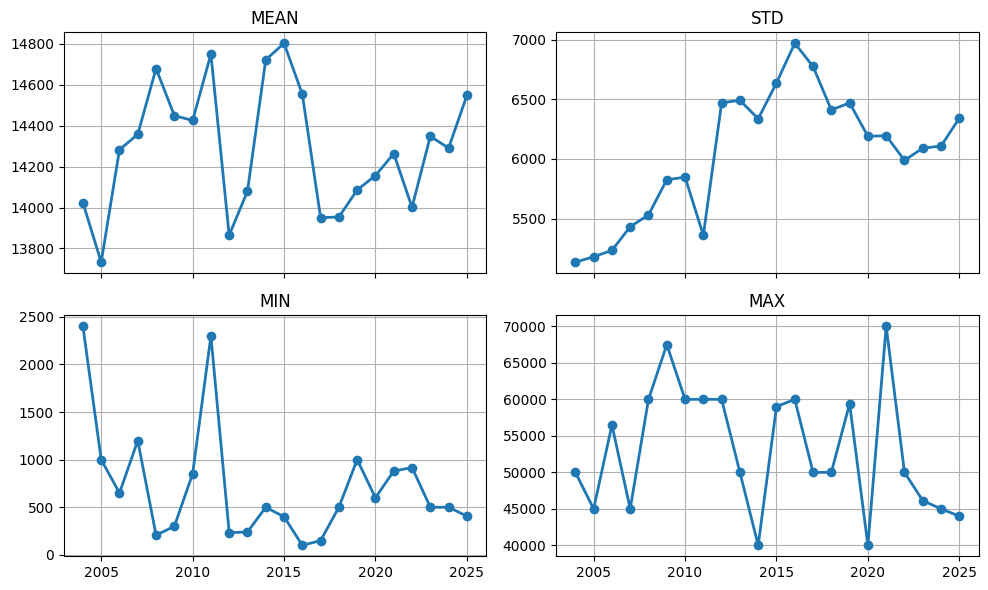

In [26]:
#graficos de comportamento do rendimento medio nos municipios do Brasil
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
metricas = ["mean", "std", "min", "max"]
for i, metrica in enumerate(metricas):
  ax = axes[i // 2, i % 2]
  ax.plot(estatisticas_por_ano.index, estatisticas_por_ano[metrica], marker="o", linewidth=2)
  ax.set_title(metrica.upper())
  ax.grid(True)
plt.tight_layout()
plt.show()

In [27]:
#Estatisticas da variavel Quantidade Producida
estatisticas_por_ano1 = df_calculos.groupby("ano")["mandioca_quantidade_produzida"].describe()
estatisticas_por_ano1

,count,mean,std,min,25%,50%,75%,max
ano,,,,,,,,
2004,3547.0,6037.312941,16758.468270,10.0,526.5,1656.0,5254.5,512000.0
2005,3547.0,6523.737807,19663.821501,9.0,525.0,1680.0,5400.0,720000.0
2006,3547.0,6761.758387,19205.800994,9.0,600.0,1800.0,5575.0,600000.0
2007,3547.0,6754.470538,21586.317775,15.0,600.0,1800.0,5612.5,900000.0
2008,3547.0,6783.382295,18889.193080,11.0,600.0,1800.0,5829.0,592000.0
2009,3547.0,6273.202707,18067.658153,6.0,560.0,1750.0,5000.0,592000.0
2010,3547.0,6412.842966,17147.650087,5.0,520.0,1600.0,5026.0,435600.0
2011,3547.0,6572.199323,18038.724494,4.0,525.0,1600.0,5100.0,414000.0
2012,3547.0,6030.397519,17267.678977,2.0,450.0,1350.0,4500.0,378000.0


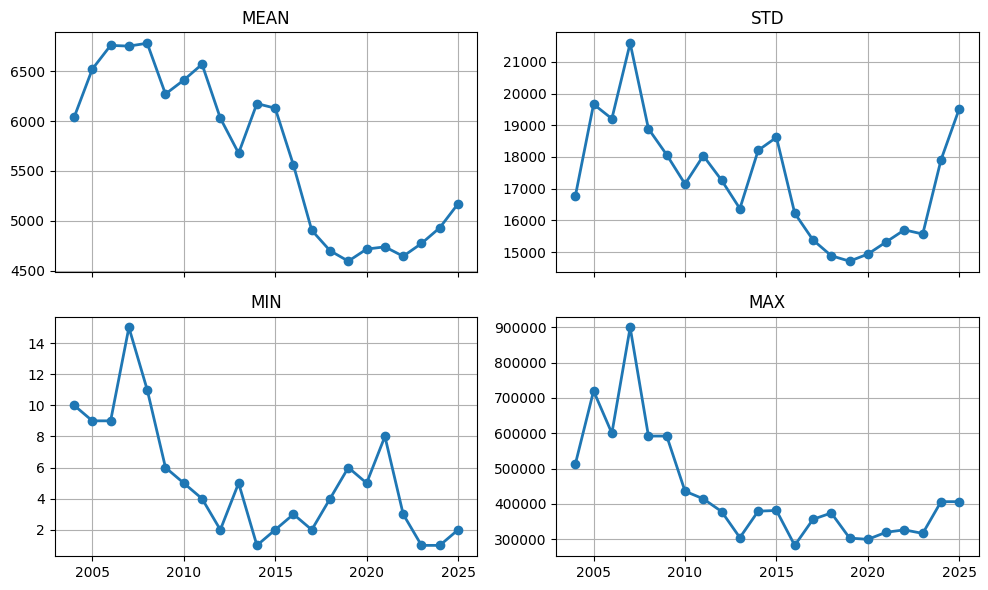

In [28]:
#graficos de comportamento da Quantidade Producida  nos municipios do Brasil
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
metricas1 = ["mean", "std", "min", "max"]
for i, metrica in enumerate(metricas1):
  ax = axes[i // 2, i % 2]
  ax.plot(estatisticas_por_ano1.index, estatisticas_por_ano1[metrica], marker="o", linewidth=2)
  ax.set_title(metrica.upper())
  ax.grid(True)
plt.tight_layout()
plt.show()

###Caracteristicas da Serie Temporal

Número de municipios: 3547
Años: 2004 - 2025
Número de observaciones: 78034


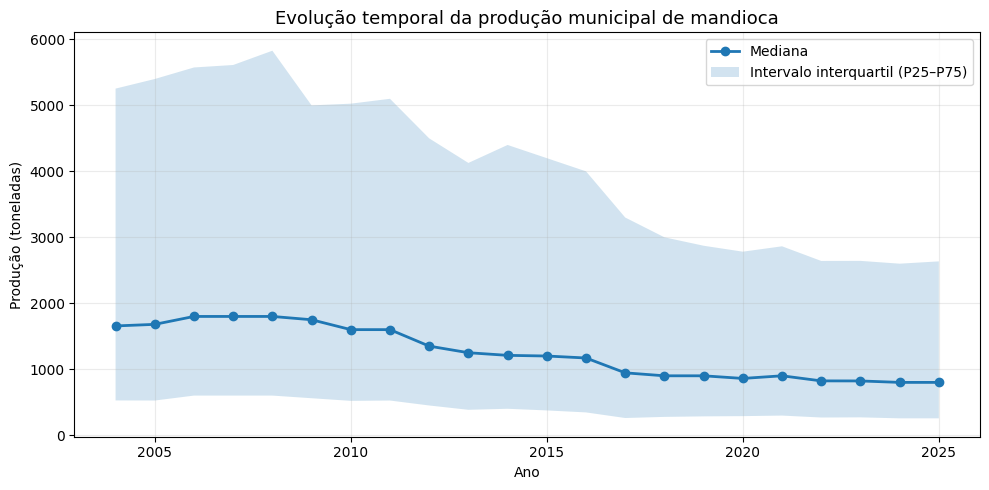

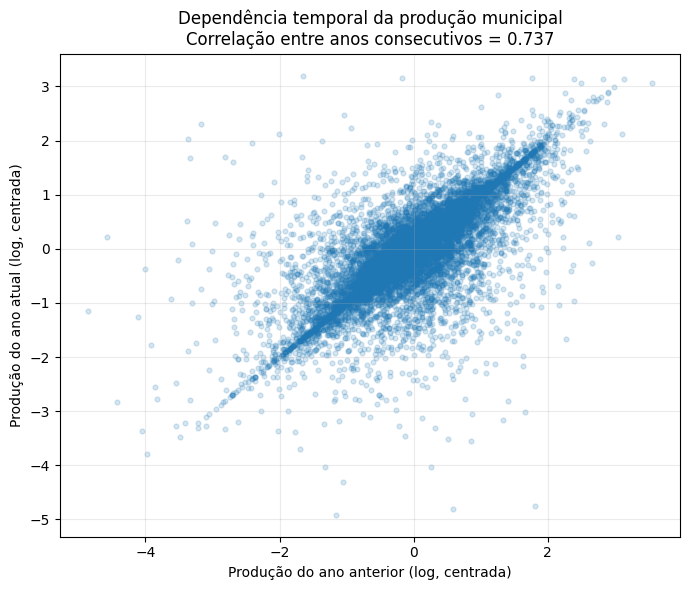

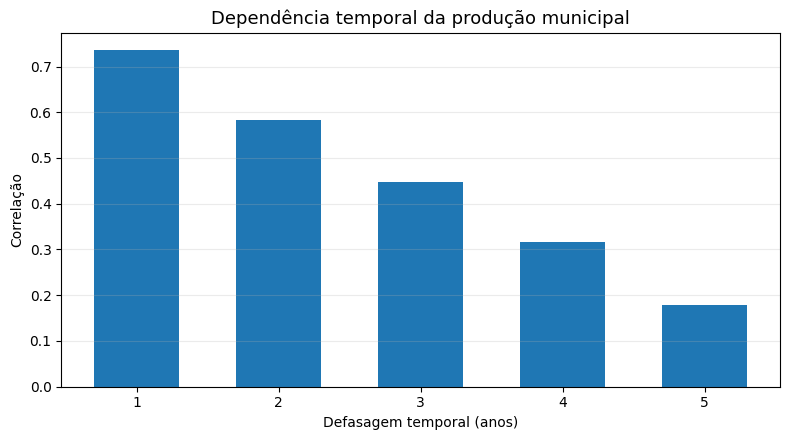


Correlações temporais:
   Lag  Correlacao
0    1    0.736775
1    2    0.583073
2    3    0.447274
3    4    0.315783
4    5    0.178881


In [29]:
df = df_limpo.copy()
df["ano"] = pd.to_numeric(df["ano"])
df["mandioca_quantidade_produzida"] = pd.to_numeric(df["mandioca_quantidade_produzida"])
df = df.sort_values(["CD_MUN", "ano"]).copy()
# Transformación logarítmica
df["log_producao"] = np.log1p(df["mandioca_quantidade_produzida"])
# Verificar estructura del panel
print("Número de municipios:", df["CD_MUN"].nunique())
print("Años:", df["ano"].min(), "-", df["ano"].max())
print("Número de observaciones:", len(df))
# Crear producción del año anterior para cada municipio
df["log_producao_lag1"] = (df.groupby("CD_MUN")["log_producao"].shift(1))
# GRÁFICO 1: EVOLUCIÓN TEMPORAL DE LA PRODUCCIÓN
# Mediana + intervalo intercuartílico
resumo = (df.groupby("ano")["mandioca_quantidade_produzida"].agg(mediana="median",q25=lambda x: x.quantile(0.25),q75=lambda x: x.quantile(0.75)).reset_index())
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(resumo["ano"],resumo["mediana"],marker="o",linewidth=2,label="Mediana")
ax.fill_between(resumo["ano"],resumo["q25"],resumo["q75"],alpha=0.20,label="Intervalo interquartil (P25–P75)")
ax.set_title("Evolução temporal da produção municipal de mandioca",fontsize=13)
ax.set_xlabel("Ano")
ax.set_ylabel("Produção (toneladas)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig("grafico_1_evolucao_temporal.png", dpi=300)
plt.show()
# GRÁFICO 2: PRODUÇÃO ATUAL VS. ANO ANTERIOR
# Centralização por município
# Restar la media histórica de cada municipio.
# Esto reduce la influencia de las diferencias permanentes
# de escala productiva entre municipios.
media_municipal = df.groupby("CD_MUN")["log_producao"].transform("mean")
df["log_producao_centrada"] = (df["log_producao"] - media_municipal)
df["lag1_centrada"] = (df["log_producao_lag1"] - media_municipal)
pares = df.dropna(subset=["log_producao_centrada", "lag1_centrada"]).copy()
# Muestra aleatoria para mejorar la legibilidad
amostra = pares.sample(n=min(15000, len(pares)),random_state=42)
correlacao_lag1 = pares[["lag1_centrada", "log_producao_centrada"]].corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(amostra["lag1_centrada"],amostra["log_producao_centrada"],alpha=0.18,s=12)
ax.set_title(f"Dependência temporal da produção municipal\n"f"Correlação entre anos consecutivos = {correlacao_lag1:.3f}",fontsize=12)
ax.set_xlabel("Produção do ano anterior (log, centrada)")
ax.set_ylabel("Produção do ano atual (log, centrada)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("grafico_2_dependencia_lag1.png", dpi=300)
plt.show()
# GRÁFICO 3: CORRELAÇÃO TEMPORAL POR DEFASAGEM
correlacoes = []
for lag in range(1, 6):
    df[f"log_lag{lag}"] = (df.groupby("CD_MUN")["log_producao"].shift(lag))
    # Centralizar usando la media del municipio
    df[f"log_lag{lag}_centrada"] = (df[f"log_lag{lag}"] - media_municipal)
    validos = df.dropna(subset=["log_producao_centrada",f"log_lag{lag}_centrada"])
    corr = validos[["log_producao_centrada",f"log_lag{lag}_centrada"]].corr().iloc[0, 1]
    correlacoes.append({
        "Lag": lag,
        "Correlacao": corr
    })

corr_df = pd.DataFrame(correlacoes)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(
    corr_df["Lag"].astype(str),
    corr_df["Correlacao"],
    width=0.6
)
ax.set_title(
    "Dependência temporal da produção municipal",
    fontsize=13
)
ax.set_xlabel("Defasagem temporal (anos)")
ax.set_ylabel("Correlação")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("grafico_3_correlacao_lags.png", dpi=300)
plt.show()

print("\nCorrelações temporais:")
print(corr_df)


In [30]:
resumo = (df_limpo.groupby("ano")["mandioca_quantidade_produzida"].agg(mediana="median",p25=lambda x: x.quantile(0.25),p75=lambda x: x.quantile(0.75),media="mean")    .round(2))
print(resumo.to_string())
print("\nVARIAÇÃO DA MEDIANA ENTRE 2004 E 2025:")
print(round((resumo.loc[2025, "mediana"] /resumo.loc[2004, "mediana"] - 1) * 100,2),"%")


      mediana    p25     p75    media
ano                                  
2004   1656.0  526.5  5254.5  6037.31
2005   1680.0  525.0  5400.0  6523.74
2006   1800.0  600.0  5575.0  6761.76
2007   1800.0  600.0  5612.5  6754.47
2008   1800.0  600.0  5829.0  6783.38
2009   1750.0  560.0  5000.0  6273.20
2010   1600.0  520.0  5026.0  6412.84
2011   1600.0  525.0  5100.0  6572.20
2012   1350.0  450.0  4500.0  6030.40
2013   1250.0  384.5  4127.5  5678.61
2014   1210.0  400.0  4400.0  6177.13
2015   1200.0  375.0  4200.0  6130.67
2016   1170.0  345.0  4000.0  5558.08
2017    945.0  260.0  3300.0  4903.86
2018    900.0  277.0  3000.0  4698.87
2019    900.0  285.0  2872.0  4593.91
2020    860.0  288.5  2782.0  4715.42
2021    900.0  297.0  2863.5  4737.73
2022    823.0  267.5  2641.5  4643.42
2023    822.0  270.0  2642.5  4771.91
2024    800.0  255.0  2600.0  4929.78
2025    800.0  255.0  2635.0  5170.70

VARIAÇÃO DA MEDIANA ENTRE 2004 E 2025:
-51.69 %


In [31]:
# Correlação temporal individual de cada município da variavel produção
correlacoes_municipais = (df_limpo.sort_values(["CD_MUN", "ano"]).assign(log_producao=lambda x: np.log1p(x["mandioca_quantidade_produzida"])).groupby("CD_MUN").apply(lambda g: g["log_producao"].corr(g["log_producao"].shift(1)),include_groups=False).dropna())
print("Municípios analisados:", len(correlacoes_municipais))
print("Correlação mediana:", round(correlacoes_municipais.median(), 3))
print("Correlação média:", round(correlacoes_municipais.mean(), 3))
print("Municípios com correlação positiva:",round((correlacoes_municipais > 0).mean() * 100, 2),"%")

Municípios analisados: 3545
Correlação mediana: 0.722
Correlação média: 0.657
Municípios com correlação positiva: 97.69 %


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [32]:
resumo = df_limpo.groupby('ano').agg(producao_mediana=('mandioca_quantidade_produzida', 'median'),
    producao_p25=('mandioca_quantidade_produzida',lambda x: x.quantile(0.25)),
    producao_p75=('mandioca_quantidade_produzida',lambda x: x.quantile(0.75)),
    area_mediana=('mandioca_area_colhida', 'median'),
    area_p25=('mandioca_area_colhida',lambda x: x.quantile(0.25)),
    area_p75=('mandioca_area_colhida',lambda x: x.quantile(0.75)),
    rendimento_mediana=('mandioca_rendimento_medio_da_producao', 'median'),
    rendimento_p25=('mandioca_rendimento_medio_da_producao',lambda x: x.quantile(0.25)),
    rendimento_p75=('mandioca_rendimento_medio_da_producao',lambda x: x.quantile(0.75)))
print(resumo.head())

      producao_mediana  producao_p25  producao_p75  area_mediana  area_p25  \
ano                                                                          
2004            1656.0         526.5        5254.5         120.0      40.0   
2005            1680.0         525.0        5400.0         130.0      40.0   
2006            1800.0         600.0        5575.0         130.0      45.0   
2007            1800.0         600.0        5612.5         130.0      45.0   
2008            1800.0         600.0        5829.0         123.0      45.0   

      area_p75  rendimento_mediana  rendimento_p25  rendimento_p75  
ano                                                                 
2004     400.0             13400.0         10000.0         16454.0  
2005     400.0             13000.0         10000.0         16500.0  
2006     400.0             14000.0         10000.0         18000.0  
2007     400.0             14000.0         10000.0         18000.0  
2008     400.0             14000.0     

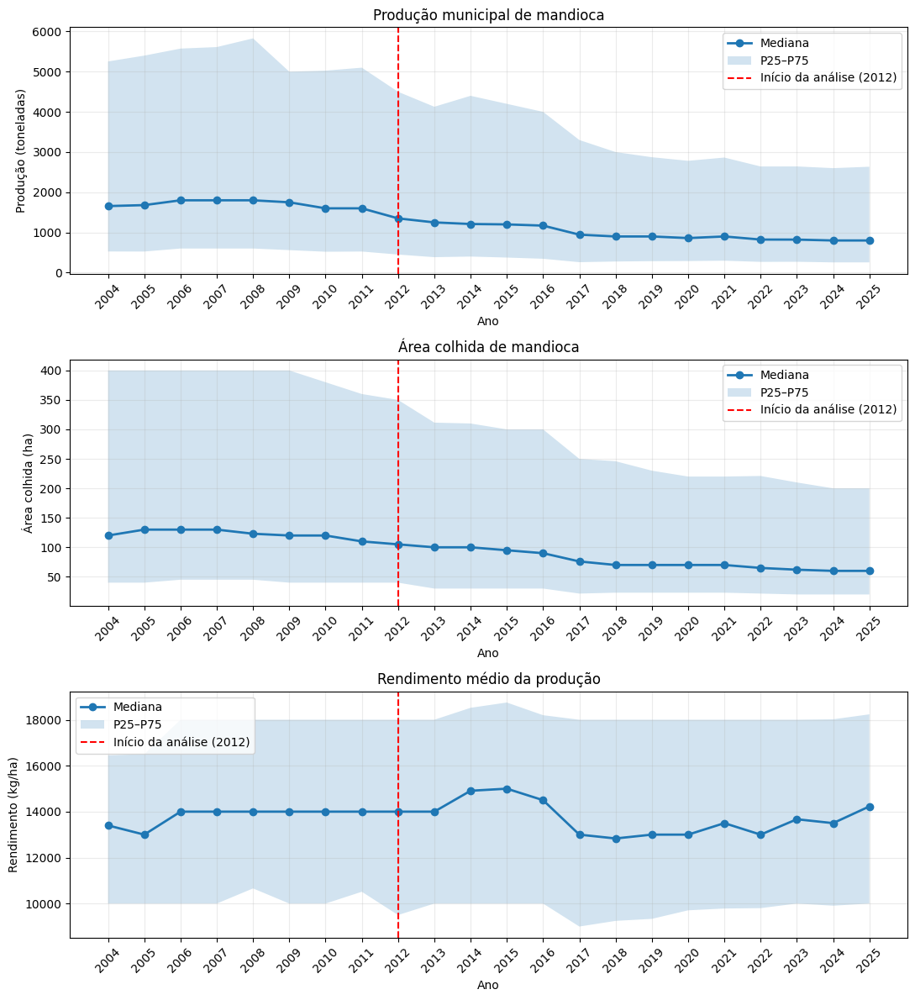

In [33]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 1, figsize=(11, 12))
graficos = [('producao_mediana', 'producao_p25', 'producao_p75','Produção municipal de mandioca', 'Produção (toneladas)'),
    ('area_mediana', 'area_p25', 'area_p75','Área colhida de mandioca', 'Área colhida (ha)'),
    ('rendimento_mediana', 'rendimento_p25', 'rendimento_p75','Rendimento médio da produção', 'Rendimento (kg/ha)')]
for ax, (med, p25, p75, titulo, ylabel) in zip(axes, graficos):
    ax.plot(resumo.index,resumo[med],marker='o',linewidth=2,label='Mediana')
    ax.fill_between(resumo.index,resumo[p25],resumo[p75],alpha=0.20,label='P25–P75')
    ax.axvline(2012,color='red',linestyle='--',linewidth=1.5,label='Início da análise (2012)')
    ax.set_title(titulo)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Ano')
    ax.set_xticks(resumo.index)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.savefig('evolucao_variaveis_agricolas.png',dpi=300,bbox_inches='tight')
plt.show()


In [34]:
#Eliminhar coluna rendimento medio da producao porque não vamos usar
if 'mandioca_rendimento_medio_da_producao' in df_limpo.columns:df_limpo = df_limpo.drop(columns=['mandioca_rendimento_medio_da_producao'])

In [35]:
df_limpo

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado,mandioca_area_colhida,mandioca_quantidade_produzida
0,1100015,Alta Floresta D'Oeste,RO,2004,25.130340,26.859967,22.491399,4.368568,25.733199,2102.956146,5498.235192,216.557085,148.442915,40.128399,27.655822,5522.230523,330.0,5280.0
1,1100015,Alta Floresta D'Oeste,RO,2005,25.205282,26.202438,23.991913,2.210524,25.826099,1812.055309,5549.610474,209.516935,154.483065,37.511591,26.139622,5537.437287,363.0,5808.0
2,1100015,Alta Floresta D'Oeste,RO,2006,25.290423,27.078269,23.081006,3.997263,25.889101,1929.950281,5514.410769,211.301423,152.698577,53.959650,38.245708,5568.145447,363.0,5808.0
3,1100015,Alta Floresta D'Oeste,RO,2007,25.412480,27.857154,23.620890,4.236263,26.069184,1825.285015,5686.150070,207.029327,156.970673,48.675463,35.418799,5609.496178,363.0,5808.0
4,1100015,Alta Floresta D'Oeste,RO,2008,25.159632,26.986060,23.388220,3.597840,25.772509,1913.044929,5501.357809,202.015365,162.984635,41.174895,39.247044,5535.349816,363.0,5808.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122359,5300108,Brasília,DF,2021,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,5982.696234,138.110941,225.889059,118.493564,27.628238,4374.144006,1250.0,20550.0
122360,5300108,Brasília,DF,2022,21.825986,24.365739,19.632260,4.733479,23.319608,1168.176199,6110.781925,130.020274,233.979726,127.478681,28.213194,4303.674086,1250.0,20550.0
122361,5300108,Brasília,DF,2023,22.686715,25.493550,19.976125,5.517425,24.103749,992.992519,6305.872794,130.250523,233.749477,69.132100,14.716090,4616.105932,1250.0,20550.0
122362,5300108,Brasília,DF,2024,22.448566,25.403966,20.055076,5.348890,23.878355,1490.313758,6016.516024,153.008286,211.991714,178.472566,31.946661,4545.067863,883.0,19154.0


In [36]:
df_limpo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 78034 entries, 0 to 122363
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CD_MUN                         78034 non-null  object 
 1   NM_MUN                         78034 non-null  object 
 2   SIGLA_UF                       78034 non-null  object 
 3   ano                            78034 non-null  int64  
 4   temp_mean                      78034 non-null  float64
 5   temp_max                       78034 non-null  float64
 6   temp_min                       78034 non-null  float64
 7   amplitud_termica               78034 non-null  float64
 8   temp_soil_mean                 78034 non-null  float64
 9   precip_total_mm                78034 non-null  float64
 10  rad_solar_MJm2                 78034 non-null  float64
 11  dias_lluviosos                 78034 non-null  float64
 12  dias_secos                     78034 non-null  flo

### Corte temporal para analises final desde 2012 ate 2025

In [37]:
#corte temporal 2012 ate 2025 com lag t-1
#Corte temporal de acordo ao analises de mundanca da productividade e da producao no intervalo 2004-2025
df_limpo = df_limpo.sort_values(by=['CD_MUN', 'ano']).reset_index(drop=True)
df_limpo['producao_lag1'] = df_limpo.groupby('CD_MUN')['mandioca_quantidade_produzida'].shift(1)
df_acr = df_limpo[df_limpo['ano'] >= 2012].copy().reset_index(drop=True)
df_acr.to_csv('df_acr_consolidado.csv', index=False)
df_acr

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado,mandioca_area_colhida,mandioca_quantidade_produzida,producao_lag1
0,1100015,Alta Floresta D'Oeste,RO,2012,25.300989,27.635776,23.956721,3.679055,25.910236,1859.126705,5605.210674,215.418264,149.581736,59.296813,33.496226,5585.223773,546.0,8736.0,6720.0
1,1100015,Alta Floresta D'Oeste,RO,2013,24.922070,26.164826,23.934008,2.230818,25.524709,2055.736989,5372.045575,240.076091,123.923909,42.533436,36.212172,5431.407427,546.0,10920.0,8736.0
2,1100015,Alta Floresta D'Oeste,RO,2014,25.142517,27.251599,23.878290,3.373309,25.713396,2171.786559,5341.926471,233.970940,130.029060,36.098604,52.534905,5512.897165,566.0,11320.0,10920.0
3,1100015,Alta Floresta D'Oeste,RO,2015,25.977802,28.265103,24.256374,4.008729,26.604156,1813.641147,5644.196873,226.318124,137.681876,41.931926,52.948761,5817.049286,566.0,11320.0,11320.0
4,1100015,Alta Floresta D'Oeste,RO,2016,25.505128,26.392511,24.139770,2.252742,26.149057,1956.590009,5524.780151,212.235086,152.764914,63.360144,27.007549,5659.754434,566.0,11320.0,11320.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49653,5300108,Brasília,DF,2021,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,5982.696234,138.110941,225.889059,118.493564,27.628238,4374.144006,1250.0,20550.0,20550.0
49654,5300108,Brasília,DF,2022,21.825986,24.365739,19.632260,4.733479,23.319608,1168.176199,6110.781925,130.020274,233.979726,127.478681,28.213194,4303.674086,1250.0,20550.0,20550.0
49655,5300108,Brasília,DF,2023,22.686715,25.493550,19.976125,5.517425,24.103749,992.992519,6305.872794,130.250523,233.749477,69.132100,14.716090,4616.105932,1250.0,20550.0,20550.0
49656,5300108,Brasília,DF,2024,22.448566,25.403966,20.055076,5.348890,23.878355,1490.313758,6016.516024,153.008286,211.991714,178.472566,31.946661,4545.067863,883.0,19154.0,20550.0


In [38]:
df_acr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49658 entries, 0 to 49657
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CD_MUN                         49658 non-null  object 
 1   NM_MUN                         49658 non-null  object 
 2   SIGLA_UF                       49658 non-null  object 
 3   ano                            49658 non-null  int64  
 4   temp_mean                      49658 non-null  float64
 5   temp_max                       49658 non-null  float64
 6   temp_min                       49658 non-null  float64
 7   amplitud_termica               49658 non-null  float64
 8   temp_soil_mean                 49658 non-null  float64
 9   precip_total_mm                49658 non-null  float64
 10  rad_solar_MJm2                 49658 non-null  float64
 11  dias_lluviosos                 49658 non-null  float64
 12  dias_secos                     49658 non-null 

# Analises exploratorio do Dataframe Final (com variaveis : pdn e clima)





In [39]:
# metricas avaliadas por municipio no periodo  (2012-2025) Para fazer analisis de mapas
df_resumo_muni = df_acr.groupby(['CD_MUN', 'NM_MUN', 'SIGLA_UF']).agg(
    prod_media=('mandioca_quantidade_produzida', 'mean'),
    prod_total=('mandioca_quantidade_produzida', 'sum'),
    prod_std=('mandioca_quantidade_produzida', 'std'),
    precip_media=('precip_total_mm', 'mean'),
    temp_media=('temp_mean', 'mean')
).reset_index()
# Coeficiente de Variacao(%)
df_resumo_muni['prod_cv'] = (df_resumo_muni['prod_std'] / df_resumo_muni['prod_media']) * 100
df_resumo_muni['CD_MUN'] = df_resumo_muni['CD_MUN'].astype(str).str.strip()
df_resumo_muni

,CD_MUN,NM_MUN,SIGLA_UF,prod_media,prod_total,prod_std,precip_media,temp_media,prod_cv
0,1100015,Alta Floresta D'Oeste,RO,9874.000000,138236.0,2153.848648,1796.715986,25.643999,21.813334
1,1100023,Ariquemes,RO,6688.214286,93635.0,4546.708703,2073.966773,26.171078,67.980907
2,1100031,Cabixi,RO,719.428571,10072.0,441.465168,1538.798283,25.629929,61.363308
3,1100049,Cacoal,RO,11354.000000,158956.0,6954.532379,1863.673985,25.941445,61.251826
4,1100056,Cerejeiras,RO,2337.000000,32718.0,455.976383,1623.601548,25.972175,19.511185
...,...,...,...,...,...,...,...,...,...
3542,5221809,Urutaí,GO,220.142857,3082.0,215.163214,1103.908237,23.559111,97.737995
3543,5221908,Varjão,GO,400.285714,5604.0,248.053477,1199.342417,24.753277,61.969106
3544,5222005,Vianópolis,GO,1332.285714,18652.0,1090.354807,1347.010408,23.002729,81.840914
3545,5222203,Vila Boa,GO,383.642857,5371.0,319.914558,1067.663836,25.027427,83.388639


### Inclussão Data Frame Geometry

In [40]:
malha_mun= gpd.read_file("BR_Municipios_2025.shp")
malha_mun

,CD_MUN,NM_MUN,CD_RGI,NM_RGI,CD_RGINT,NM_RGINT,CD_UF,NM_UF,SIGLA_UF,CD_REGIAO,NM_REGIAO,SIGLA_RG,CD_CONCURB,NM_CONCURB,AREA_KM2,geometry
0,2410900,Riachuelo,240006,São Paulo do Potengi,2401,Natal,24,Rio Grande do Norte,RN,2,Nordeste,NE,None,None,262.880,"POLYGON ((-35.78413 -5.82524, -35.79682 -5.853..."
1,4202438,Bocaina do Sul,420005,Lages,4203,Lages,42,Santa Catarina,SC,4,Sul,S,None,None,510.673,"POLYGON ((-49.91152 -27.85242, -49.91152 -27.8..."
2,4316204,Rondinha,430028,Carazinho,4306,Passo Fundo,43,Rio Grande do Sul,RS,4,Sul,S,None,None,252.454,"POLYGON ((-52.77871 -27.85295, -52.76015 -27.8..."
3,3118205,Conquista,310055,Uberaba,3110,Uberaba,31,Minas Gerais,MG,3,Sudeste,SE,None,None,618.363,"POLYGON ((-47.59239 -20.00701, -47.59398 -20.0..."
4,3110806,Campanário,310013,Teófilo Otoni,3103,Teófilo Otoni,31,Minas Gerais,MG,3,Sudeste,SE,None,None,442.398,"POLYGON ((-41.80297 -18.41975, -41.80291 -18.4..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5568,1302108,Japurá,130005,Tefé,1302,Tefé,13,Amazonas,AM,1,Norte,N,None,None,55964.231,"POLYGON ((-69.0667 -2.8291, -69.06693 -2.82915..."
5569,1300706,Boca do Acre,130008,Lábrea,1303,Lábrea,13,Amazonas,AM,1,Norte,N,None,None,21949.686,"POLYGON ((-67.29523 -9.4496, -67.29522 -9.4498..."
5570,1302405,Lábrea,130008,Lábrea,1303,Lábrea,13,Amazonas,AM,1,Norte,N,None,None,68349.909,"POLYGON ((-66.12389 -9.40878, -66.12927 -9.410..."
5571,1301852,Iranduba,130001,Manaus,1301,Manaus,13,Amazonas,AM,1,Norte,N,None,None,2331.676,"POLYGON ((-60.31639 -3.27207, -60.3155 -3.2712..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

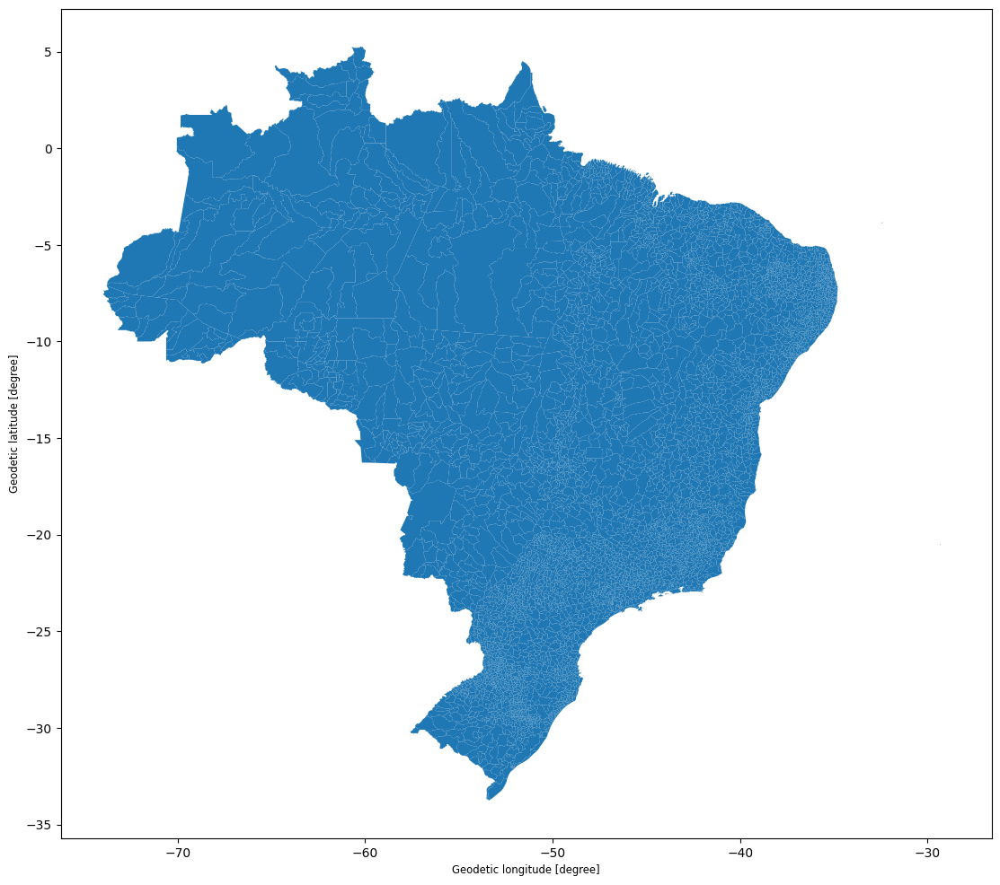

In [41]:
malha_mun.plot(figsize=(20,12))

In [42]:
#merge malha municipal - metricas avaliadas 2012-2025
df_resumo_muni['CD_MUN'] = df_resumo_muni['CD_MUN'].astype(str).str.strip()
malha_mun['CD_MUN'] = malha_mun['CD_MUN'].astype(str).str.strip()
gdf_mapa = malha_mun.merge(df_resumo_muni, on='CD_MUN', how='inner')

### Analises de Mapas con variaveis brutas

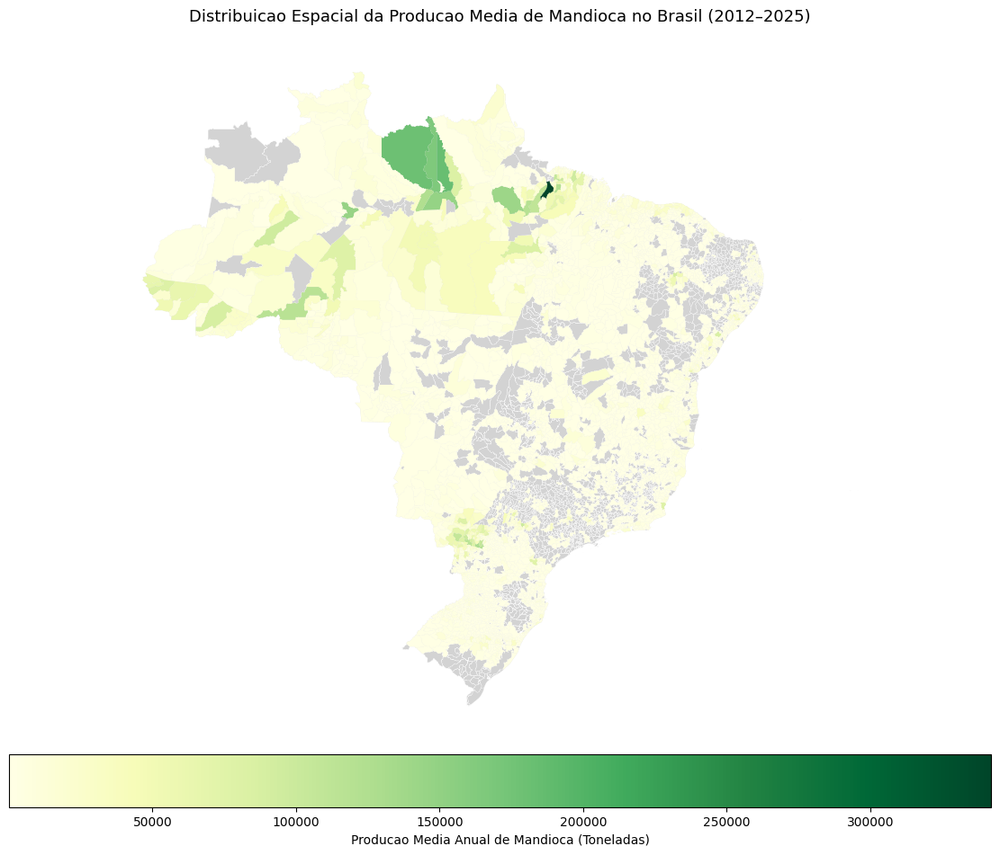

In [43]:
#Analisis de Mapas
#Mapas con produção media
fig, ax = plt.subplots(1, 1, figsize=(12, 10))
malha_mun.plot(ax=ax, color='lightgrey', edgecolor='white', linewidth=0.2)
gdf_mapa.plot(column='prod_media',cmap='YlGn',legend=True,legend_kwds={'label': "Producao Media Anual de Mandioca (Toneladas)", 'orientation': "horizontal", 'pad': 0.02},ax=ax,edgecolor='none')
ax.set_title('Distribuicao Espacial da Producao Media de Mandioca no Brasil (2012–2025)', fontsize=13, pad=15)
ax.axis('off')
plt.tight_layout()
plt.show()

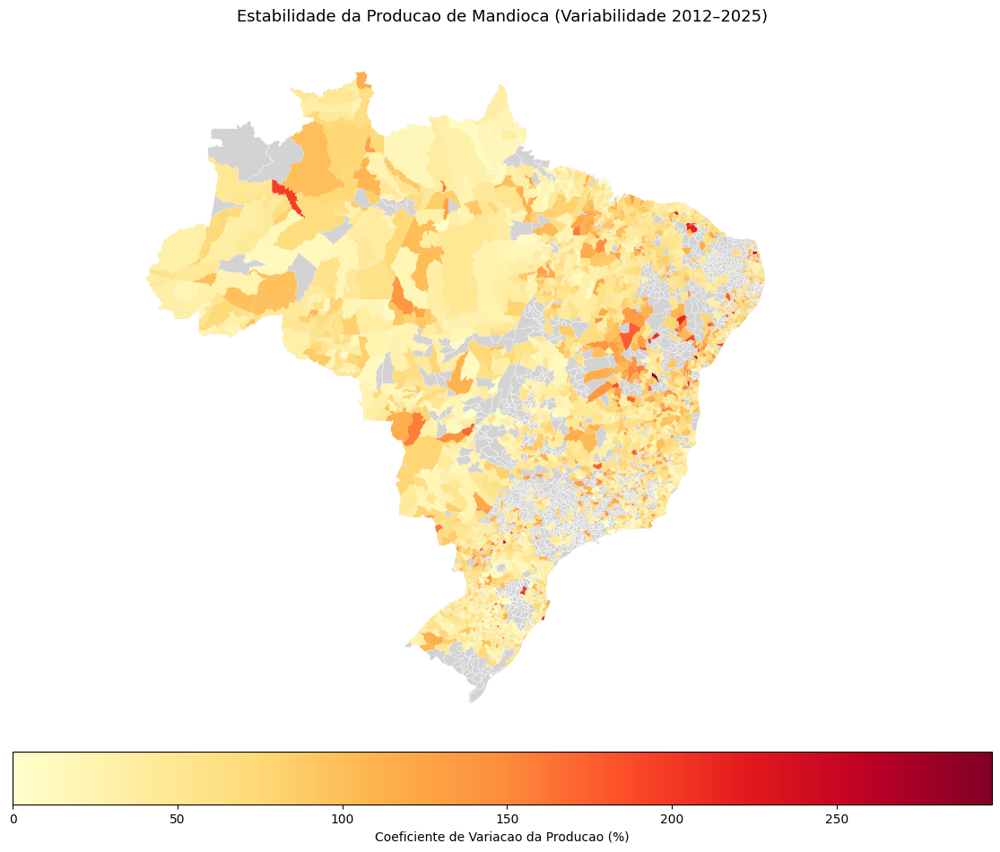

In [44]:
#mapa risco agricola cv
fig, ax = plt.subplots(1, 1, figsize=(12, 10))
malha_mun.plot(ax=ax, color='lightgrey', edgecolor='white', linewidth=0.2)
gdf_mapa.plot(column='prod_cv',cmap='YlOrRd',legend=True,legend_kwds={'label': "Coeficiente de Variacao da Producao (%)", 'orientation': "horizontal", 'pad': 0.02},ax=ax,edgecolor='none')
ax.set_title('Estabilidade da Producao de Mandioca (Variabilidade 2012–2025)', fontsize=13, pad=15)
ax.axis('off')
plt.tight_layout()
plt.show()

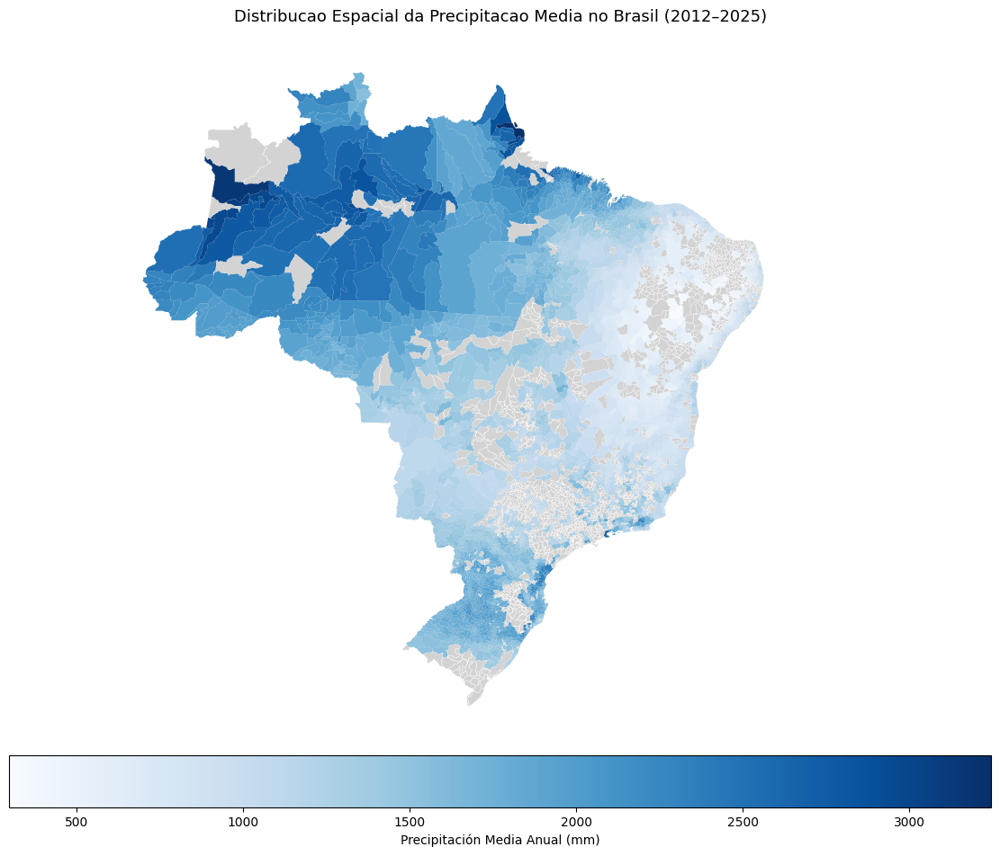

In [45]:
#mapa gradiente climatico precipitacao/ t media
fig, ax = plt.subplots(1, 1, figsize=(12, 10))
malha_mun.plot(ax=ax, color='lightgrey', edgecolor='white', linewidth=0.2)
gdf_mapa.plot(column='precip_media',cmap='Blues',legend=True,legend_kwds={'label': "Precipitación Media Anual (mm)", 'orientation': "horizontal", 'pad': 0.02},ax=ax,edgecolor='none')
ax.set_title('Distribucao Espacial da Precipitacao Media no Brasil (2012–2025)', fontsize=13, pad=15)
ax.axis('off')
plt.tight_layout()
plt.show()

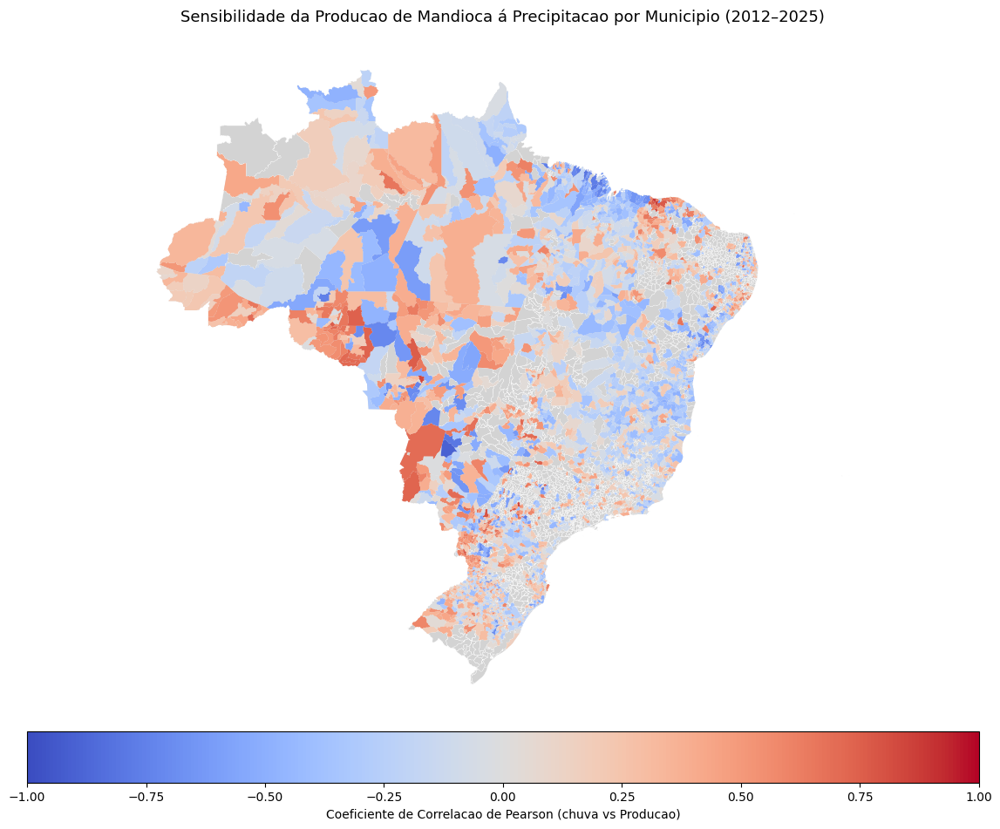

In [46]:
#mapa correlacao chuva/produção
def calc_corr(group):
    if len(group) < 3 or group['mandioca_quantidade_produzida'].std() == 0 or group['precip_total_mm'].std() == 0:
        return np.nan
    return group['mandioca_quantidade_produzida'].corr(group['precip_total_mm'])
correlaciones = df_acr.groupby('CD_MUN').apply(calc_corr, include_groups=False).reset_index(name='corr_lluvia_prod')
df_resumo_muni['CD_MUN'] = df_resumo_muni['CD_MUN'].astype(str).str.strip()
correlaciones['CD_MUN'] = correlaciones['CD_MUN'].astype(str).str.strip()
malha_mun['CD_MUN'] = malha_mun['CD_MUN'].astype(str).str.strip()
gdf_mapa_corr = malha_mun.merge(correlaciones, on='CD_MUN', how='inner')
fig, ax = plt.subplots(1, 1, figsize=(12, 10))
malha_mun.plot(ax=ax, color='lightgrey', edgecolor='white', linewidth=0.2)
gdf_mapa_corr.plot(column='corr_lluvia_prod',cmap='coolwarm',vmin=-1,vmax=1,legend=True,legend_kwds={'label': "Coeficiente de Correlacao de Pearson (chuva vs Producao)", 'orientation': "horizontal", 'pad': 0.02},ax=ax,edgecolor='none')
ax.set_title('Sensibilidade da Producao de Mandioca á Precipitacao por Municipio (2012–2025)', fontsize=13, pad=15)
ax.axis('off')
plt.tight_layout()
plt.show()

# Procesamento de dados

In [47]:
df_acr

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado,mandioca_area_colhida,mandioca_quantidade_produzida,producao_lag1
0,1100015,Alta Floresta D'Oeste,RO,2012,25.300989,27.635776,23.956721,3.679055,25.910236,1859.126705,5605.210674,215.418264,149.581736,59.296813,33.496226,5585.223773,546.0,8736.0,6720.0
1,1100015,Alta Floresta D'Oeste,RO,2013,24.922070,26.164826,23.934008,2.230818,25.524709,2055.736989,5372.045575,240.076091,123.923909,42.533436,36.212172,5431.407427,546.0,10920.0,8736.0
2,1100015,Alta Floresta D'Oeste,RO,2014,25.142517,27.251599,23.878290,3.373309,25.713396,2171.786559,5341.926471,233.970940,130.029060,36.098604,52.534905,5512.897165,566.0,11320.0,10920.0
3,1100015,Alta Floresta D'Oeste,RO,2015,25.977802,28.265103,24.256374,4.008729,26.604156,1813.641147,5644.196873,226.318124,137.681876,41.931926,52.948761,5817.049286,566.0,11320.0,11320.0
4,1100015,Alta Floresta D'Oeste,RO,2016,25.505128,26.392511,24.139770,2.252742,26.149057,1956.590009,5524.780151,212.235086,152.764914,63.360144,27.007549,5659.754434,566.0,11320.0,11320.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49653,5300108,Brasília,DF,2021,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,5982.696234,138.110941,225.889059,118.493564,27.628238,4374.144006,1250.0,20550.0,20550.0
49654,5300108,Brasília,DF,2022,21.825986,24.365739,19.632260,4.733479,23.319608,1168.176199,6110.781925,130.020274,233.979726,127.478681,28.213194,4303.674086,1250.0,20550.0,20550.0
49655,5300108,Brasília,DF,2023,22.686715,25.493550,19.976125,5.517425,24.103749,992.992519,6305.872794,130.250523,233.749477,69.132100,14.716090,4616.105932,1250.0,20550.0,20550.0
49656,5300108,Brasília,DF,2024,22.448566,25.403966,20.055076,5.348890,23.878355,1490.313758,6016.516024,153.008286,211.991714,178.472566,31.946661,4545.067863,883.0,19154.0,20550.0


In [48]:
df_acr.columns

Index(['CD_MUN', 'NM_MUN', 'SIGLA_UF', 'ano', 'temp_mean', 'temp_max',
       'temp_min', 'amplitud_termica', 'temp_soil_mean', 'precip_total_mm',
       'rad_solar_MJm2', 'dias_lluviosos', 'dias_secos', 'CDD_dias',
       'CWD_dias', 'GDD_acumulado', 'mandioca_area_colhida',
       'mandioca_quantidade_produzida', 'producao_lag1'],
      dtype='object')

In [49]:
#indies calculados manualmente em Era 5
df_Ic = df_acr[['NM_MUN','dias_lluviosos', 'dias_secos', 'CDD_dias', 'CWD_dias', 'GDD_acumulado']].copy()
df_Ic

,NM_MUN,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado
0,Alta Floresta D'Oeste,215.418264,149.581736,59.296813,33.496226,5585.223773
1,Alta Floresta D'Oeste,240.076091,123.923909,42.533436,36.212172,5431.407427
2,Alta Floresta D'Oeste,233.970940,130.029060,36.098604,52.534905,5512.897165
3,Alta Floresta D'Oeste,226.318124,137.681876,41.931926,52.948761,5817.049286
4,Alta Floresta D'Oeste,212.235086,152.764914,63.360144,27.007549,5659.754434
...,...,...,...,...,...,...
49653,Brasília,138.110941,225.889059,118.493564,27.628238,4374.144006
49654,Brasília,130.020274,233.979726,127.478681,28.213194,4303.674086
49655,Brasília,130.250523,233.749477,69.132100,14.716090,4616.105932
49656,Brasília,153.008286,211.991714,178.472566,31.946661,4545.067863


## Divisao treino/teste

In [50]:
# Asegurar orden cronológico
df_acr = df_acr.sort_values(['CD_MUN', 'ano']).reset_index(drop=True)
df_acr_train = df_acr[df_acr['ano'] <= 2022].copy()
df_acr_test  = df_acr[df_acr['ano'] >= 2023].copy()

In [51]:
df_acr_train

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado,mandioca_area_colhida,mandioca_quantidade_produzida,producao_lag1
0,1100015,Alta Floresta D'Oeste,RO,2012,25.300989,27.635776,23.956721,3.679055,25.910236,1859.126705,5605.210674,215.418264,149.581736,59.296813,33.496226,5585.223773,546.0,8736.0,6720.0
1,1100015,Alta Floresta D'Oeste,RO,2013,24.922070,26.164826,23.934008,2.230818,25.524709,2055.736989,5372.045575,240.076091,123.923909,42.533436,36.212172,5431.407427,546.0,10920.0,8736.0
2,1100015,Alta Floresta D'Oeste,RO,2014,25.142517,27.251599,23.878290,3.373309,25.713396,2171.786559,5341.926471,233.970940,130.029060,36.098604,52.534905,5512.897165,566.0,11320.0,10920.0
3,1100015,Alta Floresta D'Oeste,RO,2015,25.977802,28.265103,24.256374,4.008729,26.604156,1813.641147,5644.196873,226.318124,137.681876,41.931926,52.948761,5817.049286,566.0,11320.0,11320.0
4,1100015,Alta Floresta D'Oeste,RO,2016,25.505128,26.392511,24.139770,2.252742,26.149057,1956.590009,5524.780151,212.235086,152.764914,63.360144,27.007549,5659.754434,566.0,11320.0,11320.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49650,5300108,Brasília,DF,2018,22.191870,24.604679,20.349522,4.255158,23.562559,1184.609098,5969.488376,141.102414,222.897586,92.555350,20.173290,4439.511338,1250.0,20550.0,17400.0
49651,5300108,Brasília,DF,2019,23.001519,25.806558,19.907067,5.899491,24.427089,918.055084,6287.463566,123.631858,240.368142,131.712792,22.931134,4729.407990,1250.0,20550.0,20550.0
49652,5300108,Brasília,DF,2020,21.986999,24.838238,19.690853,5.147384,23.367886,1285.613541,6046.755987,142.792438,222.207562,118.694932,16.284232,4371.839968,1250.0,20550.0,20550.0
49653,5300108,Brasília,DF,2021,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,5982.696234,138.110941,225.889059,118.493564,27.628238,4374.144006,1250.0,20550.0,20550.0


In [52]:
df_acr_test

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado,mandioca_area_colhida,mandioca_quantidade_produzida,producao_lag1
11,1100015,Alta Floresta D'Oeste,RO,2023,26.340655,29.199457,23.661264,5.538194,26.975958,1547.503702,5742.252513,183.042087,180.957913,57.834057,34.704189,5951.313173,406.0,8120.0,10180.0
12,1100015,Alta Floresta D'Oeste,RO,2024,26.616472,29.704943,24.948175,4.756768,27.336293,1341.229123,5881.539270,158.355802,206.644198,92.868194,19.102345,6064.343647,330.0,4920.0,8120.0
13,1100015,Alta Floresta D'Oeste,RO,2025,25.569167,27.748781,24.239610,3.509171,26.226010,1783.069430,5572.510344,202.974815,161.025185,41.637785,26.843209,5664.175263,330.0,5940.0,4920.0
25,1100023,Ariquemes,RO,2023,26.620591,29.125944,24.776052,4.349892,27.208763,1826.905083,5551.130595,200.688937,163.311063,58.470065,38.511931,6053.565297,105.0,2775.0,2775.0
26,1100023,Ariquemes,RO,2024,27.178955,30.409363,25.880094,4.529269,27.831672,1661.501575,5592.463832,173.653145,191.346855,113.791323,23.917679,6271.168828,115.0,2825.0,2775.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49642,5222203,Vila Boa,GO,2024,24.944101,27.210372,22.283087,4.927284,26.384295,1382.749484,6127.764612,129.708500,235.291500,177.521584,15.790832,5457.069259,8.0,148.0,96.0
49643,5222203,Vila Boa,GO,2025,25.137964,27.122509,22.292075,4.830434,26.741761,732.861036,6284.815879,97.099688,266.900312,142.306631,14.769470,5505.971731,6.0,75.0,148.0
49655,5300108,Brasília,DF,2023,22.686715,25.493550,19.976125,5.517425,24.103749,992.992519,6305.872794,130.250523,233.749477,69.132100,14.716090,4616.105932,1250.0,20550.0,20550.0
49656,5300108,Brasília,DF,2024,22.448566,25.403966,20.055076,5.348890,23.878355,1490.313758,6016.516024,153.008286,211.991714,178.472566,31.946661,4545.067863,883.0,19154.0,20550.0


In [53]:
df_acr_train.columns

Index(['CD_MUN', 'NM_MUN', 'SIGLA_UF', 'ano', 'temp_mean', 'temp_max',
       'temp_min', 'amplitud_termica', 'temp_soil_mean', 'precip_total_mm',
       'rad_solar_MJm2', 'dias_lluviosos', 'dias_secos', 'CDD_dias',
       'CWD_dias', 'GDD_acumulado', 'mandioca_area_colhida',
       'mandioca_quantidade_produzida', 'producao_lag1'],
      dtype='object')

###Analises Univariado e Multivariado

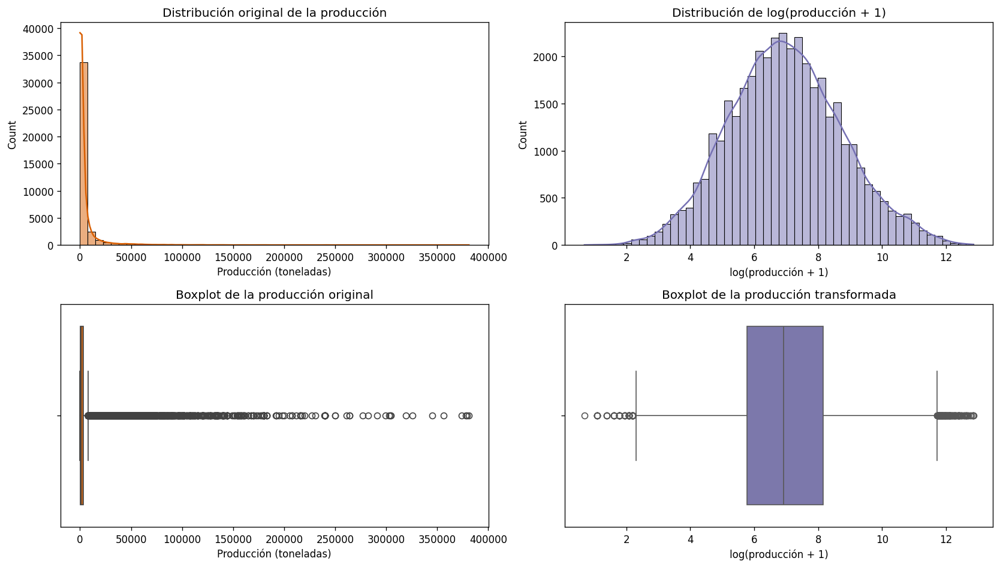

Estadísticas descriptivas de las variables climáticas


,count,mean,std,min,25%,50%,75%,max
temp_mean,39017.0,23.225,3.081,15.387,20.592,23.625,25.859,29.832
temp_max,39017.0,26.318,2.371,18.957,24.569,26.420,28.092,32.710
temp_min,39017.0,19.869,4.570,8.280,15.951,20.591,24.150,27.654
amplitud_termica,39017.0,6.448,2.985,0.723,4.154,5.608,8.625,17.557
temp_soil_mean,39017.0,24.507,3.509,15.944,21.482,24.980,27.247,32.910
precip_total_mm,39017.0,1335.257,565.502,88.733,919.643,1304.222,1680.975,4148.447
rad_solar_MJm2,39017.0,5591.559,536.812,1316.701,5289.484,5580.479,5921.086,7052.556
dias_lluviosos,39017.0,155.135,49.411,17.238,123.016,149.372,182.776,339.498
dias_secos,39017.0,209.138,49.448,24.502,181.491,214.826,241.288,347.762
CDD_dias,39017.0,46.386,40.981,2.675,16.011,27.025,67.207,225.767


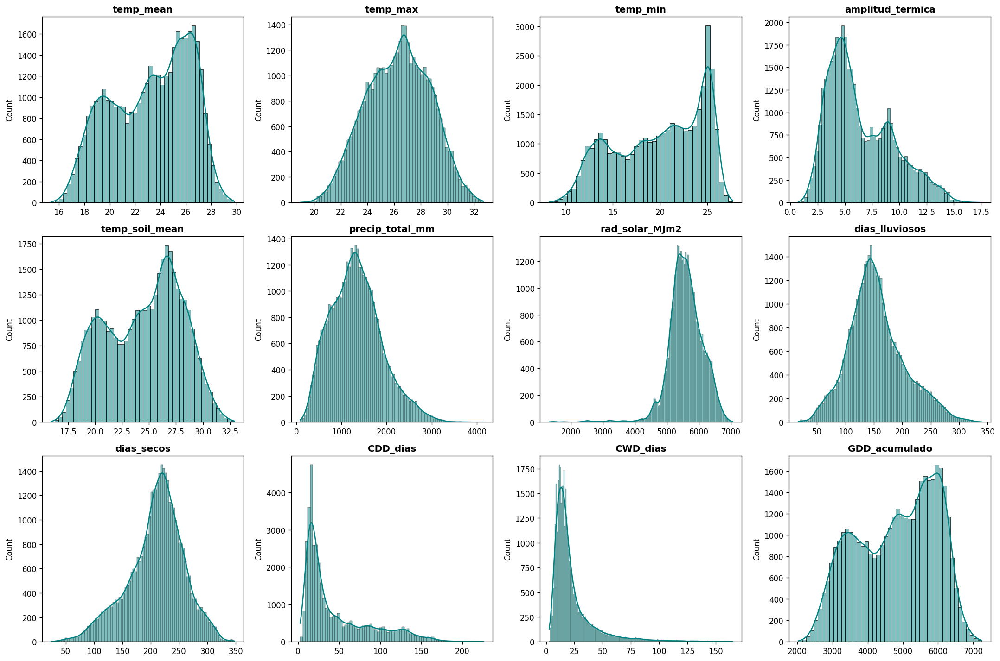

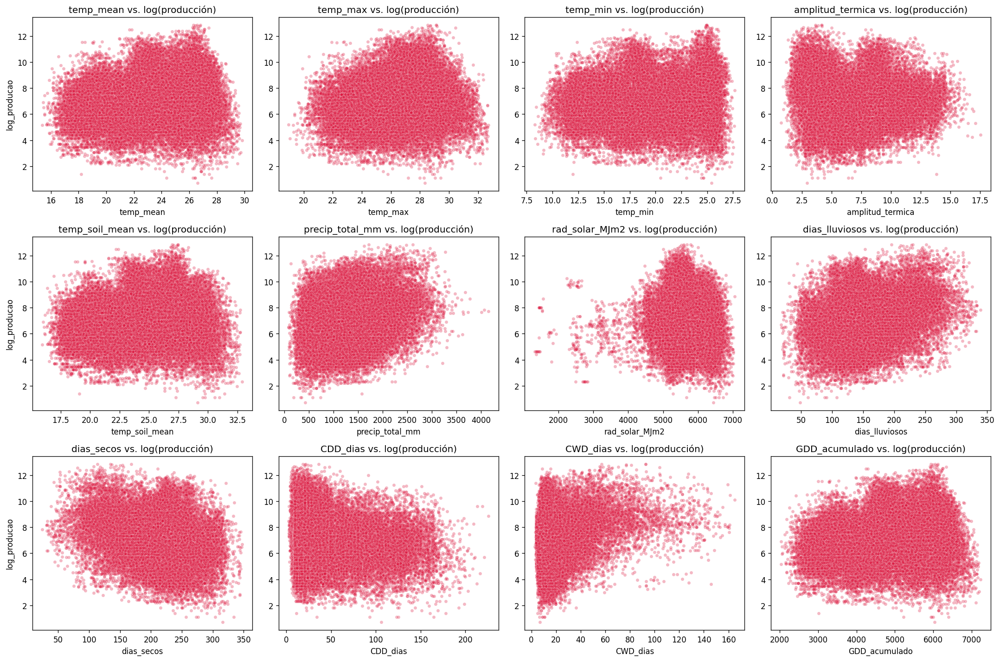

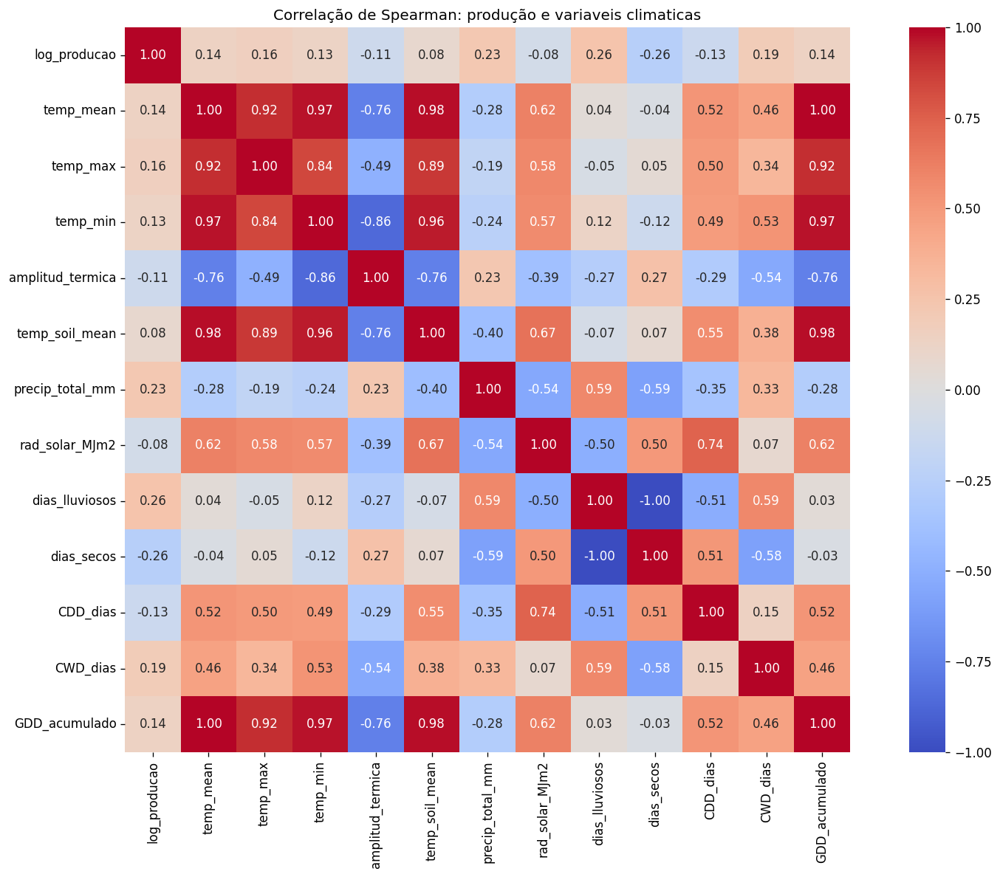

/tmp/ipykernel_1416/247737100.py:78: UserWarning: The design matrix is poorly conditioned (condition number=2.57e+15). VIF calculations may be numerically unstable.
  vif_df = pd.DataFrame({'Variable': features_climaticas,'VIF': [variance_inflation_factor(X_vif_scaled, i)for i in range(X_vif_scaled.shape[1])]})
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_

Diagnóstico VIF de las 12 variables climáticas


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


,Variable,VIF
1,temp_max,1.000800e+15
2,temp_min,1.000800e+15
3,amplitud_termica,1.000800e+15
7,dias_lluviosos,1.892055e+04
8,dias_secos,1.890892e+04
11,GDD_acumulado,1.184035e+04
0,temp_mean,1.163850e+04
4,temp_soil_mean,6.896000e+01
5,precip_total_mm,3.500000e+00
9,CDD_dias,3.030000e+00


In [54]:
#Analises com todas las variables
# 1. DEFINIÇÃO DE VARIAVEIS
features_climaticas = ['temp_mean','temp_max','temp_min','amplitud_termica','temp_soil_mean','precip_total_mm','rad_solar_MJm2','dias_lluviosos','dias_secos','CDD_dias','CWD_dias','GDD_acumulado']
target = 'mandioca_quantidade_produzida'
# Crear la variable transformada
# La producción debe ser no negativa
if (df_acr_train[target] < 0).any():
    raise ValueError("Hay valores negativos en la producción.")
df_acr_train['log_producao'] = np.log1p(df_acr_train[target])
# 2. ANALISES UNIVARIADO DA PRODUÇÃO
fig, axes = plt.subplots(2, 2, figsize=(14, 8), dpi=120)
sns.histplot(df_acr_train[target].dropna(),bins=50, kde=True, ax=axes[0, 0], color='#d95f02')
axes[0, 0].set_title('Distribución original de la producción')
axes[0, 0].set_xlabel('Producción (toneladas)')
sns.histplot(df_acr_train['log_producao'].dropna(),bins=50, kde=True, ax=axes[0, 1], color='#7570b3')
axes[0, 1].set_title('Distribución de log(producción + 1)')
axes[0, 1].set_xlabel('log(producción + 1)')
sns.boxplot(x=df_acr_train[target], ax=axes[1, 0], color='#d95f02')
axes[1, 0].set_title('Boxplot de la producción original')
axes[1, 0].set_xlabel('Producción (toneladas)')
sns.boxplot(x=df_acr_train['log_producao'],ax=axes[1, 1], color='#7570b3')
axes[1, 1].set_title('Boxplot de la producción transformada')
axes[1, 1].set_xlabel('log(producción + 1)')
plt.tight_layout()
plt.show()
# 3. ANALISES UNIVARIADO DAS 12 VARIAVEIS CLIMATICAS
print("Estadísticas descriptivas de las variables climáticas")
display(df_acr_train[features_climaticas].describe().T.round(3))
ncols = 4
nrows = math.ceil(len(features_climaticas) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows), dpi=120)
axes = np.asarray(axes).flatten()
for i, col in enumerate(features_climaticas):
    sns.histplot(
        df_acr_train[col].dropna(),
        kde=True,
        ax=axes[i],
        color='teal'
    )
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xlabel('')

# Ocultar los ejes que sobren
for i in range(len(features_climaticas), len(axes)):
    axes[i].set_visible(False)
plt.tight_layout()
plt.show()
# 4. RELAÇÃO DE CADA VARIAVEL CLIMATICA COM A PRODUÇÃO
ncols = 4
nrows = math.ceil(len(features_climaticas) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows), dpi=120)
axes = np.asarray(axes).flatten()
for i, col in enumerate(features_climaticas):
    sns.scatterplot(data=df_acr_train,x=col,y='log_producao',ax=axes[i],alpha=0.3,color='crimson',s=18)
    axes[i].set_title(f'{col} vs. log(producción)')
    axes[i].set_ylabel('log_producao' if i % ncols == 0 else '')

for i in range(len(features_climaticas), len(axes)):
    axes[i].set_visible(False)
plt.tight_layout()
plt.show()
# 5. CORRELAÇÃO DE SPEARMAN
# Se utiliza solo la producción transformada como respuesta
# para evitar mostrar dos versiones casi redundantes de la misma variable.
cols_corr = ['log_producao'] + features_climaticas
corr_spearman = df_acr_train[cols_corr].corr(method='spearman')
plt.figure(figsize=(14, 10), dpi=120)
sns.heatmap(corr_spearman,annot=True,fmt='.2f',cmap='coolwarm',center=0,vmin=-1,vmax=1,square=True)
plt.title('Correlação de Spearman: produção e variaveis climaticas')
plt.tight_layout()
plt.show()
# 6. DIAGNÓSTICO DE MULTICOLINEARIDADE: VIF
# Usar las mismas observaciones para todas las variables
X_vif = df_acr_train[features_climaticas].dropna()
# Estandarizar para facilitar el procesamiento numérico
scaler_vif = StandardScaler()
X_vif_scaled = scaler_vif.fit_transform(X_vif)
vif_df = pd.DataFrame({'Variable': features_climaticas,'VIF': [variance_inflation_factor(X_vif_scaled, i)for i in range(X_vif_scaled.shape[1])]})
print("Diagnóstico VIF de las 12 variables climáticas")
display(vif_df.sort_values('VIF', ascending=False).round(2))

In [55]:
#Tabela de dados agroclima original
df_acr_train

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,rad_solar_MJm2,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado,mandioca_area_colhida,mandioca_quantidade_produzida,producao_lag1,log_producao
0,1100015,Alta Floresta D'Oeste,RO,2012,25.300989,27.635776,23.956721,3.679055,25.910236,1859.126705,5605.210674,215.418264,149.581736,59.296813,33.496226,5585.223773,546.0,8736.0,6720.0,9.075322
1,1100015,Alta Floresta D'Oeste,RO,2013,24.922070,26.164826,23.934008,2.230818,25.524709,2055.736989,5372.045575,240.076091,123.923909,42.533436,36.212172,5431.407427,546.0,10920.0,8736.0,9.298443
2,1100015,Alta Floresta D'Oeste,RO,2014,25.142517,27.251599,23.878290,3.373309,25.713396,2171.786559,5341.926471,233.970940,130.029060,36.098604,52.534905,5512.897165,566.0,11320.0,10920.0,9.334415
3,1100015,Alta Floresta D'Oeste,RO,2015,25.977802,28.265103,24.256374,4.008729,26.604156,1813.641147,5644.196873,226.318124,137.681876,41.931926,52.948761,5817.049286,566.0,11320.0,11320.0,9.334415
4,1100015,Alta Floresta D'Oeste,RO,2016,25.505128,26.392511,24.139770,2.252742,26.149057,1956.590009,5524.780151,212.235086,152.764914,63.360144,27.007549,5659.754434,566.0,11320.0,11320.0,9.334415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49650,5300108,Brasília,DF,2018,22.191870,24.604679,20.349522,4.255158,23.562559,1184.609098,5969.488376,141.102414,222.897586,92.555350,20.173290,4439.511338,1250.0,20550.0,17400.0,9.930665
49651,5300108,Brasília,DF,2019,23.001519,25.806558,19.907067,5.899491,24.427089,918.055084,6287.463566,123.631858,240.368142,131.712792,22.931134,4729.407990,1250.0,20550.0,20550.0,9.930665
49652,5300108,Brasília,DF,2020,21.986999,24.838238,19.690853,5.147384,23.367886,1285.613541,6046.755987,142.792438,222.207562,118.694932,16.284232,4371.839968,1250.0,20550.0,20550.0,9.930665
49653,5300108,Brasília,DF,2021,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,5982.696234,138.110941,225.889059,118.493564,27.628238,4374.144006,1250.0,20550.0,20550.0,9.930665


### Cluster K Means

In [56]:
%matplotlib inline
features_brutas= ['temp_mean',	'temp_max',	'temp_min',	'temp_soil_mean','precip_total_mm',	'rad_solar_MJm2']
df_perfil_clim = df_acr_train.groupby('CD_MUN')[features_brutas].mean().reset_index()
prod_munic = df_perfil_clim.copy()

In [57]:
scaler = MinMaxScaler()
prod_munic[features_brutas] = scaler.fit_transform(prod_munic[features_brutas])
prod_munic.head()

,CD_MUN,temp_mean,temp_max,temp_min,temp_soil_mean,precip_total_mm,rad_solar_MJm2
0,1100015,0.725251,0.624423,0.831840,0.617552,0.522162,0.784362
1,1100023,0.766401,0.692825,0.883642,0.648958,0.618204,0.738826
2,1100031,0.724602,0.648311,0.817337,0.612332,0.435399,0.794200
3,1100049,0.750498,0.679961,0.865965,0.650884,0.545342,0.767267
4,1100056,0.750935,0.671813,0.838951,0.661743,0.464688,0.801015


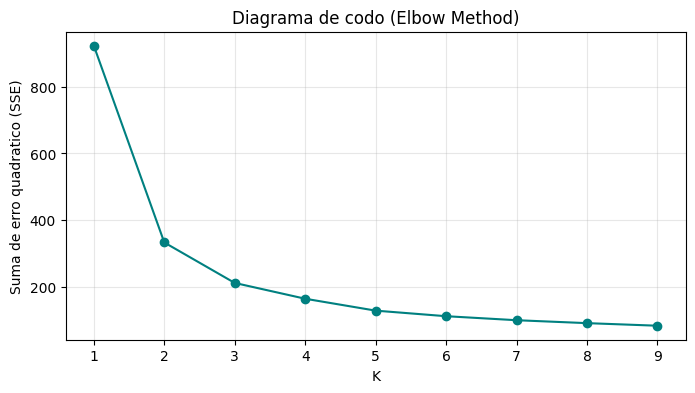

In [58]:
# Diagrama de codo: pra definir numero de clusters
k_rng = range(1, 10)
sse = []
for k in k_rng:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(prod_munic[features_brutas])
    sse.append(km.inertia_)
# Graficar la suma de errores cuadráticos
plt.figure(figsize=(8, 4))
plt.xlabel('K')
plt.ylabel('Suma de erro quadratico (SSE)')
plt.plot(k_rng, sse, marker='o', color='teal')
plt.title('Diagrama de codo (Elbow Method)')
plt.grid(True, alpha=0.3)
plt.show()

In [59]:
# Entrenamiento de conjunto de datos escalado con KMeans (4 clusters)
km = KMeans(n_clusters=4, random_state=42, n_init=10)
y_predicted = km.fit_predict(prod_munic[features_brutas])
# Asignar la columna cluster al DataFrame
prod_munic['cluster'] = y_predicted
prod_munic.head()

,CD_MUN,temp_mean,temp_max,temp_min,temp_soil_mean,precip_total_mm,rad_solar_MJm2,cluster
0,1100015,0.725251,0.624423,0.831840,0.617552,0.522162,0.784362,0
1,1100023,0.766401,0.692825,0.883642,0.648958,0.618204,0.738826,0
2,1100031,0.724602,0.648311,0.817337,0.612332,0.435399,0.794200,0
3,1100049,0.750498,0.679961,0.865965,0.650884,0.545342,0.767267,0
4,1100056,0.750935,0.671813,0.838951,0.661743,0.464688,0.801015,0


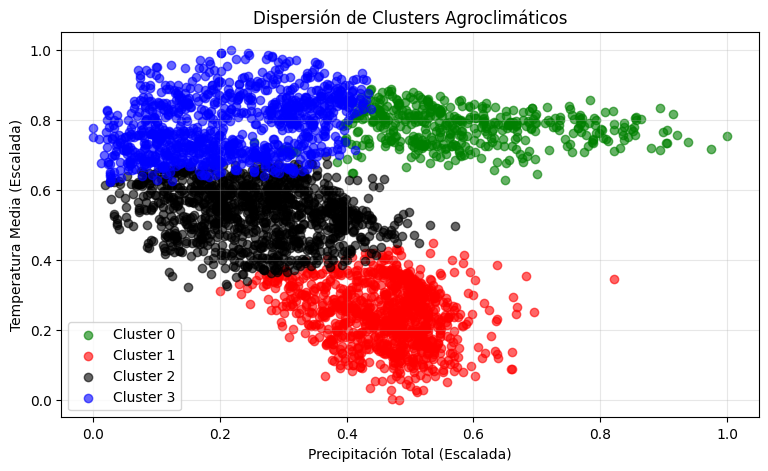

In [60]:
# Grafico de dispersao por clusters
df1 = prod_munic[prod_munic.cluster == 0]
df2 = prod_munic[prod_munic.cluster == 1]
df3 = prod_munic[prod_munic.cluster == 2]
df4 = prod_munic[prod_munic.cluster == 3]
plt.figure(figsize=(9, 5))
plt.scatter(df1['precip_total_mm'], df1['temp_mean'], color='green', label='Cluster 0', alpha=0.6)
plt.scatter(df2['precip_total_mm'], df2['temp_mean'], color='red', label='Cluster 1', alpha=0.6)
plt.scatter(df3['precip_total_mm'], df3['temp_mean'], color='black', label='Cluster 2', alpha=0.6)
plt.scatter(df4['precip_total_mm'], df4['temp_mean'], color='blue', label='Cluster 3', alpha=0.6)
plt.xlabel('Precipitación Total (Escalada)')
plt.ylabel('Temperatura Media (Escalada)')
plt.legend()
plt.title('Dispersión de Clusters Agroclimáticos')
plt.grid(True, alpha=0.3)
plt.show()

In [61]:
# Si existe previa columna, la eliminamos para evitar duplicados
if 'cluster_climatico' in df_acr_train.columns:
    df_acr_train = df_acr_train.drop(columns=['cluster_climatico'])
# Mapeamos la columna 'cluster' que calculaste en prod_munic hacia df_acr_train
df_acr_train = df_acr_train.merge(prod_munic[['CD_MUN', 'cluster']],on='CD_MUN',how='left')
df_acr_train.rename(columns={'cluster': 'cluster_climatico'}, inplace=True)

In [62]:
df_acr_train

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,...,dias_lluviosos,dias_secos,CDD_dias,CWD_dias,GDD_acumulado,mandioca_area_colhida,mandioca_quantidade_produzida,producao_lag1,log_producao,cluster_climatico
0,1100015,Alta Floresta D'Oeste,RO,2012,25.300989,27.635776,23.956721,3.679055,25.910236,1859.126705,...,215.418264,149.581736,59.296813,33.496226,5585.223773,546.0,8736.0,6720.0,9.075322,0
1,1100015,Alta Floresta D'Oeste,RO,2013,24.922070,26.164826,23.934008,2.230818,25.524709,2055.736989,...,240.076091,123.923909,42.533436,36.212172,5431.407427,546.0,10920.0,8736.0,9.298443,0
2,1100015,Alta Floresta D'Oeste,RO,2014,25.142517,27.251599,23.878290,3.373309,25.713396,2171.786559,...,233.970940,130.029060,36.098604,52.534905,5512.897165,566.0,11320.0,10920.0,9.334415,0
3,1100015,Alta Floresta D'Oeste,RO,2015,25.977802,28.265103,24.256374,4.008729,26.604156,1813.641147,...,226.318124,137.681876,41.931926,52.948761,5817.049286,566.0,11320.0,11320.0,9.334415,0
4,1100015,Alta Floresta D'Oeste,RO,2016,25.505128,26.392511,24.139770,2.252742,26.149057,1956.590009,...,212.235086,152.764914,63.360144,27.007549,5659.754434,566.0,11320.0,11320.0,9.334415,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39012,5300108,Brasília,DF,2018,22.191870,24.604679,20.349522,4.255158,23.562559,1184.609098,...,141.102414,222.897586,92.555350,20.173290,4439.511338,1250.0,20550.0,17400.0,9.930665,2
39013,5300108,Brasília,DF,2019,23.001519,25.806558,19.907067,5.899491,24.427089,918.055084,...,123.631858,240.368142,131.712792,22.931134,4729.407990,1250.0,20550.0,20550.0,9.930665,2
39014,5300108,Brasília,DF,2020,21.986999,24.838238,19.690853,5.147384,23.367886,1285.613541,...,142.792438,222.207562,118.694932,16.284232,4371.839968,1250.0,20550.0,20550.0,9.930665,2
39015,5300108,Brasília,DF,2021,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,...,138.110941,225.889059,118.493564,27.628238,4374.144006,1250.0,20550.0,20550.0,9.930665,2


###Silhouette

In [63]:
# Variables climáticas normalizadas y etiquetas de los clusters
X = prod_munic[features_brutas]
labels = prod_munic['cluster']
# 1. Silhouette Score general
silhouette = silhouette_score(X,labels,metric='euclidean')
print(f'Silhouette Score general: {silhouette:.4f}')
# 2. Silhouette Score promedio por cluster
prod_munic['silhouette_individual'] = silhouette_samples(X,labels,metric='euclidean')
silhouette_clusters = (prod_munic.groupby('cluster')['silhouette_individual'].mean().reset_index(name='Silhouette promedio'))
print('\nSilhouette por cluster:')
display(silhouette_clusters)

Silhouette Score general: 0.4199

Silhouette por cluster:


,cluster,Silhouette promedio
0,0,0.463526
1,1,0.544935
2,2,0.401533
3,3,0.288368


In [64]:
# Proporción de municipios con Silhouette por cluster
resumen_silhouette = (prod_munic.groupby('cluster')['silhouette_individual'].agg(promedio='mean',minimo='min',maximo='max',porcentaje_negativo=lambda x: (x < 0).mean() * 100).round(3))
display(resumen_silhouette)

,promedio,minimo,maximo,porcentaje_negativo
cluster,,,,
0,0.464,0.022,0.633,0.000
1,0.545,-0.001,0.705,0.195
2,0.402,0.001,0.643,0.000
3,0.288,-0.117,0.540,4.303


In [65]:
#avalaiação de silhouette para diferentes clusters
resultados_k = []
for k in range(2, 9):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    etiquetas = modelo.fit_predict(prod_munic[features_brutas])
    score = silhouette_score(prod_munic[features_brutas],etiquetas)
    resultados_k.append({'k': k,'Silhouette Score': score,'SSE': modelo.inertia_})
comparacion_k = pd.DataFrame(resultados_k)
display(comparacion_k.round(4))

,k,Silhouette Score,SSE
0,2,0.5219,332.5198
1,3,0.4360,210.9198
2,4,0.4199,163.4688
3,5,0.4013,127.7238
4,6,0.3479,111.0007
5,7,0.3277,98.9470
6,8,0.3114,90.1502


###Estatisticas Descriptivas clima por clusters

In [66]:
# Variables climáticas originales utilizadas en el K-means
features_brutas = ['temp_mean','temp_max','temp_min','temp_soil_mean','precip_total_mm','rad_solar_MJm2']
df_estadisticas_clim = df_perfil_clim.merge(prod_munic[['CD_MUN', 'cluster']],on='CD_MUN',how='left')
# Calcular estadísticas descriptivas por cluster
estadisticas_por_cluster = (df_estadisticas_clim.groupby('cluster')[features_brutas].agg(['count', 'mean', 'std', 'min', 'max']).round(2))
# Mostrar resultados
display(estadisticas_por_cluster)
# Guardar resultados en Excel
estadisticas_por_cluster.to_excel('estadisticas_climaticas_por_cluster.xlsx')

temp_mean                            temp_max                      \
            count   mean   std    min    max    count   mean   std    min   
cluster                                                                     
0             459  26.19  0.65  24.22  27.60      459  28.22  0.83  25.86   
1            1026  19.25  1.12  16.09  21.90     1026  23.88  1.34  19.73   
2            1086  22.99  1.01  20.28  25.12     1086  25.79  1.10  22.36   
3             976  26.26  1.10  24.16  29.06      976  28.57  1.36  25.40   

                ... precip_total_mm                                     \
           max  ...           count     mean     std      min      max   
cluster         ...                                                      
0        30.51  ...             459  2041.94  400.00  1055.12  3297.73   
1        26.95  ...            1026  1671.12  231.25   896.06  2760.26   
2        28.75  ...            1086  1071.94  305.56   351.08  2010.36   
3        32.14  ...             976   942.83  328.72   293.14  1610.82   

        rad_solar_MJm2                                     
                 count     mean     std      min      max  
cluster                                                    
0                  459  5458.09  448.59  1485.74  6186.15  
1                 1026  5205.76  371.32  2447.97  5978.07  
2                 1086  5570.97  410.73  1396.07  6589.34  
3                  976  6082.79  341.05  3672.82  6766.17  

[4 rows x 30 columns]

In [67]:
# media das variaveis climáticas por cluster
medias_climaticas = (df_estadisticas_clim.groupby('cluster')[features_brutas].mean().round(3))
# Mostrar tabla
display(medias_climaticas)
# Exportar tabla
medias_climaticas.to_excel('medias_climaticas_por_cluster.xlsx')

,temp_mean,temp_max,temp_min,temp_soil_mean,precip_total_mm,rad_solar_MJm2
cluster,,,,,,
0,26.194,28.224,24.802,27.089,2041.944,5458.092
1,19.255,23.876,13.913,20.012,1671.125,5205.762
2,22.990,25.791,19.593,24.291,1071.943,5570.974
3,26.264,28.574,24.118,28.256,942.830,6082.793


In [68]:
# quantidade de municipios por cluster
municipios_por_cluster = (df_estadisticas_clim.groupby('cluster')['CD_MUN'].nunique().reset_index(name='Municipios'))
display(municipios_por_cluster)

,cluster,Municipios
0,0,459
1,1,1026
2,2,1086
3,3,976


In [69]:
#PCA SCree Plot

### PCA

In [70]:
# PCA COMPLETO SOBRE AS VARIAVEIS E INDICES
todas_las_variables_climaticas = ['temp_mean','temp_max','temp_min','amplitud_termica','temp_soil_mean','precip_total_mm','rad_solar_MJm2','dias_lluviosos','dias_secos','CDD_dias','CWD_dias','GDD_acumulado']

In [71]:
# Escalado sobre la tabla panel completa (ciudad por año)
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(df_acr_train[todas_las_variables_climaticas].dropna())
# Ajuste de PCA con todas las variables para el Scree Plot
pca_completo = PCA(random_state=42)
pca_completo.fit(X_pca_scaled)
var_exp = pca_completo.explained_variance_ratio_
var_cum = np.cumsum(var_exp)

### Scree Plot

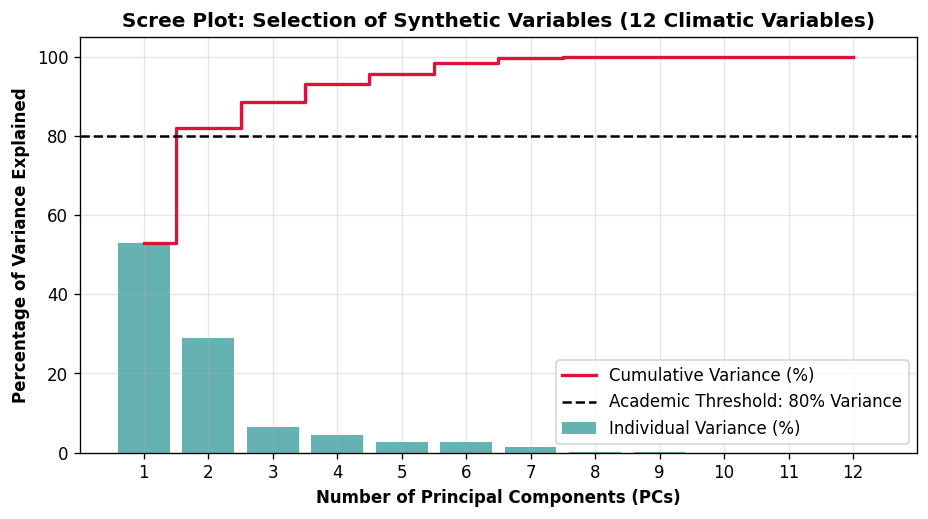

In [72]:
plt.figure(figsize=(9, 4.5), dpi=120)
plt.bar(range(1, len(var_exp) + 1), var_exp * 100, alpha=0.6, align='center', label='Individual Variance (%)', color='teal')
plt.step(range(1, len(var_cum) + 1), var_cum * 100, where='mid', label='Cumulative Variance (%)', color='crimson', linewidth=2)
plt.axhline(y=80, color='black', linestyle='--', label='Academic Threshold: 80% Variance')
plt.ylabel('Percentage of Variance Explained', fontweight='bold')
plt.xlabel('Number of Principal Components (PCs)', fontweight='bold')
plt.title('Scree Plot: Selection of Synthetic Variables (12 Climatic Variables)', fontweight='bold')
plt.xticks(range(1, len(var_exp) + 1))
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

In [73]:
for idx, cum in enumerate(var_cum, 1):
    print(f"Componentes 1 a {idx}: Explicán el {cum*100:.2f}% de la varianza total.")

Componentes 1 a 1: Explicán el 52.90% de la varianza total.
Componentes 1 a 2: Explicán el 81.94% de la varianza total.
Componentes 1 a 3: Explicán el 88.44% de la varianza total.
Componentes 1 a 4: Explicán el 93.00% de la varianza total.
Componentes 1 a 5: Explicán el 95.71% de la varianza total.
Componentes 1 a 6: Explicán el 98.31% de la varianza total.
Componentes 1 a 7: Explicán el 99.76% de la varianza total.
Componentes 1 a 8: Explicán el 99.92% de la varianza total.
Componentes 1 a 9: Explicán el 100.00% de la varianza total.
Componentes 1 a 10: Explicán el 100.00% de la varianza total.
Componentes 1 a 11: Explicán el 100.00% de la varianza total.
Componentes 1 a 12: Explicán el 100.00% de la varianza total.


In [74]:
#TRANSFORMAÇÃO DAS VARIAVEIS EM PC1 Y PC2 PRA O MODELADO
pca_final = PCA(n_components=2, random_state=42)
componentes_matriz = pca_final.fit_transform(X_pca_scaled)
# Guardamos los componentes directamente en df_acr_train para futuros modelos
df_acr_train['PC1_clima'] = componentes_matriz[:, 0]
df_acr_train['PC2_clima'] = componentes_matriz[:, 1]
# Matriz de Cargas (Loadings) para saber qué mide PC1 y PC2
loadings_full = pd.DataFrame(pca_final.components_.T,columns=['PC1_clima', 'PC2_clima'],index=todas_las_variables_climaticas)
print("\n--- MATRIZ DE CARGAS (LOADINGS): DEFINICIÓN BIOLÓGICA DE PC1 Y PC2 ---")
display(loadings_full.round(3))


--- MATRIZ DE CARGAS (LOADINGS): DEFINICIÓN BIOLÓGICA DE PC1 Y PC2 ---


,PC1_clima,PC2_clima
temp_mean,0.389,-0.068
temp_max,0.347,-0.015
temp_min,0.383,-0.111
amplitud_termica,-0.311,0.159
temp_soil_mean,0.391,-0.008
precip_total_mm,-0.141,-0.374
rad_solar_MJm2,0.265,0.268
dias_lluviosos,-0.025,-0.516
dias_secos,0.025,0.516
CDD_dias,0.258,0.244


In [75]:
#Creacion columna log_lag1
df_acr_train['log_producao_lag1'] = np.log1p(df_acr_train['producao_lag1'])

In [76]:
df_acr_train

,CD_MUN,NM_MUN,SIGLA_UF,ano,temp_mean,temp_max,temp_min,amplitud_termica,temp_soil_mean,precip_total_mm,...,CWD_dias,GDD_acumulado,mandioca_area_colhida,mandioca_quantidade_produzida,producao_lag1,log_producao,cluster_climatico,PC1_clima,PC2_clima,log_producao_lag1
0,1100015,Alta Floresta D'Oeste,RO,2012,25.300989,27.635776,23.956721,3.679055,25.910236,1859.126705,...,33.496226,5585.223773,546.0,8736.0,6720.0,9.075322,0,1.493586,-2.084925,8.812992
1,1100015,Alta Floresta D'Oeste,RO,2013,24.922070,26.164826,23.934008,2.230818,25.524709,2055.736989,...,36.212172,5431.407427,546.0,10920.0,8736.0,9.298443,0,1.010543,-3.060060,9.075322
2,1100015,Alta Floresta D'Oeste,RO,2014,25.142517,27.251599,23.878290,3.373309,25.713396,2171.786559,...,52.534905,5512.897165,566.0,11320.0,10920.0,9.334415,0,1.175906,-3.349660,9.298443
3,1100015,Alta Floresta D'Oeste,RO,2015,25.977802,28.265103,24.256374,4.008729,26.604156,1813.641147,...,52.948761,5817.049286,566.0,11320.0,11320.0,9.334415,0,1.885837,-2.796298,9.334415
4,1100015,Alta Floresta D'Oeste,RO,2016,25.505128,26.392511,24.139770,2.252742,26.149057,1956.590009,...,27.007549,5659.754434,566.0,11320.0,11320.0,9.334415,0,1.466861,-2.049088,9.334415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39012,5300108,Brasília,DF,2018,22.191870,24.604679,20.349522,4.255158,23.562559,1184.609098,...,20.173290,4439.511338,1250.0,20550.0,17400.0,9.930665,2,0.159775,0.831909,9.764283
39013,5300108,Brasília,DF,2019,23.001519,25.806558,19.907067,5.899491,24.427089,918.055084,...,22.931134,4729.407990,1250.0,20550.0,20550.0,9.930665,2,0.935360,1.761633,9.930665
39014,5300108,Brasília,DF,2020,21.986999,24.838238,19.690853,5.147384,23.367886,1285.613541,...,16.284232,4371.839968,1250.0,20550.0,20550.0,9.930665,2,0.119454,1.084279,9.930665
39015,5300108,Brasília,DF,2021,22.011990,25.875673,19.303110,6.572563,23.441715,1262.157315,...,27.628238,4374.144006,1250.0,20550.0,20550.0,9.930665,2,0.170577,1.001088,9.930665


In [77]:
df_acr_train.columns

Index(['CD_MUN', 'NM_MUN', 'SIGLA_UF', 'ano', 'temp_mean', 'temp_max',
       'temp_min', 'amplitud_termica', 'temp_soil_mean', 'precip_total_mm',
       'rad_solar_MJm2', 'dias_lluviosos', 'dias_secos', 'CDD_dias',
       'CWD_dias', 'GDD_acumulado', 'mandioca_area_colhida',
       'mandioca_quantidade_produzida', 'producao_lag1', 'log_producao',
       'cluster_climatico', 'PC1_clima', 'PC2_clima', 'log_producao_lag1'],
      dtype='object')

In [78]:
df_treino = df_acr_train[['CD_MUN','NM_MUN','SIGLA_UF','ano','producao_lag1','log_producao_lag1','PC1_clima','PC2_clima','cluster_climatico','log_producao','mandioca_quantidade_produzida']].copy()

In [79]:
df_treino

,CD_MUN,NM_MUN,SIGLA_UF,ano,producao_lag1,log_producao_lag1,PC1_clima,PC2_clima,cluster_climatico,log_producao,mandioca_quantidade_produzida
0,1100015,Alta Floresta D'Oeste,RO,2012,6720.0,8.812992,1.493586,-2.084925,0,9.075322,8736.0
1,1100015,Alta Floresta D'Oeste,RO,2013,8736.0,9.075322,1.010543,-3.060060,0,9.298443,10920.0
2,1100015,Alta Floresta D'Oeste,RO,2014,10920.0,9.298443,1.175906,-3.349660,0,9.334415,11320.0
3,1100015,Alta Floresta D'Oeste,RO,2015,11320.0,9.334415,1.885837,-2.796298,0,9.334415,11320.0
4,1100015,Alta Floresta D'Oeste,RO,2016,11320.0,9.334415,1.466861,-2.049088,0,9.334415,11320.0
...,...,...,...,...,...,...,...,...,...,...,...
39012,5300108,Brasília,DF,2018,17400.0,9.764283,0.159775,0.831909,2,9.930665,20550.0
39013,5300108,Brasília,DF,2019,20550.0,9.930665,0.935360,1.761633,2,9.930665,20550.0
39014,5300108,Brasília,DF,2020,20550.0,9.930665,0.119454,1.084279,2,9.930665,20550.0
39015,5300108,Brasília,DF,2021,20550.0,9.930665,0.170577,1.001088,2,9.930665,20550.0


In [80]:
df_treino_2012_2022 = df_treino[['NM_MUN','ano','log_producao_lag1','PC1_clima','PC2_clima','cluster_climatico','log_producao']].copy()

In [81]:
df_treino_2012_2022

,NM_MUN,ano,log_producao_lag1,PC1_clima,PC2_clima,cluster_climatico,log_producao
0,Alta Floresta D'Oeste,2012,8.812992,1.493586,-2.084925,0,9.075322
1,Alta Floresta D'Oeste,2013,9.075322,1.010543,-3.060060,0,9.298443
2,Alta Floresta D'Oeste,2014,9.298443,1.175906,-3.349660,0,9.334415
3,Alta Floresta D'Oeste,2015,9.334415,1.885837,-2.796298,0,9.334415
4,Alta Floresta D'Oeste,2016,9.334415,1.466861,-2.049088,0,9.334415
...,...,...,...,...,...,...,...
39012,Brasília,2018,9.764283,0.159775,0.831909,2,9.930665
39013,Brasília,2019,9.930665,0.935360,1.761633,2,9.930665
39014,Brasília,2020,9.930665,0.119454,1.084279,2,9.930665
39015,Brasília,2021,9.930665,0.170577,1.001088,2,9.930665


# Extração do conhecimento (Função pra x e Y)

In [82]:
# Crear una copia independiente de la base original
df_modelagem = df_acr_train.copy()
# Ordenar por código municipal y año
df_modelagem = df_modelagem.sort_values(by=['CD_MUN', 'ano']).reset_index(drop=True)

### Validação cruzada

In [83]:
folds_temporais = [
    {'anos_treino': (2012, 2018), 'ano_validacao': 2019},
    {'anos_treino': (2012, 2019), 'ano_validacao': 2020},
    {'anos_treino': (2012, 2020), 'ano_validacao': 2021},
    {'anos_treino': (2012, 2021), 'ano_validacao': 2022}]

In [84]:
def preparar_fold_pca(df, fold):
    inicio, fin = fold['anos_treino']
    ano_val = fold['ano_validacao']
    # Separar entrenamiento y validación
    datos_treino = df[df['ano'].between(inicio, fin)].copy()
    datos_validacao = df[df['ano'] == ano_val].copy()
    # Variables climáticas
    X_treino = datos_treino[todas_las_variables_climaticas]
    X_validacao = datos_validacao[todas_las_variables_climaticas]
    # Estandarizar
    scaler = StandardScaler()
    X_treino_scaled = scaler.fit_transform(X_treino)
    X_validacao_scaled = scaler.transform(X_validacao)
    # Aplicar PCA
    pca = PCA(n_components=2)
    componentes_treino = pca.fit_transform(X_treino_scaled)
    componentes_validacao = pca.transform(X_validacao_scaled)
    # Incorporar componentes
    datos_treino['PC1_clima'] = componentes_treino[:, 0]
    datos_treino['PC2_clima'] = componentes_treino[:, 1]
    datos_validacao['PC1_clima'] = componentes_validacao[:, 0]
    datos_validacao['PC2_clima'] = componentes_validacao[:, 1]
    return datos_treino, datos_validacao

In [85]:
resultados_folds = {}
for i, fold in enumerate(folds_temporais, start=1):
    treino, validacao = preparar_fold_pca(df_modelagem, fold)
    resultados_folds[i] = {'treino': treino,'validacao': validacao}

###Definição de Cénarios e Modelos

In [86]:
escenarios = {
    'Global_sin_lag': {
        'tipo': 'global',
        'predictores': ['PC1_clima', 'PC2_clima'],
        'algoritmos': ['Decision Tree', 'Random Forest', 'XGBoost']
    },
    'Global_con_lag': {
        'tipo': 'global',
        'predictores': ['PC1_clima', 'PC2_clima', 'log_producao_lag1'],
        'algoritmos': ['Decision Tree', 'Random Forest', 'XGBoost']
    },
    'Cluster_sin_lag': {
        'tipo': 'cluster',
        'predictores': ['PC1_clima', 'PC2_clima'],
        'algoritmos': ['Decision Tree', 'Random Forest', 'XGBoost']
    },
    'Cluster_con_lag': {
        'tipo': 'cluster',
        'predictores': ['PC1_clima', 'PC2_clima', 'log_producao_lag1'],
        'algoritmos': ['Decision Tree', 'Random Forest', 'XGBoost']
    },
    'Global_solo_lag1': {
        'tipo': 'global',
        'predictores': ['log_producao_lag1'],
        'algoritmos': ['Decision Tree', 'Random Forest', 'XGBoost']
    },
    'Cluster_solo_lag1': {
        'tipo': 'cluster',
        'predictores': ['log_producao_lag1'],
        'algoritmos': ['Decision Tree', 'Random Forest', 'XGBoost']
    },
    # Baseline entrenable: lineal regressor global con lag1 só
    'Baseline_lag1': {
        'tipo': 'global',
        'predictores': ['log_producao_lag1'],
        'algoritmos': ['Linear Regression']
    },
    'Baseline_lag1_PCA': {
    'tipo': 'global',
    'predictores': ['PC1_clima', 'PC2_clima', 'log_producao_lag1'],
    'algoritmos': ['Linear Regression']
}
}

### Configuração de Hiperparametros pra cada algoritmo com ParameterGrid()

In [87]:

parametros_modelos = {

    'Decision Tree': {
        'max_depth': [3, 5, 8],
        'min_samples_leaf': [5, 10, 20],
        'min_samples_split': [10, 20, 40]
    },

    'Random Forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [5, 8, 12],
        'min_samples_leaf': [2, 5, 10]
    },

    'XGBoost': {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.03, 0.1, 0.2]
    }
}

# Baseline entrenable: regresión lineal
parametros_modelos['Linear Regression'] = {
    'fit_intercept': [True, False]
}


###Treinamento, Validação, Geração de Previssões e Avaliação dos Modelos com Outliers em cada Fold.

In [88]:
def entrenar_evaluar(
    datos_treino,
    datos_validacao,
    escenario,
    algoritmo,
    hiperparametros
):

    predictores = escenarios[escenario]['predictores']
    tipo = escenarios[escenario]['tipo']

    # Seleccionar los grupos de entrenamiento
    if tipo == 'global':
        grupos = [None]
    else:
        grupos = sorted(datos_treino['cluster_climatico'].unique())

    resultados = []
    predicciones = []
    tiempos = []

    for cluster in grupos:

        if cluster is None:
            treino = datos_treino
            validacao = datos_validacao
        else:
            treino = datos_treino[
                datos_treino['cluster_climatico'] == cluster
            ]
            validacao = datos_validacao[
                datos_validacao['cluster_climatico'] == cluster
            ]

        X_treino = treino[predictores]
        y_treino = treino['log_producao']

        X_validacao = validacao[predictores]
        y_validacao = validacao['log_producao']

        # Crear el modelo
        if algoritmo == 'Decision Tree':
            modelo = DecisionTreeRegressor(
                **hiperparametros,
                random_state=42
            )

        elif algoritmo == 'Random Forest':
            modelo = RandomForestRegressor(
                **hiperparametros,
                random_state=42,
                n_jobs=-1
            )

        elif algoritmo == 'XGBoost':
            modelo = XGBRegressor(
                **hiperparametros,
                random_state=42,
                n_jobs=-1,
                objective='reg:squarederror'
            )

        elif algoritmo == 'Linear Regression':
            modelo = LinearRegression(**hiperparametros)

        else:
            raise ValueError(f'Algoritmo no reconocido: {algoritmo}')

        # Medir tiempo de entrenamiento
        inicio_treino = time.perf_counter()
        modelo.fit(X_treino, y_treino)
        tempo_treinamento = time.perf_counter() - inicio_treino

        # Medir tiempo de predicción
        inicio_predicao = time.perf_counter()
        y_pred = modelo.predict(X_validacao)
        tempo_predicao = time.perf_counter() - inicio_predicao

        # Métricas
        resultados.append({
            'escenario': escenario,
            'algoritmo': algoritmo,
            'cluster': cluster,
            'RMSE': np.sqrt(mean_squared_error(y_validacao, y_pred)),
            'MAE': mean_absolute_error(y_validacao, y_pred),
            'R2': r2_score(y_validacao, y_pred),
            'hiperparametros': hiperparametros
        })

        # Guardar predicciones
        predicciones.append(pd.DataFrame({
            'CD_MUN': validacao['CD_MUN'].values,
            'ano': validacao['ano'].values,
            'cluster_climatico': validacao['cluster_climatico'].values,
            'observado': y_validacao.values,
            'predicho': y_pred
        }))

        # Guardar tiempos
        tiempos.append({
            'escenario': escenario,
            'algoritmo': algoritmo,
            'cluster': cluster,
            'n_registros_treino': len(treino),
            'n_registros_validacao': len(validacao),
            'tempo_treinamento_s': tempo_treinamento,
            'tempo_predicao_s': tempo_predicao,
            'hiperparametros': hiperparametros
        })

    return (
        pd.DataFrame(resultados),
        pd.concat(predicciones, ignore_index=True),
        pd.DataFrame(tiempos)
    )

In [89]:
resultados_experimentos = []
tiempos_experimentos = []

for numero_fold, datos_fold in resultados_folds.items():

    datos_treino = datos_fold['treino']
    datos_validacao = datos_fold['validacao']

    for escenario in escenarios:

        for algoritmo in escenarios[escenario]['algoritmos']:

            parametros = parametros_modelos[algoritmo]

            combinaciones = list(ParameterGrid(parametros))

            for hiperparametros in combinaciones:

                metricas, _, tiempos = entrenar_evaluar(
                    datos_treino,
                    datos_validacao,
                    escenario,
                    algoritmo,
                    hiperparametros
                )

                metricas['fold'] = numero_fold
                tiempos['fold'] = numero_fold

                resultados_experimentos.append(metricas)
                tiempos_experimentos.append(tiempos)

    print(f'Fold {numero_fold} finalizado.')

# Unificar resultados
resultados_experimentos = pd.concat(
    resultados_experimentos,
    ignore_index=True
)

# Unificar tiempos
df_tiempos_experimentos = pd.concat(
    tiempos_experimentos,
    ignore_index=True
)

print('Todos los experimentos finalizaron.')

Fold 1 finalizado.
Fold 2 finalizado.
Fold 3 finalizado.
Fold 4 finalizado.
Todos los experimentos finalizaron.


###Resultados

In [90]:
resumen_tiempos_folds = (df_tiempos_experimentos.groupby(['escenario', 'algoritmo']).agg(
        numero_ajustes=('tempo_treinamento_s', 'count'),
        treinamento_total_s=('tempo_treinamento_s', 'sum'),
        predicao_total_s=('tempo_predicao_s', 'sum'),
        treinamento_medio_s=('tempo_treinamento_s', 'mean'),
        predicao_media_s=('tempo_predicao_s', 'mean')
    )
    .reset_index()
)
resumen_tiempos_folds.round(4)

,escenario,algoritmo,numero_ajustes,treinamento_total_s,predicao_total_s,treinamento_medio_s,predicao_media_s
0,Baseline_lag1,Linear Regression,8,0.0469,0.0099,0.0059,0.0012
1,Baseline_lag1_PCA,Linear Regression,8,0.0322,0.0099,0.0040,0.0012
2,Cluster_con_lag,Decision Tree,432,11.7942,0.7992,0.0273,0.0019
3,Cluster_con_lag,Random Forest,432,1560.2866,31.2062,3.6118,0.0722
4,Cluster_con_lag,XGBoost,432,131.4013,3.0379,0.3042,0.0070
5,Cluster_sin_lag,Decision Tree,432,8.7242,0.6555,0.0202,0.0015
6,Cluster_sin_lag,Random Forest,432,1361.0402,30.8541,3.1506,0.0714
7,Cluster_sin_lag,XGBoost,432,97.6365,3.0508,0.2260,0.0071
8,Cluster_solo_lag1,Decision Tree,432,2.7376,0.5247,0.0063,0.0012
9,Cluster_solo_lag1,Random Forest,432,470.3012,31.6628,1.0887,0.0733


In [91]:
print(resultados_experimentos.shape)
print(resultados_experimentos['escenario'].value_counts())

(4876, 8)
escenario
Cluster_con_lag      1296
Cluster_sin_lag      1296
Cluster_solo_lag1    1296
Global_con_lag        324
Global_sin_lag        324
Global_solo_lag1      324
Baseline_lag1           8
Baseline_lag1_PCA       8
Name: count, dtype: int64


In [92]:
resultados_experimentos

,escenario,algoritmo,cluster,RMSE,MAE,R2,hiperparametros,fold
0,Global_sin_lag,Decision Tree,None,1.647941,1.298669,0.108653,"{'max_depth': 3, 'min_samples_leaf': 5, 'min_s...",1
1,Global_sin_lag,Decision Tree,None,1.647941,1.298669,0.108653,"{'max_depth': 3, 'min_samples_leaf': 5, 'min_s...",1
2,Global_sin_lag,Decision Tree,None,1.647941,1.298669,0.108653,"{'max_depth': 3, 'min_samples_leaf': 5, 'min_s...",1
3,Global_sin_lag,Decision Tree,None,1.647941,1.298669,0.108653,"{'max_depth': 3, 'min_samples_leaf': 10, 'min_...",1
4,Global_sin_lag,Decision Tree,None,1.647941,1.298669,0.108653,"{'max_depth': 3, 'min_samples_leaf': 10, 'min_...",1
...,...,...,...,...,...,...,...,...
4871,Cluster_solo_lag1,XGBoost,3,0.434326,0.304407,0.919126,"{'learning_rate': 0.2, 'max_depth': 7, 'n_esti...",4
4872,Baseline_lag1,Linear Regression,None,0.407644,0.254304,0.943970,{'fit_intercept': True},4
4873,Baseline_lag1,Linear Regression,None,0.402596,0.244946,0.945349,{'fit_intercept': False},4
4874,Baseline_lag1_PCA,Linear Regression,None,0.408060,0.256794,0.943856,{'fit_intercept': True},4


###Comparação do Desempenho Médio e Seleção das Melhores Combinações de Hiperparâmetros por Validação Cruzada

In [93]:
# Crear una clave de texto para las combinaciones de hiperparámetros
resultados_experimentos['hiperparametros_id'] = (resultados_experimentos['hiperparametros'].apply(lambda x: str(sorted(x.items()))))
# Agrupar y calcular el rendimiento medio de cada combinación
mejor_modelo = (
    resultados_experimentos
    .groupby(
        [
            'escenario',
            'algoritmo',
            'cluster',
            'hiperparametros_id'
        ],
        dropna=False
    )
    .agg(
        RMSE_medio=('RMSE', 'mean'),
        MAE_medio=('MAE', 'mean'),
        R2_medio=('R2', 'mean'),
        folds=('fold', 'nunique')
    )
    .reset_index()
    .sort_values('RMSE_medio')
)

# Mostrar el mejor candidato solo con cluster
mejor_modelo

,escenario,algoritmo,cluster,hiperparametros_id,RMSE_medio,MAE_medio,R2_medio,folds
801,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 2), ('...",0.391546,0.240542,0.924084,4
800,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 2), ('...",0.391633,0.240525,0.924046,4
799,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 2), ('...",0.391636,0.240502,0.924044,4
804,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",0.391838,0.240647,0.923983,4
802,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",0.391854,0.240536,0.923978,4
...,...,...,...,...,...,...,...,...
622,Cluster_sin_lag,XGBoost,2.0,"[('learning_rate', 0.2), ('max_depth', 7), ('n...",2.026322,1.618806,-0.140626,4
621,Cluster_sin_lag,XGBoost,2.0,"[('learning_rate', 0.2), ('max_depth', 5), ('n...",2.040905,1.629972,-0.157041,4
615,Cluster_sin_lag,XGBoost,2.0,"[('learning_rate', 0.1), ('max_depth', 7), ('n...",2.051074,1.639117,-0.168642,4
623,Cluster_sin_lag,XGBoost,2.0,"[('learning_rate', 0.2), ('max_depth', 7), ('n...",2.086072,1.670188,-0.208670,4


###Seleção das Melhores Configurações de Hiperparâmetros por Cenário, Algoritmo e Cluster (Com Outliers)

In [94]:
mejores_por_grupo = (mejor_modelo.sort_values('RMSE_medio').groupby(['escenario', 'algoritmo', 'cluster'], dropna=False).head(1).sort_values('RMSE_medio'))
mejores_por_grupo.round(4)

,escenario,algoritmo,cluster,hiperparametros_id,RMSE_medio,MAE_medio,R2_medio,folds
801,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 2), ('...",0.3915,0.2405,0.9241,4
897,Cluster_solo_lag1,XGBoost,1.0,"[('learning_rate', 0.03), ('max_depth', 3), ('...",0.3926,0.2418,0.9238,4
156,Cluster_con_lag,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",0.3950,0.2472,0.9228,4
694,Cluster_solo_lag1,Decision Tree,1.0,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",0.3955,0.2454,0.9226,4
248,Cluster_con_lag,XGBoost,1.0,"[('learning_rate', 0.03), ('max_depth', 3), ('...",0.3985,0.2539,0.9218,4
48,Cluster_con_lag,Decision Tree,1.0,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",0.4005,0.2508,0.9207,4
1,Baseline_lag1,Linear Regression,NaN,"[('fit_intercept', True)]",0.4548,0.2791,0.9298,4
1194,Global_solo_lag1,XGBoost,NaN,"[('learning_rate', 0.03), ('max_depth', 3), ('...",0.4595,0.2939,0.9284,4
1175,Global_solo_lag1,Random Forest,NaN,"[('max_depth', 5), ('min_samples_leaf', 10), (...",0.4596,0.2939,0.9284,4
1016,Global_con_lag,Random Forest,NaN,"[('max_depth', 5), ('min_samples_leaf', 2), ('...",0.4613,0.2941,0.9278,4


### Melhores modelos e combinações

In [95]:
#melhor modelo RF por cluster solo lag1
mejores_cluster_solo_lag1_RF = (mejor_modelo[(mejor_modelo['escenario'] == 'Cluster_solo_lag1') & (mejor_modelo['algoritmo'] == 'Random Forest')].sort_values('RMSE_medio').groupby('cluster', dropna=False).head(1).sort_values('RMSE_medio', ascending=True).reset_index(drop=True))
display(mejores_cluster_solo_lag1_RF[['escenario','algoritmo','cluster','RMSE_medio','MAE_medio','R2_medio','hiperparametros_id','folds']].round(4))

,escenario,algoritmo,cluster,RMSE_medio,MAE_medio,R2_medio,hiperparametros_id,folds
0,Cluster_solo_lag1,Random Forest,1.0,0.3915,0.2405,0.9241,"[('max_depth', 5), ('min_samples_leaf', 2), ('...",4
1,Cluster_solo_lag1,Random Forest,0.0,0.4829,0.2725,0.9067,"[('max_depth', 5), ('min_samples_leaf', 10), (...",4
2,Cluster_solo_lag1,Random Forest,3.0,0.4896,0.3350,0.8944,"[('max_depth', 5), ('min_samples_leaf', 10), (...",4
3,Cluster_solo_lag1,Random Forest,2.0,0.4905,0.3251,0.9328,"[('max_depth', 5), ('min_samples_leaf', 10), (...",4


In [96]:
# Mejor modelo RF de cada clúster en el escenario Cluster_con_lag
mejores_cluster_con_lag_RF = (
    mejor_modelo[
        (mejor_modelo['escenario'] == 'Cluster_con_lag') &
        (mejor_modelo['algoritmo'] == 'Random Forest')
    ]
    .sort_values('RMSE_medio').groupby('cluster', dropna=False).head(1).sort_values('RMSE_medio').reset_index(drop=True)
)
display(mejores_cluster_con_lag_RF[['escenario', 'algoritmo', 'cluster', 'RMSE_medio','MAE_medio', 'R2_medio', 'hiperparametros_id', 'folds']].round(4))

,escenario,algoritmo,cluster,RMSE_medio,MAE_medio,R2_medio,hiperparametros_id,folds
0,Cluster_con_lag,Random Forest,1.0,0.3950,0.2472,0.9228,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",4
1,Cluster_con_lag,Random Forest,0.0,0.4833,0.2765,0.9070,"[('max_depth', 5), ('min_samples_leaf', 10), (...",4
2,Cluster_con_lag,Random Forest,3.0,0.4930,0.3300,0.8926,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",4
3,Cluster_con_lag,Random Forest,2.0,0.4937,0.3272,0.9318,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",4


In [97]:
# Mejor resultado del escenario Baseline solo lag1
mejor_baseline_lag1 = (mejor_modelo[mejor_modelo['escenario'] == 'Baseline_lag1'].sort_values('RMSE_medio').head(1).reset_index(drop=True))
# Mostrar tabla resumida
display(mejor_baseline_lag1[['escenario','algoritmo','RMSE_medio','MAE_medio','R2_medio','hiperparametros_id','folds']].round(4))

,escenario,algoritmo,RMSE_medio,MAE_medio,R2_medio,hiperparametros_id,folds
0,Baseline_lag1,Linear Regression,0.4548,0.2791,0.9298,"[('fit_intercept', True)]",4


In [98]:
# Mejor resultado del escenario Baseline con PCA + lag1
mejor_baseline_lag1_PCA = (mejor_modelo[mejor_modelo['escenario'] == 'Baseline_lag1_PCA'].sort_values('RMSE_medio').head(1).reset_index(drop=True))
# Mostrar tabla resumida
display(mejor_baseline_lag1_PCA[['escenario','algoritmo','RMSE_medio','MAE_medio','R2_medio','hiperparametros_id','folds']].round(4))

,escenario,algoritmo,RMSE_medio,MAE_medio,R2_medio,hiperparametros_id,folds
0,Baseline_lag1_PCA,Linear Regression,0.4616,0.2891,0.9276,"[('fit_intercept', True)]",4


In [99]:
# Mejor resultado del escenario XGBooST Global_solo_lag1
mejor_global_solo_lag1 = (mejor_modelo[mejor_modelo['escenario'] == 'Global_solo_lag1'].sort_values('RMSE_medio').head(1).reset_index(drop=True))
display(mejor_global_solo_lag1[['escenario','algoritmo','RMSE_medio','MAE_medio','R2_medio','hiperparametros_id','folds']].round(4))

,escenario,algoritmo,RMSE_medio,MAE_medio,R2_medio,hiperparametros_id,folds
0,Global_solo_lag1,XGBoost,0.4595,0.2939,0.9284,"[('learning_rate', 0.03), ('max_depth', 3), ('...",4


In [100]:
# Mejor resultado del escenario RF Global_con_lag
mejor_global_con_lag = (mejor_modelo[mejor_modelo['escenario'] == 'Global_con_lag'].sort_values('RMSE_medio').head(1).reset_index(drop=True))
display(mejor_global_con_lag[['escenario','algoritmo','RMSE_medio','MAE_medio','R2_medio','hiperparametros_id','folds']].round(4))

,escenario,algoritmo,RMSE_medio,MAE_medio,R2_medio,hiperparametros_id,folds
0,Global_con_lag,Random Forest,0.4613,0.2941,0.9278,"[('max_depth', 5), ('min_samples_leaf', 2), ('...",4


In [101]:
# Mejor modelo de cada clúster en el escenario Cluster_sin_lag
mejores_cluster_sin_lag = (mejor_modelo[mejor_modelo['escenario'] == 'Cluster_sin_lag'].sort_values('RMSE_medio').groupby('cluster', dropna=False).head(1).sort_values('RMSE_medio').reset_index(drop=True))
display(    mejores_cluster_sin_lag[['escenario','algoritmo','cluster','RMSE_medio','MAE_medio','R2_medio','hiperparametros_id','folds']].round(4))

,escenario,algoritmo,cluster,RMSE_medio,MAE_medio,R2_medio,hiperparametros_id,folds
0,Cluster_sin_lag,XGBoost,1.0,1.4561,1.1563,-0.0301,"[('learning_rate', 0.03), ('max_depth', 3), ('...",4
1,Cluster_sin_lag,XGBoost,3.0,1.4674,1.1492,0.0738,"[('learning_rate', 0.03), ('max_depth', 3), ('...",4
2,Cluster_sin_lag,XGBoost,0.0,1.4960,1.1631,0.1526,"[('learning_rate', 0.03), ('max_depth', 3), ('...",4
3,Cluster_sin_lag,XGBoost,2.0,1.9276,1.5509,-0.0323,"[('learning_rate', 0.03), ('max_depth', 3), ('...",4


In [102]:
# Mejor resultado del escenario Global_sin_lag
mejor_global_sin_lag = (mejor_modelo[mejor_modelo['escenario'] == 'Global_sin_lag'].sort_values('RMSE_medio').head(1).reset_index(drop=True))
display(mejor_global_sin_lag[['escenario','algoritmo','RMSE_medio','MAE_medio','R2_medio','hiperparametros_id','folds']].round(4))

,escenario,algoritmo,RMSE_medio,MAE_medio,R2_medio,hiperparametros_id,folds
0,Global_sin_lag,XGBoost,1.6314,1.2849,0.1112,"[('learning_rate', 0.03), ('max_depth', 3), ('...",4


###Treinamento, Validação, Geração de Previssões e Avaliação dos Modelos Sem Outliers em cada Fold.

In [103]:
#Eliminação de outliers mediante IQR de Treino.
def eliminar_outliers_iqr(datos, variable='log_producao'):
    Q1 = datos[variable].quantile(0.25)
    Q3 = datos[variable].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    datos_filtrados = datos[
        (datos[variable] >= limite_inferior) &
        (datos[variable] <= limite_superior)
    ].copy()
    return datos_filtrados

In [104]:
def entrenar_evaluar(
    datos_treino,
    datos_validacao,
    escenario,
    algoritmo,
    hiperparametros,
    remover_outliers=False
):
    predictores = escenarios[escenario]['predictores']
    tipo = escenarios[escenario]['tipo']

    if tipo == 'global':
        grupos = [None]
    else:
        grupos = sorted(datos_treino['cluster_climatico'].unique())

    resultados = []
    predicciones = []

    for cluster in grupos:

        if cluster is None:
            treino = datos_treino.copy()
            validacao = datos_validacao.copy()
        else:
            treino = datos_treino[
                datos_treino['cluster_climatico'] == cluster
            ].copy()

            validacao = datos_validacao[
                datos_validacao['cluster_climatico'] == cluster
            ].copy()

        # Eliminar outliers únicamente del entrenamiento
        if remover_outliers:
            treino = eliminar_outliers_iqr(treino)

        X_treino = treino[predictores]
        y_treino = treino['log_producao']

        X_validacao = validacao[predictores]
        y_validacao = validacao['log_producao']

        if algoritmo == 'Decision Tree':
            modelo = DecisionTreeRegressor(
                **hiperparametros,
                random_state=42
            )

        elif algoritmo == 'Random Forest':
            modelo = RandomForestRegressor(
                **hiperparametros,
                random_state=42,
                n_jobs=-1
            )

        elif algoritmo == 'XGBoost':
            modelo = XGBRegressor(
                **hiperparametros,
                random_state=42,
                n_jobs=-1,
                objective='reg:squarederror'
            )
        elif algoritmo == 'Linear Regression':
            modelo = LinearRegression(**hiperparametros

            )

        modelo.fit(X_treino, y_treino)

        y_pred = modelo.predict(X_validacao)

        resultados.append({
            'escenario': escenario,
            'algoritmo': algoritmo,
            'cluster': cluster,
            'RMSE': np.sqrt(
                mean_squared_error(y_validacao, y_pred)
            ),
            'MAE': mean_absolute_error(y_validacao, y_pred),
            'R2': r2_score(y_validacao, y_pred),
            'hiperparametros': hiperparametros
        })

        predicciones.append(pd.DataFrame({
            'CD_MUN': validacao['CD_MUN'].values,
            'ano': validacao['ano'].values,
            'cluster_climatico': validacao['cluster_climatico'].values,
            'observado': y_validacao.values,
            'predicho': y_pred
        }))

    return (
        pd.DataFrame(resultados),
        pd.concat(predicciones, ignore_index=True)
    )

In [105]:
resultados_experimentos_sin_outliers = []

for numero_fold, datos_fold in resultados_folds.items():

    datos_treino = datos_fold['treino']
    datos_validacao = datos_fold['validacao']

    for escenario in escenarios:

        for algoritmo in escenarios[escenario]['algoritmos']:

            parametros = parametros_modelos[algoritmo]
            combinaciones = list(ParameterGrid(parametros))

            for hiperparametros in combinaciones:

                metricas, _ = entrenar_evaluar(
                    datos_treino,
                    datos_validacao,
                    escenario,
                    algoritmo,
                    hiperparametros,
                    remover_outliers=True
                )

                metricas['fold'] = numero_fold

                resultados_experimentos_sin_outliers.append(metricas)

    print(f'Fold {numero_fold} finalizado.')

# Unificar los resultados
resultados_experimentos_sin_outliers = pd.concat(
    resultados_experimentos_sin_outliers,
    ignore_index=True
)

print('Todos los experimentos sin outliers finalizaron.')


Fold 1 finalizado.
Fold 2 finalizado.
Fold 3 finalizado.
Fold 4 finalizado.
Todos los experimentos sin outliers finalizaron.


In [106]:
resultados_experimentos_sin_outliers

,escenario,algoritmo,cluster,RMSE,MAE,R2,hiperparametros,fold
0,Global_sin_lag,Decision Tree,None,1.646896,1.298836,0.109782,"{'max_depth': 3, 'min_samples_leaf': 5, 'min_s...",1
1,Global_sin_lag,Decision Tree,None,1.646896,1.298836,0.109782,"{'max_depth': 3, 'min_samples_leaf': 5, 'min_s...",1
2,Global_sin_lag,Decision Tree,None,1.646896,1.298836,0.109782,"{'max_depth': 3, 'min_samples_leaf': 5, 'min_s...",1
3,Global_sin_lag,Decision Tree,None,1.646896,1.298836,0.109782,"{'max_depth': 3, 'min_samples_leaf': 10, 'min_...",1
4,Global_sin_lag,Decision Tree,None,1.646896,1.298836,0.109782,"{'max_depth': 3, 'min_samples_leaf': 10, 'min_...",1
...,...,...,...,...,...,...,...,...
4871,Cluster_solo_lag1,XGBoost,3,0.440427,0.305847,0.916838,"{'learning_rate': 0.2, 'max_depth': 7, 'n_esti...",4
4872,Baseline_lag1,Linear Regression,None,0.409633,0.257695,0.943422,{'fit_intercept': True},4
4873,Baseline_lag1,Linear Regression,None,0.402591,0.244915,0.945351,{'fit_intercept': False},4
4874,Baseline_lag1_PCA,Linear Regression,None,0.409445,0.259148,0.943474,{'fit_intercept': True},4


Comparação do Desempenho Médio e Seleção das Melhores Combinações de Hiperparâmetros por Validação Cruzada

In [107]:
# Crear una clave para identificar las combinaciones de hiperparámetros
resultados_experimentos_sin_outliers['hiperparametros_id'] = (
    resultados_experimentos_sin_outliers['hiperparametros']
    .apply(lambda x: str(sorted(x.items())))
)

# Agrupar y calcular el rendimiento medio de cada combinación
mejor_modelo_sin_outliers = (
    resultados_experimentos_sin_outliers
    .groupby(
        [
            'escenario',
            'algoritmo',
            'cluster',
            'hiperparametros_id'
        ],
        dropna=False
    )
    .agg(
        RMSE_medio=('RMSE', 'mean'),
        MAE_medio=('MAE', 'mean'),
        R2_medio=('R2', 'mean'),
        folds=('fold', 'nunique')
    )
    .reset_index()
    .sort_values('RMSE_medio')
)

# Mostrar los candidatos ordenados por RMSE
mejor_modelo_sin_outliers

,escenario,algoritmo,cluster,hiperparametros_id,RMSE_medio,MAE_medio,R2_medio,folds
798,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 10), (...",0.396746,0.244015,0.922182,4
797,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 10), (...",0.396833,0.244014,0.922149,4
796,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 10), (...",0.396938,0.244071,0.922106,4
804,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",0.397045,0.244217,0.922067,4
803,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",0.397130,0.244209,0.922034,4
...,...,...,...,...,...,...,...,...
622,Cluster_sin_lag,XGBoost,2.0,"[('learning_rate', 0.2), ('max_depth', 7), ('n...",2.019850,1.612690,-0.133392,4
621,Cluster_sin_lag,XGBoost,2.0,"[('learning_rate', 0.2), ('max_depth', 5), ('n...",2.039332,1.629948,-0.155348,4
615,Cluster_sin_lag,XGBoost,2.0,"[('learning_rate', 0.1), ('max_depth', 7), ('n...",2.040823,1.631982,-0.157087,4
623,Cluster_sin_lag,XGBoost,2.0,"[('learning_rate', 0.2), ('max_depth', 7), ('n...",2.078831,1.660357,-0.200548,4


###Melhores  modelos e configurações sem  outliers

In [108]:
#RESULTADOS MEJORES MODELOS Y CONFIGURACIONES SIN OUTLIERS
mejores_por_grupo_sin_outliers = (
    mejor_modelo_sin_outliers
    .sort_values('RMSE_medio')
    .groupby(
        ['escenario', 'algoritmo', 'cluster'],
        dropna=False
    )
    .head(1)
    .sort_values('RMSE_medio')
)

mejores_por_grupo_sin_outliers.round(4)

,escenario,algoritmo,cluster,hiperparametros_id,RMSE_medio,MAE_medio,R2_medio,folds
798,Cluster_solo_lag1,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 10), (...",0.3967,0.2440,0.9222,4
897,Cluster_solo_lag1,XGBoost,1.0,"[('learning_rate', 0.03), ('max_depth', 3), ('...",0.3972,0.2446,0.9220,4
688,Cluster_solo_lag1,Decision Tree,1.0,"[('max_depth', 5), ('min_samples_leaf', 10), (...",0.3998,0.2486,0.9211,4
150,Cluster_con_lag,Random Forest,1.0,"[('max_depth', 5), ('min_samples_leaf', 10), (...",0.4013,0.2497,0.9205,4
248,Cluster_con_lag,XGBoost,1.0,"[('learning_rate', 0.03), ('max_depth', 3), ('...",0.4052,0.2570,0.9191,4
46,Cluster_con_lag,Decision Tree,1.0,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",0.4064,0.2541,0.9186,4
1,Baseline_lag1,Linear Regression,NaN,"[('fit_intercept', True)]",0.4560,0.2823,0.9295,4
3,Baseline_lag1_PCA,Linear Regression,NaN,"[('fit_intercept', True)]",0.4619,0.2906,0.9275,4
1194,Global_solo_lag1,XGBoost,NaN,"[('learning_rate', 0.03), ('max_depth', 3), ('...",0.4631,0.2969,0.9273,4
1174,Global_solo_lag1,Random Forest,NaN,"[('max_depth', 5), ('min_samples_leaf', 10), (...",0.4641,0.2975,0.9270,4


###Comparativa dos melhores modelos com e sem outliers

In [109]:
# Compara os melhores modelos de cada grupo organizado pelo menor RMSE
comparacion_outliers = mejores_por_grupo[['escenario','algoritmo','cluster','RMSE_medio','MAE_medio','R2_medio']].copy()
comparacion_sin_outliers = mejores_por_grupo_sin_outliers[['escenario','algoritmo','cluster','RMSE_medio','MAE_medio','R2_medio']].copy()
# Renombrar métricas
comparacion_outliers = comparacion_outliers.rename(columns={'RMSE_medio': 'RMSE_con_outliers','MAE_medio': 'MAE_con_outliers','R2_medio': 'R2_con_outliers'})
comparacion_sin_outliers = comparacion_sin_outliers.rename(columns={'RMSE_medio': 'RMSE_sin_outliers','MAE_medio': 'MAE_sin_outliers','R2_medio': 'R2_sin_outliers'})
# Unir las dos tablas
comparacion_final = comparacion_outliers.merge(comparacion_sin_outliers,on=['escenario', 'algoritmo', 'cluster'],how='inner')
# Calcular diferencias de RMSE
comparacion_final['diferencia_RMSE'] = (comparacion_final['RMSE_sin_outliers'] - comparacion_final['RMSE_con_outliers'])
comparacion_final = comparacion_final.sort_values('RMSE_con_outliers')
display(comparacion_final.round(4))

,escenario,algoritmo,cluster,RMSE_con_outliers,MAE_con_outliers,R2_con_outliers,RMSE_sin_outliers,MAE_sin_outliers,R2_sin_outliers,diferencia_RMSE
0,Cluster_solo_lag1,Random Forest,1.0,0.3915,0.2405,0.9241,0.3967,0.2440,0.9222,0.0052
1,Cluster_solo_lag1,XGBoost,1.0,0.3926,0.2418,0.9238,0.3972,0.2446,0.9220,0.0046
2,Cluster_con_lag,Random Forest,1.0,0.3950,0.2472,0.9228,0.4013,0.2497,0.9205,0.0063
3,Cluster_solo_lag1,Decision Tree,1.0,0.3955,0.2454,0.9226,0.3998,0.2486,0.9211,0.0042
4,Cluster_con_lag,XGBoost,1.0,0.3985,0.2539,0.9218,0.4052,0.2570,0.9191,0.0068
5,Cluster_con_lag,Decision Tree,1.0,0.4005,0.2508,0.9207,0.4064,0.2541,0.9186,0.0059
6,Baseline_lag1,Linear Regression,NaN,0.4548,0.2791,0.9298,0.4560,0.2823,0.9295,0.0012
7,Global_solo_lag1,XGBoost,NaN,0.4595,0.2939,0.9284,0.4631,0.2969,0.9273,0.0035
8,Global_solo_lag1,Random Forest,NaN,0.4596,0.2939,0.9284,0.4641,0.2975,0.9270,0.0045
9,Global_con_lag,Random Forest,NaN,0.4613,0.2941,0.9278,0.4659,0.2972,0.9264,0.0046


In [110]:
#COMPARATIVA DAS METRICAS COM E SEM OUTLIERS
# Seleccionar las columnas necesarias
columnas = ['escenario','algoritmo','cluster','fold','hiperparametros_id','RMSE','MAE','R2']
con_outliers = resultados_experimentos[columnas].copy()
sin_outliers = resultados_experimentos_sin_outliers[columnas].copy()
# Renombrar las métricas
con_outliers = con_outliers.rename(columns={'RMSE': 'RMSE_con_outliers','MAE': 'MAE_con_outliers','R2': 'R2_con_outliers'})
sin_outliers = sin_outliers.rename(columns={'RMSE': 'RMSE_sin_outliers','MAE': 'MAE_sin_outliers','R2': 'R2_sin_outliers'})
# Emparejar exactamente las mismas configuraciones
comparacion_hiperparametros = con_outliers.merge(sin_outliers,on=['escenario','algoritmo','cluster','fold','hiperparametros_id'],how='inner',validate='one_to_one')
# Calcular diferencias
comparacion_hiperparametros['diferencia_RMSE'] = (comparacion_hiperparametros['RMSE_sin_outliers'] - comparacion_hiperparametros['RMSE_con_outliers'])
comparacion_hiperparametros['diferencia_MAE'] = (comparacion_hiperparametros['MAE_sin_outliers'] - comparacion_hiperparametros['MAE_con_outliers'])
comparacion_hiperparametros['diferencia_R2'] = (comparacion_hiperparametros['R2_sin_outliers'] - comparacion_hiperparametros['R2_con_outliers'])
print("Modelos emparejados:", len(comparacion_hiperparametros))
print("Modelos originales:", len(con_outliers))
print("Modelos sin outliers:", len(sin_outliers))
display(comparacion_hiperparametros.head(10).round(4))

Modelos emparejados: 4876
Modelos originales: 4876
Modelos sin outliers: 4876


,escenario,algoritmo,cluster,fold,hiperparametros_id,RMSE_con_outliers,MAE_con_outliers,R2_con_outliers,RMSE_sin_outliers,MAE_sin_outliers,R2_sin_outliers,diferencia_RMSE,diferencia_MAE,diferencia_R2
0,Global_sin_lag,Decision Tree,None,1,"[('max_depth', 3), ('min_samples_leaf', 5), ('...",1.6479,1.2987,0.1087,1.6469,1.2988,0.1098,-0.0010,0.0002,0.0011
1,Global_sin_lag,Decision Tree,None,1,"[('max_depth', 3), ('min_samples_leaf', 5), ('...",1.6479,1.2987,0.1087,1.6469,1.2988,0.1098,-0.0010,0.0002,0.0011
2,Global_sin_lag,Decision Tree,None,1,"[('max_depth', 3), ('min_samples_leaf', 5), ('...",1.6479,1.2987,0.1087,1.6469,1.2988,0.1098,-0.0010,0.0002,0.0011
3,Global_sin_lag,Decision Tree,None,1,"[('max_depth', 3), ('min_samples_leaf', 10), (...",1.6479,1.2987,0.1087,1.6469,1.2988,0.1098,-0.0010,0.0002,0.0011
4,Global_sin_lag,Decision Tree,None,1,"[('max_depth', 3), ('min_samples_leaf', 10), (...",1.6479,1.2987,0.1087,1.6469,1.2988,0.1098,-0.0010,0.0002,0.0011
5,Global_sin_lag,Decision Tree,None,1,"[('max_depth', 3), ('min_samples_leaf', 10), (...",1.6479,1.2987,0.1087,1.6469,1.2988,0.1098,-0.0010,0.0002,0.0011
6,Global_sin_lag,Decision Tree,None,1,"[('max_depth', 3), ('min_samples_leaf', 20), (...",1.6479,1.2987,0.1087,1.6469,1.2988,0.1098,-0.0010,0.0002,0.0011
7,Global_sin_lag,Decision Tree,None,1,"[('max_depth', 3), ('min_samples_leaf', 20), (...",1.6479,1.2987,0.1087,1.6469,1.2988,0.1098,-0.0010,0.0002,0.0011
8,Global_sin_lag,Decision Tree,None,1,"[('max_depth', 3), ('min_samples_leaf', 20), (...",1.6479,1.2987,0.1087,1.6469,1.2988,0.1098,-0.0010,0.0002,0.0011
9,Global_sin_lag,Decision Tree,None,1,"[('max_depth', 5), ('min_samples_leaf', 5), ('...",1.6403,1.2865,0.1169,1.6367,1.2840,0.1208,-0.0036,-0.0025,0.0039


In [111]:
#DIFERENCIAS NAS METRICAS COM E SEM OUTLIERS COM PORCENTAJES
resumen_efecto_outliers = (
    comparacion_hiperparametros
    .groupby(['escenario', 'algoritmo', 'cluster'],dropna=False).agg(
        RMSE_con=('RMSE_con_outliers', 'mean'),
        RMSE_sin=('RMSE_sin_outliers', 'mean'),
        diferencia_RMSE=('diferencia_RMSE', 'mean'),
        diferencia_MAE=('diferencia_MAE', 'mean'),
        diferencia_R2=('diferencia_R2', 'mean'),
        configuraciones=('diferencia_RMSE', 'count'),
        porcentaje_mejora_RMSE=(
            'diferencia_RMSE',
            lambda x: (x < 0).mean() * 100
        ),
        porcentaje_empeora_RMSE=(
            'diferencia_RMSE',
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
    .sort_values('diferencia_RMSE')
)
display(resumen_efecto_outliers.round(4))

,escenario,algoritmo,cluster,RMSE_con,RMSE_sin,diferencia_RMSE,diferencia_MAE,diferencia_R2,configuraciones,porcentaje_mejora_RMSE,porcentaje_empeora_RMSE
13,Cluster_con_lag,XGBoost,3.0,0.5401,0.5361,-0.0039,-0.0024,0.0020,108,58.3333,41.6667
43,Global_sin_lag,XGBoost,NaN,1.6582,1.6543,-0.0039,-0.0035,0.0044,108,87.9630,12.0370
24,Cluster_sin_lag,XGBoost,2.0,1.9831,1.9796,-0.0035,-0.0031,0.0038,108,70.3704,29.6296
17,Cluster_sin_lag,Decision Tree,3.0,1.4972,1.4941,-0.0031,-0.0021,0.0040,108,60.1852,39.8148
23,Cluster_sin_lag,XGBoost,1.0,1.5204,1.5185,-0.0019,-0.0025,0.0034,108,52.7778,47.2222
41,Global_sin_lag,Decision Tree,NaN,1.6565,1.6551,-0.0014,-0.0016,0.0014,108,86.1111,13.8889
42,Global_sin_lag,Random Forest,NaN,1.6497,1.6486,-0.0011,-0.0010,0.0013,108,74.0741,25.9259
21,Cluster_sin_lag,Random Forest,3.0,1.4803,1.4792,-0.0011,-0.0008,0.0014,108,72.2222,27.7778
16,Cluster_sin_lag,Decision Tree,2.0,1.9568,1.9557,-0.0011,-0.0009,0.0012,108,82.4074,17.5926
12,Cluster_con_lag,XGBoost,2.0,0.5321,0.5315,-0.0006,-0.0001,0.0001,108,54.6296,45.3704


In [112]:
#RMSE que meLHORO sEM outliers
# Clasificar el efecto de eliminar valores atípicos
tolerancia = 1e-10
mejoras = (comparacion_hiperparametros['diferencia_RMSE'] < -tolerancia).sum()
empeoramientos = (comparacion_hiperparametros['diferencia_RMSE'] > tolerancia).sum()
sin_cambios = len(comparacion_hiperparametros) - mejoras - empeoramientos
total = len(comparacion_hiperparametros)
# Resumen general
resumen_global = pd.DataFrame({
    'Resultado': [
        'Mejora del RMSE',
        'Empeoramiento del RMSE',
        'Sin cambios relevantes'
    ],
    'Cantidad': [
        mejoras,
        empeoramientos,
        sin_cambios
    ],
    'Porcentaje': [
        mejoras / total * 100,
        empeoramientos / total * 100,
        sin_cambios / total * 100
    ]
})

print("DIFERENCIA PROMEDIO DE RMSE:",round(comparacion_hiperparametros['diferencia_RMSE'].mean(), 6))
print("DIFERENCIA MEDIANA DE RMSE:",round(comparacion_hiperparametros['diferencia_RMSE'].median(), 6))
display(resumen_global.round(2))

DIFERENCIA PROMEDIO DE RMSE: 0.004941
DIFERENCIA MEDIANA DE RMSE: 0.002278


,Resultado,Cantidad,Porcentaje
0,Mejora del RMSE,1500,30.76
1,Empeoramiento del RMSE,3376,69.24
2,Sin cambios relevantes,0,0.00


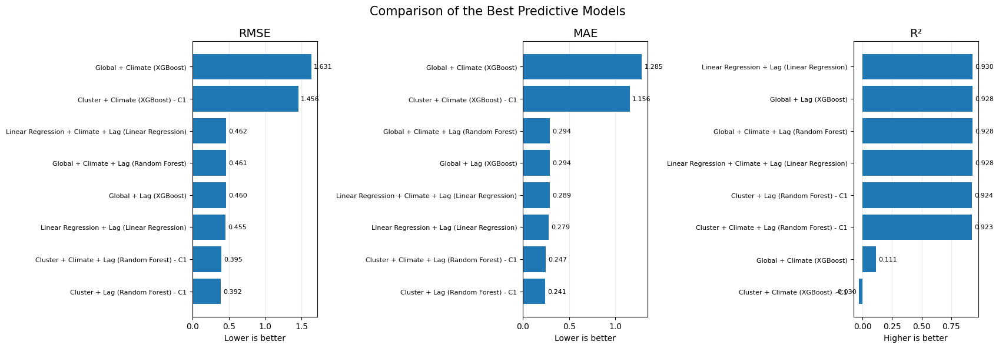

In [113]:
#Comparação de erro de modelos
# 1. Copiar la tabla de comparación
df_grafica = comparacion_final.copy()
# 2. Seleccionar el mejor resultado de cada escenario
# según el menor RMSE con outliers
df_grafica = (df_grafica.sort_values('RMSE_con_outliers').groupby('escenario', as_index=False).first())
# 3. Crear nombres más claros para la figura
nombres = {'Global_con_lag': 'Global + Climate + Lag','Global_sin_lag': 'Global + Climate','Cluster_con_lag': 'Cluster + Climate + Lag','Cluster_sin_lag': 'Cluster + Climate','Global_solo_lag1': 'Global + Lag','Cluster_solo_lag1': 'Cluster + Lag','Baseline_lag1': 'Linear Regression + Lag','Baseline_lag1_PCA': 'Linear Regression + Climate + Lag'}
df_grafica['modelo'] = (df_grafica['escenario'].map(nombres).fillna(df_grafica['escenario'])  + ' ('+ df_grafica['algoritmo'].astype(str)+ ')')
# Identificar el cluster cuando corresponda
df_grafica['modelo'] = df_grafica.apply(
    lambda fila: (
        fila['modelo'] + f' - C{int(fila["cluster"])}'
        if pd.notna(fila['cluster'])
        else fila['modelo']
    ),
    axis=1
)
# 4. Ordenar los resultados por RMSE
df_grafica = df_grafica.sort_values('RMSE_con_outliers',ascending=True)
# 5. Crear los tres paneles
fig, axes = plt.subplots(1, 3,figsize=(17, 6))
metricas = [('RMSE_con_outliers', 'RMSE', 'Lower is better'),('MAE_con_outliers', 'MAE', 'Lower is better'),('R2_con_outliers', 'R²', 'Higher is better')]
for ax, (col, titulo, subtitulo) in zip(axes, metricas):
    dados = df_grafica.sort_values(col, ascending=True)
    barras = ax.barh(
        dados['modelo'],
        dados[col]
    )
    ax.set_title(titulo, fontsize=14)
    ax.set_xlabel(subtitulo, fontsize=10)
    ax.grid(axis='x', alpha=0.25)
    ax.set_axisbelow(True)
    ax.bar_label(
        barras,
        fmt='%.3f',
        padding=3,
        fontsize=8
    )
    ax.tick_params(axis='y', labelsize=8)
fig.suptitle(
    'Comparison of the Best Predictive Models',
    fontsize=15
)
plt.tight_layout()
plt.show()

In [114]:
#COMPARACIONES DE CADA CLUSTER Y GENERAL
# Resultados del modelo ganador: Random Forest + Cluster + Lag 1
modelo_ganador_clusters = comparacion_final[(comparacion_final['escenario'] == 'Cluster_solo_lag1') &  (comparacion_final['algoritmo'] == 'Random Forest')].copy()
# Ordenar por cluster
modelo_ganador_clusters = modelo_ganador_clusters.sort_values('cluster')
# Seleccionar las métricas de interés
columnas = ['cluster','RMSE_con_outliers','MAE_con_outliers','R2_con_outliers']
tabla_clusters_ganador = modelo_ganador_clusters[columnas].copy()
tabla_clusters_ganador = tabla_clusters_ganador.rename(columns={'cluster': 'Cluster','RMSE_con_outliers': 'RMSE','MAE_con_outliers': 'MAE','R2_con_outliers': 'R2'})
display(tabla_clusters_ganador.round(4))

,Cluster,RMSE,MAE,R2
15,0.0,0.4829,0.2725,0.9067
0,1.0,0.3915,0.2405,0.9241
20,2.0,0.4905,0.3251,0.9328
19,3.0,0.4896,0.3350,0.8944


In [115]:
# Resumen descriptivo de los cuatro clusters
resumen_clusters = tabla_clusters_ganador[['RMSE', 'MAE', 'R2']].agg(['mean', 'median', 'std', 'min', 'max'])
display(resumen_clusters.round(4))

,RMSE,MAE,R2
mean,0.4636,0.2933,0.9145
median,0.4862,0.2988,0.9154
std,0.0482,0.0446,0.0172
min,0.3915,0.2405,0.8944
max,0.4905,0.3350,0.9328


In [116]:
# Comparación general de modelos basados en clusters
resultados_cluster = comparacion_final[comparacion_final['escenario'].isin(['Cluster_solo_lag1','Cluster_con_lag'])].copy()
resumen_modelos_cluster = (
    resultados_cluster
    .groupby(['escenario', 'algoritmo'])
    .agg(
        RMSE_medio=('RMSE_con_outliers', 'mean'),
        RMSE_std=('RMSE_con_outliers', 'std'),
        MAE_medio=('MAE_con_outliers', 'mean'),
        R2_medio=('R2_con_outliers', 'mean'),
        numero_clusters=('cluster', 'nunique')
    )
    .reset_index()
    .sort_values('RMSE_medio')
)

display(resumen_modelos_cluster.round(4))


,escenario,algoritmo,RMSE_medio,RMSE_std,MAE_medio,R2_medio,numero_clusters
4,Cluster_solo_lag1,Random Forest,0.4636,0.0482,0.2933,0.9145,4
5,Cluster_solo_lag1,XGBoost,0.4646,0.0482,0.2948,0.9142,4
1,Cluster_con_lag,Random Forest,0.4662,0.0477,0.2952,0.9136,4
3,Cluster_solo_lag1,Decision Tree,0.4689,0.0490,0.2996,0.9127,4
2,Cluster_con_lag,XGBoost,0.4698,0.0480,0.2988,0.9123,4
0,Cluster_con_lag,Decision Tree,0.4788,0.0525,0.3099,0.9089,4


In [117]:
# Cantidad de municipios por cluster
# Se utiliza la clasificación climática ya incorporada en df_modelagem.

municipios_por_cluster = (
    df_modelagem[['CD_MUN', 'cluster_climatico']]
    .drop_duplicates()
    .groupby('cluster_climatico')
    .agg(
        numero_municipios=('CD_MUN', 'nunique')
    )
    .reset_index()
    .rename(columns={'cluster_climatico': 'cluster'})
)

display(municipios_por_cluster)


,cluster,numero_municipios
0,0,459
1,1,1026
2,2,1086
3,3,976


In [118]:
# 1. Crear copias de las tablas
tabla_ponderada = tabla_clusters_ganador.copy()
municipios_por_cluster_limpio = municipios_por_cluster.copy()
# 2. Estandarizar el nombre de la columna cluster
tabla_ponderada = tabla_ponderada.rename(columns={'Cluster': 'cluster'})
municipios_por_cluster_limpio = municipios_por_cluster_limpio.rename(columns={'Cluster': 'cluster'})
# 3. Asegurar que ambas columnas tengan el mismo tipo
tabla_ponderada['cluster'] = tabla_ponderada['cluster'].astype(int)
municipios_por_cluster_limpio['cluster'] = (municipios_por_cluster_limpio['cluster'].astype(int))
# 4. Unir las métricas con la cantidad de municipios
tabla_ponderada = tabla_ponderada.merge(municipios_por_cluster_limpio,on='cluster',how='left',validate='one_to_one')
# 5. Verificar que no falten cantidades de municipios
print("Tabla con métricas y número de municipios:")
display(tabla_ponderada)

# 6. Calcular promedios ponderados
metricas = ['RMSE', 'MAE', 'R2']
resumen_ponderado = {}
for metrica in metricas:
    resumen_ponderado[metrica] = (
        tabla_ponderada[metrica] *
        tabla_ponderada['numero_municipios']
    ).sum() / tabla_ponderada['numero_municipios'].sum()

print("Promedios ponderados por número de municipios:")
display(pd.DataFrame(resumen_ponderado,index=['Promedio ponderado']).round(4))

Tabla con métricas y número de municipios:


,cluster,RMSE,MAE,R2,numero_municipios
0,0,0.482897,0.272507,0.906692,459
1,1,0.391546,0.240542,0.924084,1026
2,2,0.490481,0.325107,0.932762,1086
3,3,0.489598,0.334991,0.894374,976


Promedios ponderados por número de municipios:


,RMSE,MAE,R2
Promedio ponderado,0.4606,0.2966,0.9163


In [119]:
# Selecionar os melhores modelos globais
resultados_globais = mejores_por_grupo[mejores_por_grupo['cluster'].isna()].copy()
# Mostrar as métricas dos cenários globais
display(resultados_globais[['escenario','algoritmo','RMSE_medio','MAE_medio','R2_medio']].sort_values('RMSE_medio'))

,escenario,algoritmo,RMSE_medio,MAE_medio,R2_medio
1,Baseline_lag1,Linear Regression,0.454802,0.279069,0.929820
1194,Global_solo_lag1,XGBoost,0.459541,0.293870,0.928384
1175,Global_solo_lag1,Random Forest,0.459559,0.293937,0.928374
1016,Global_con_lag,Random Forest,0.461273,0.294147,0.927795
3,Baseline_lag1_PCA,Linear Regression,0.461616,0.289112,0.927598
1150,Global_solo_lag1,Decision Tree,0.464578,0.299127,0.926868
1039,Global_con_lag,XGBoost,0.464712,0.297110,0.926622
990,Global_con_lag,Decision Tree,0.470476,0.304530,0.924978
1111,Global_sin_lag,XGBoost,1.631409,1.284860,0.111224
1094,Global_sin_lag,Random Forest,1.639086,1.290703,0.102536


###Preparação dos modelos para sua avaliação final com o conjunto de test

In [120]:
#mejores Random Forest por cluster com outliers
# Seleccionar Random Forest del escenario Cluster_con_lag
mejores_rf_clusters = (mejores_por_grupo[(mejores_por_grupo['escenario'] == 'Cluster_con_lag') & (mejores_por_grupo['algoritmo'] == 'Random Forest')].sort_values('cluster').reset_index(drop=True))
mejores_rf_clusters[['cluster','RMSE_medio','MAE_medio','R2_medio','hiperparametros_id']]

,cluster,RMSE_medio,MAE_medio,R2_medio,hiperparametros_id
0,0.0,0.483265,0.276481,0.906992,"[('max_depth', 5), ('min_samples_leaf', 10), (..."
1,1.0,0.394994,0.247176,0.922813,"[('max_depth', 5), ('min_samples_leaf', 5), ('..."
2,2.0,0.493707,0.327222,0.931842,"[('max_depth', 5), ('min_samples_leaf', 5), ('..."
3,3.0,0.493012,0.330005,0.892605,"[('max_depth', 5), ('min_samples_leaf', 5), ('..."


In [121]:
#Ajuste de PCA com os dados de entrenamento

# Seleccionar variables climáticas
X_train_clima = df_modelagem[todas_las_variables_climaticas]
# Ajustar y transformar con StandardScaler
scaler_final = StandardScaler()
X_train_scaled = scaler_final.fit_transform(X_train_clima)
# Ajustar PCA con dos componentes
pca_final = PCA(n_components=2)
componentes_train = pca_final.fit_transform(X_train_scaled)
# Crear copia de los datos de entrenamiento
df_train_final = df_modelagem.copy()
df_train_final['PC1_clima'] = componentes_train[:, 0]
df_train_final['PC2_clima'] = componentes_train[:, 1]
# Mostrar varianza explicada
print('Varianza explicada por PC1 y PC2:',pca_final.explained_variance_ratio_.sum())

Varianza explicada por PC1 y PC2: 0.8194283058423409


In [122]:
# Crear copia de los datos de prueba
df_test_final = df_acr_test.copy()
# Transformar variables climáticas
X_test_clima = df_test_final[todas_las_variables_climaticas]
X_test_scaled = scaler_final.transform(X_test_clima)
componentes_test = pca_final.transform(X_test_scaled)
# Incorporar componentes principales
df_test_final['PC1_clima'] = componentes_test[:, 0]
df_test_final['PC2_clima'] = componentes_test[:, 1]

In [123]:
#incorporação cluster
clusters_por_municipio = (df_modelagem[['CD_MUN', 'cluster_climatico']].drop_duplicates())
print('Número de municipios:', clusters_por_municipio['CD_MUN'].nunique())
print('Número de asignaciones:', len(clusters_por_municipio))

Número de municipios: 3547
Número de asignaciones: 3547


###Incorporação da variavel Lag1

In [124]:
df_test_final['log_producao_lag1'] = np.log1p(df_test_final['producao_lag1'])

In [125]:
df_test_final = df_test_final.merge(clusters_por_municipio,on='CD_MUN',how='left')

In [126]:
print(df_test_final['cluster_climatico'].isna().sum())
print(df_test_final['cluster_climatico'].value_counts().sort_index())

0
cluster_climatico
0    1377
1    3078
2    3258
3    2928
Name: count, dtype: int64


In [127]:
print(df_test_final[['PC1_clima', 'PC2_clima', 'cluster_climatico','producao_lag1', 'log_producao_lag1']].isna().sum())

PC1_clima            0
PC2_clima            0
cluster_climatico    0
producao_lag1        0
log_producao_lag1    0
dtype: int64


In [128]:
#Mejores hiperparametros para cada escenario a evaluar
# Identificar cada configuración de hiperparámetros
resultados_experimentos['hiperparametros_id'] = (resultados_experimentos['hiperparametros'].apply(lambda x: str(sorted(x.items()))))
# Agrupar resultados de los cuatro folds
tabla_hiperparametros = (
    resultados_experimentos
    .groupby(
        [
            'escenario',
            'algoritmo',
            'cluster',
            'hiperparametros_id'
        ],
        dropna=False
    )
    .agg(
        RMSE_medio=('RMSE', 'mean'),
        MAE_medio=('MAE', 'mean'),
        R2_medio=('R2', 'mean'),
        folds=('fold', 'nunique'),
        hiperparametros=('hiperparametros', 'first')
    )
    .reset_index()
)

# Seleccionar la mejor configuración de cada grupo
mejores_hiperparametros = (
    tabla_hiperparametros
    .sort_values('RMSE_medio')
    .groupby(
        ['escenario', 'algoritmo', 'cluster'],
        dropna=False
    )
    .head(1)
    .sort_values(['escenario', 'cluster', 'algoritmo'])
    .reset_index(drop=True)
)

# Mostrar tabla final
display(
    mejores_hiperparametros[
        [
            'escenario',
            'algoritmo',
            'cluster',
            'RMSE_medio',
            'MAE_medio',
            'R2_medio',
            'folds',
            'hiperparametros'
        ]
    ].round(4)
)

,escenario,algoritmo,cluster,RMSE_medio,MAE_medio,R2_medio,folds,hiperparametros
0,Baseline_lag1,Linear Regression,NaN,0.4548,0.2791,0.9298,4,{'fit_intercept': True}
1,Baseline_lag1_PCA,Linear Regression,NaN,0.4616,0.2891,0.9276,4,{'fit_intercept': True}
2,Cluster_con_lag,Decision Tree,0.0,0.4971,0.3002,0.9017,4,"{'max_depth': 5, 'min_samples_leaf': 10, 'min_..."
3,Cluster_con_lag,Random Forest,0.0,0.4833,0.2765,0.9070,4,"{'max_depth': 5, 'min_samples_leaf': 10, 'n_es..."
4,Cluster_con_lag,XGBoost,0.0,0.4849,0.2764,0.9064,4,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est..."
5,Cluster_con_lag,Decision Tree,1.0,0.4005,0.2508,0.9207,4,"{'max_depth': 5, 'min_samples_leaf': 5, 'min_s..."
6,Cluster_con_lag,Random Forest,1.0,0.3950,0.2472,0.9228,4,"{'max_depth': 5, 'min_samples_leaf': 5, 'n_est..."
7,Cluster_con_lag,XGBoost,1.0,0.3985,0.2539,0.9218,4,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est..."
8,Cluster_con_lag,Decision Tree,2.0,0.5075,0.3409,0.9280,4,"{'max_depth': 5, 'min_samples_leaf': 10, 'min_..."
9,Cluster_con_lag,Random Forest,2.0,0.4937,0.3272,0.9318,4,"{'max_depth': 5, 'min_samples_leaf': 5, 'n_est..."


In [129]:
hiperparametros_finales = {}
for _, fila in mejores_hiperparametros.iterrows():
    escenario = fila['escenario']
    algoritmo = fila['algoritmo']
    cluster = (None if pd.isna(fila['cluster'])else int(fila['cluster']))
    parametros = fila['hiperparametros']
    hiperparametros_finales[(escenario, algoritmo, cluster)] = parametros
# Verificar la estructura
print("Total de configuraciones:", len(hiperparametros_finales))
# Mostrar los parámetros seleccionados
for clave, parametros in hiperparametros_finales.items():
    print(f"\n{clave}")
    print(parametros)

Total de configuraciones: 47

('Baseline_lag1', 'Linear Regression', None)
{'fit_intercept': True}

('Baseline_lag1_PCA', 'Linear Regression', None)
{'fit_intercept': True}

('Cluster_con_lag', 'Decision Tree', 0)
{'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 40}

('Cluster_con_lag', 'Random Forest', 0)
{'max_depth': 5, 'min_samples_leaf': 10, 'n_estimators': 100}

('Cluster_con_lag', 'XGBoost', 0)
{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}

('Cluster_con_lag', 'Decision Tree', 1)
{'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 40}

('Cluster_con_lag', 'Random Forest', 1)
{'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 300}

('Cluster_con_lag', 'XGBoost', 1)
{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}

('Cluster_con_lag', 'Decision Tree', 2)
{'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 10}

('Cluster_con_lag', 'Random Forest', 2)
{'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 200}

('Clust

###Treino dos modelos definitivos com outliers

In [132]:
# Entrenamiento definitivo 2012-2022 (47 modelos)
# Modelos definitivos: entrenamiento con todos los datos de 2012-2022
modelos_finales = {}
tiempos_entrenamiento = []
for escenario, configuracion in escenarios.items():
    tipo = configuracion['tipo']
    predictores = configuracion['predictores']
    algoritmos = configuracion['algoritmos']
    # Determinar si el modelo es global o específico por cluster
    if tipo == 'global':
        grupos = [None]
    else:
        grupos = sorted(df_train_final['cluster_climatico'].unique())

    for cluster in grupos:
        # Seleccionar los datos de entrenamiento
        if cluster is None:
            datos_entrenamiento = df_train_final.copy()
        else:
            datos_entrenamiento = df_train_final[
                df_train_final['cluster_climatico'] == cluster
            ].copy()

        X_train = datos_entrenamiento[predictores]
        y_train = datos_entrenamiento['log_producao']

        for algoritmo in algoritmos:

            # Recuperar los mejores hiperparámetros
            parametros = hiperparametros_finales[
                (escenario, algoritmo, cluster)
            ]

            # Construir el modelo
            if algoritmo == 'Decision Tree':
                modelo = DecisionTreeRegressor(
                    **parametros,
                    random_state=42
                )

            elif algoritmo == 'Random Forest':
                modelo = RandomForestRegressor(
                    **parametros,
                    random_state=42,
                    n_jobs=-1
                )

            elif algoritmo == 'XGBoost':
                modelo = XGBRegressor(
                    **parametros,
                    random_state=42,
                    n_jobs=-1,
                    objective='reg:squarederror'
                )

            elif algoritmo == 'Linear Regression':
                modelo = LinearRegression(**parametros)

            # MEDIR TIEMPO DE ENTRENAMIENTO
            inicio = time.perf_counter()

            modelo.fit(X_train, y_train)

            tempo_fit = time.perf_counter() - inicio

            # Guardar tiempo de entrenamiento
            tiempos_entrenamiento.append({
                'escenario': escenario,
                'algoritmo': algoritmo,
                'cluster': cluster,
                'n_registros_entrenamiento': len(X_train),
                'tempo_treinamento_s': tempo_fit
            })

            # Guardar el modelo
            clave = (escenario, algoritmo, cluster)
            modelos_finales[clave] = modelo

            print(
                f'{escenario} | {algoritmo} | '
                f'Cluster: {cluster} | '
                f'Registros: {len(datos_entrenamiento)} | '
                f'Treinamento: {tempo_fit:.4f} s'
            )

print('\nTotal de modelos entrenados:', len(modelos_finales))

# Crear DataFrame de tiempos
df_tiempos_treinamento = pd.DataFrame(tiempos_entrenamiento)

print('\nTiempos de entrenamiento definitivo:')
print(df_tiempos_treinamento.round(4).to_string(index=False))

print(
    '\nTiempo total de entrenamiento definitivo:',
    round(df_tiempos_treinamento['tempo_treinamento_s'].sum(), 4),
    'segundos'
)


Global_sin_lag | Decision Tree | Cluster: None | Registros: 39017 | Treinamento: 0.1496 s
Global_sin_lag | Random Forest | Cluster: None | Registros: 39017 | Treinamento: 11.0381 s
Global_sin_lag | XGBoost | Cluster: None | Registros: 39017 | Treinamento: 0.1621 s
Global_con_lag | Decision Tree | Cluster: None | Registros: 39017 | Treinamento: 0.1182 s
Global_con_lag | Random Forest | Cluster: None | Registros: 39017 | Treinamento: 12.7498 s
Global_con_lag | XGBoost | Cluster: None | Registros: 39017 | Treinamento: 0.1743 s
Cluster_sin_lag | Decision Tree | Cluster: 0 | Registros: 5049 | Treinamento: 0.0123 s
Cluster_sin_lag | Random Forest | Cluster: 0 | Registros: 5049 | Treinamento: 2.0103 s
Cluster_sin_lag | XGBoost | Cluster: 0 | Registros: 5049 | Treinamento: 0.0839 s
Cluster_sin_lag | Decision Tree | Cluster: 1 | Registros: 11286 | Treinamento: 0.0161 s
Cluster_sin_lag | Random Forest | Cluster: 1 | Registros: 11286 | Treinamento: 5.9093 s
Cluster_sin_lag | XGBoost | Cluster: 1 

###**Previssões** 2023-2025

In [133]:
# Previssçoes definitivas pra o conjunto de test (2023-2025)
predicciones_test = df_test_final.copy()
tiempos_prediccion = []
for (escenario, algoritmo, cluster), modelo in modelos_finales.items():
    # Identificar los registros que recibirá el modelo
    if cluster is None:
        mascara = pd.Series(
            True,
            index=predicciones_test.index
        )
    else:
        mascara = (
            predicciones_test['cluster_climatico'] == cluster
        )
    # Recuperar los predictores del escenario
    predictores = escenarios[escenario]['predictores']
    X_test = predicciones_test.loc[mascara, predictores]
    # MEDIR TIEMPO DE PREDICCIÓN
    inicio = time.perf_counter()
    # Generar predicciones en escala logarítmica
    pred_log = modelo.predict(X_test)
    tempo_predict = time.perf_counter() - inicio
    # Guardar tiempo de predicción
    tiempos_prediccion.append({
        'escenario': escenario,
        'algoritmo': algoritmo,
        'cluster': cluster,
        'n_registros_prediccion': len(X_test),
        'tempo_predicao_s': tempo_predict
    })
    # Identificar las columnas de salida
    nombre_modelo = (f"{escenario}__{algoritmo.replace(' ', '_')}"f"__cluster_{cluster if cluster is not None else 'global'}")
    columna_log = f"pred_log__{nombre_modelo}"
    columna_original = f"pred_producao__{nombre_modelo}"
    # Guardar predicciones
    predicciones_test.loc[mascara, columna_log] = pred_log
    predicciones_test.loc[mascara, columna_original] = (np.expm1(pred_log))
    print(
        f"{escenario} | {algoritmo} | "
        f"Cluster: {cluster} | "
        f"Predicciones: {len(pred_log)} | "
        f"Tempo: {tempo_predict:.4f} s"
    )
print("\nTotal de columnas de predicción:",
      sum(c.startswith('pred_log__')
          for c in predicciones_test.columns))
print("\nDimensiones del DataFrame:",
      predicciones_test.shape)
# Crear DataFrame de tiempos
df_tiempos_predicao = pd.DataFrame(tiempos_prediccion)
print('\nTiempos de predicción definitiva:')
print(df_tiempos_predicao.round(4).to_string(index=False))
print('\nTiempo total de predicción:',round(df_tiempos_predicao['tempo_predicao_s'].sum(), 4),'segundos')

Global_sin_lag | Decision Tree | Cluster: None | Predicciones: 10641 | Tempo: 0.0025 s
Global_sin_lag | Random Forest | Cluster: None | Predicciones: 10641 | Tempo: 0.0975 s
Global_sin_lag | XGBoost | Cluster: None | Predicciones: 10641 | Tempo: 0.0179 s
Global_con_lag | Decision Tree | Cluster: None | Predicciones: 10641 | Tempo: 0.0023 s
Global_con_lag | Random Forest | Cluster: None | Predicciones: 10641 | Tempo: 0.1115 s
Global_con_lag | XGBoost | Cluster: None | Predicciones: 10641 | Tempo: 0.0205 s
Cluster_sin_lag | Decision Tree | Cluster: 0 | Predicciones: 1377 | Tempo: 0.0022 s
Cluster_sin_lag | Random Forest | Cluster: 0 | Predicciones: 1377 | Tempo: 0.1098 s
Cluster_sin_lag | XGBoost | Cluster: 0 | Predicciones: 1377 | Tempo: 0.0071 s
Cluster_sin_lag | Decision Tree | Cluster: 1 | Predicciones: 3078 | Tempo: 0.0017 s
Cluster_sin_lag | Random Forest | Cluster: 1 | Predicciones: 3078 | Tempo: 0.1188 s
Cluster_sin_lag | XGBoost | Cluster: 1 | Predicciones: 3078 | Tempo: 0.0070 

In [134]:
# Resumen de treino
resumen_treinamento = (
    df_tiempos_treinamento
    .groupby(['escenario', 'algoritmo'])
    .agg(
        modelos=('tempo_treinamento_s', 'count'),
        treinamento_total_s=('tempo_treinamento_s', 'sum')
    )
    .reset_index()
)

# Resumen da Previssão
resumen_prediccion = (
    df_tiempos_predicao
    .groupby(['escenario', 'algoritmo'])
    .agg(
        registros_predichos=('n_registros_prediccion', 'sum'),
        predicao_total_s=('tempo_predicao_s', 'sum')
    )
    .reset_index()
)

# Unir ambas tablas
resumen_tempos_definitivos = resumen_treinamento.merge(
    resumen_prediccion,
    on=['escenario', 'algoritmo'],
    how='outer'
)

print(
    resumen_tempos_definitivos
    .round(4)
    .to_string(index=False)
)


        escenario         algoritmo  modelos  treinamento_total_s  registros_predichos  predicao_total_s
    Baseline_lag1 Linear Regression        1               0.0061                10641            0.0013
Baseline_lag1_PCA Linear Regression        1               0.0045                10641            0.0012
  Cluster_con_lag     Decision Tree        4               0.1097                10641            0.0078
  Cluster_con_lag     Random Forest        4              13.8664                10641            0.2980
  Cluster_con_lag           XGBoost        4               0.5905                10641            0.0372
  Cluster_sin_lag     Decision Tree        4               0.0634                10641            0.0072
  Cluster_sin_lag     Random Forest        4              13.7803                10641            0.3841
  Cluster_sin_lag           XGBoost        4               0.3425                10641            0.0334
Cluster_solo_lag1     Decision Tree        4           

###Resultados Previssões

In [135]:
# Valor real
y_real = predicciones_test['mandioca_quantidade_produzida']
resultados_test = []
# Identificar automaticamente las 47 columnas de predicción
colunas_predicao = [col for col in predicciones_test.columns
    if col.startswith('pred_producao__')
]
for coluna in colunas_predicao:

    # Separar escenario, algoritmo y cluster
    partes = coluna.replace('pred_producao__', '').split('__')
    escenario = partes[0]
    algoritmo = partes[1].replace('_', ' ')
    cluster = partes[2].replace('cluster_', '')
    # Seleccionar únicamente registros con predicción disponible
    mascara = (predicciones_test[coluna].notna() & y_real.notna())
    y_true = y_real.loc[mascara]
    y_pred = predicciones_test.loc[mascara, coluna]
    # Calcular métricas en toneladas
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    resultados_test.append({'escenario': escenario,'algoritmo': algoritmo,'cluster': cluster,'n_registros': len(y_true),'MAE_t': mae,'RMSE_t': rmse,'R2': r2})
# Tabla detallada: incluye los modelos de cada cluster individualmente
df_metricas_test = pd.DataFrame(resultados_test)
display(df_metricas_test.round(4))

,escenario,algoritmo,cluster,n_registros,MAE_t,RMSE_t,R2
0,Global_sin_lag,Decision Tree,global,10641,4563.7399,17927.1337,-0.0211
1,Global_sin_lag,Random Forest,global,10641,4552.2423,17933.4960,-0.0218
2,Global_sin_lag,XGBoost,global,10641,4533.6477,17955.8445,-0.0244
3,Global_con_lag,Decision Tree,global,10641,1531.1888,8598.8708,0.7651
4,Global_con_lag,Random Forest,global,10641,1472.2412,8340.7264,0.7790
5,Global_con_lag,XGBoost,global,10641,1537.8488,8747.5826,0.7569
6,Cluster_sin_lag,Decision Tree,0,1377,11530.4155,34773.9347,-0.0505
7,Cluster_sin_lag,Random Forest,0,1377,11438.2066,34814.2289,-0.0529
8,Cluster_sin_lag,XGBoost,0,1377,11425.7462,34828.5957,-0.0538
9,Cluster_sin_lag,Decision Tree,1,3078,1304.9757,4013.3250,-0.0298


#Avaliação Comparativa  do Desempenho Preditivo e da Eficiência Computacional dos Modelos no Conjunto de Teste

In [136]:
# Preparar los tiempos de entrenamiento
tempos_treino = df_tiempos_treinamento.copy()
tempos_treino['cluster'] = (tempos_treino['cluster'].fillna('global').astype(str))
tempos_treino['cluster'] = tempos_treino['cluster'].str.replace(r'\.0$', '', regex=True)
# Preparar los tiempos de predicción
tempos_pred = df_tiempos_predicao.copy()
tempos_pred['cluster'] = (tempos_pred['cluster'].fillna('global').astype(str))
tempos_pred['cluster'] = tempos_pred['cluster'].str.replace(r'\.0$', '', regex=True)
# Agrupar tiempos por escenario y algoritmo
resumo_treino = (tempos_treino.groupby(['escenario', 'algoritmo'], as_index=False).agg(modelos=('tempo_treinamento_s', 'count'),treinamento_total_s=('tempo_treinamento_s', 'sum')))
resumo_pred = (tempos_pred.groupby(['escenario', 'algoritmo'], as_index=False).agg(predicao_total_s=('tempo_predicao_s', 'sum')))
# Unir los tiempos
resumo_tempos = resumo_treino.merge(resumo_pred,on=['escenario', 'algoritmo'],how='left')
# Calcular métricas globales para cada escenario y algoritmo.
# En los escenarios Cluster, combina las predicciones de los cuatro clusters.
resultados_comparacao = []
for (escenario, algoritmo), grupo in df_metricas_test.groupby(
    ['escenario', 'algoritmo']
):
    colunas_grupo = []
    for _, linha in grupo.iterrows():
        cluster = linha['cluster']
        coluna = (
            f"pred_producao__{escenario}__"
            f"{algoritmo.replace(' ', '_')}__cluster_{cluster}"
        )
        colunas_grupo.append(coluna)
    # Combinar las predicciones de los clusters
    pred_combinada = predicciones_test[colunas_grupo].bfill(axis=1).iloc[:, 0]
    mascara = pred_combinada.notna() & y_real.notna()
    y_true = y_real.loc[mascara]
    y_pred = pred_combinada.loc[mascara]
    resultados_comparacao.append({
        'Model': algoritmo,
        'Abordagem': 'Clusters' if escenario.startswith('Cluster') else 'Global',
        'Cenario': escenario,
        'N': len(y_true),
        'MAE_t': mean_absolute_error(y_true, y_pred),
        'RMSE_t': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    })
df_comparacao = pd.DataFrame(resultados_comparacao)
# Incorporar tiempos
df_comparacao = df_comparacao.merge(resumo_tempos,left_on=['Cenario', 'Model'],right_on=['escenario', 'algoritmo'],how='left')
# Tabla final
tabela_final = df_comparacao[['Model','Abordagem','Cenario','N','MAE_t','RMSE_t','R2','treinamento_total_s','predicao_total_s']].copy()
tabela_final = tabela_final.rename(columns={'treinamento_total_s': 'Training_Time_s','predicao_total_s': 'Prediction_Time_s'})
tabela_final = tabela_final.round(4)
display(tabela_final.sort_values(by='RMSE_t',ascending=True).reset_index(drop=True))

,Model,Abordagem,Cenario,N,MAE_t,RMSE_t,R2,Training_Time_s,Prediction_Time_s
0,Random Forest,Clusters,Cluster_solo_lag1,10641,1435.3801,7585.7776,0.8172,4.6514,0.3616
1,Decision Tree,Clusters,Cluster_solo_lag1,10641,1460.8461,7630.9430,0.8150,0.0357,0.0061
2,Decision Tree,Clusters,Cluster_con_lag,10641,1480.0383,7656.5146,0.8137,0.1097,0.0078
3,Random Forest,Clusters,Cluster_con_lag,10641,1458.7821,7657.5449,0.8137,13.8664,0.2980
4,XGBoost,Clusters,Cluster_solo_lag1,10641,1479.4703,8107.0765,0.7912,0.5941,0.0489
5,XGBoost,Global,Global_solo_lag1,10641,1468.7993,8299.7920,0.7811,0.3689,0.0446
6,Linear Regression,Global,Baseline_lag1,10641,1638.0033,8314.1971,0.7804,0.0061,0.0013
7,Random Forest,Global,Global_solo_lag1,10641,1469.8530,8333.4577,0.7794,5.3371,0.1095
8,Random Forest,Global,Global_con_lag,10641,1472.2412,8340.7264,0.7790,12.7498,0.1115
9,Linear Regression,Global,Baseline_lag1_PCA,10641,1679.6670,8533.8975,0.7686,0.0045,0.0012


### Melhores modelos RF Cluster e Global com lag1 de acordo ao RMSE



In [137]:
#Melhores modelos cluster e Global com lag1 de acordo ao RMSE
# Seleccionar la tabla original de resultados nacionales
df_tabela_lag1 = tabela_final.copy()
# Renombrar columnas para mantener la estructura del código
df_tabela_lag1 = df_tabela_lag1.rename(columns={'Cenario': 'escenario','Model': 'algoritmo'})
# Filtrar exclusivamente modelos con lag1, sin clima
df_tabela_lag1 = df_tabela_lag1[df_tabela_lag1['escenario'].isin(['Global_solo_lag1','Cluster_solo_lag1','Baseline_lag1'])].copy()
# 1. Calcular tiempo total de búsqueda y validación
tempos_validacao = resumen_tiempos_folds.copy()
tempos_validacao['Busca_validacao_s'] = (tempos_validacao['treinamento_total_s'] + tempos_validacao['predicao_total_s'])
tempos_validacao = tempos_validacao.rename(columns={'escenario': 'escenario','algoritmo': 'algoritmo'})
tempos_validacao = tempos_validacao[['escenario', 'algoritmo', 'Busca_validacao_s']]
# 2. Incorporar el tiempo de búsqueda y validación
df_tabela_lag1 = df_tabela_lag1.merge(tempos_validacao,on=['escenario', 'algoritmo'],how='left',validate='one_to_one')
# 3. Identificar la abordagem
df_tabela_lag1['Abordagem'] = df_tabela_lag1['escenario'].apply(lambda x: 'Clusters' if x.startswith('Cluster') else 'Global')
# 4. Seleccionar los tres mejores modelos por abordagem
df_tabela_lag1 = (df_tabela_lag1.sort_values('RMSE_t').groupby('Abordagem', group_keys=False).head(3).reset_index(drop=True))
# 5. Simplificar nombres
df_tabela_lag1['escenario'] = df_tabela_lag1['escenario'].replace({'Cluster_solo_lag1': 'Cluster_lag1','Global_solo_lag1': 'Global_lag1'})
# 6. Organizar columnas
df_tabela_lag1 = df_tabela_lag1[['algoritmo','Abordagem','escenario','N','MAE_t','RMSE_t','R2','Busca_validacao_s','Training_Time_s','Prediction_Time_s']]
# 7. Renombrar columnas
df_tabela_lag1 = df_tabela_lag1.rename(columns={
    'algoritmo': 'Modelo',
    'escenario': 'Cenário',
    'MAE_t': 'MAE (t)',
    'RMSE_t': 'RMSE (t)',
    'R2': 'R²',
    'Busca_validacao_s': 'Tempo validação cruzada (s)',
    'Training_Time_s': 'Tempo de treino(2012-2022) (s)',
    'Prediction_Time_s': 'Tempo de previssão (s)'
})
# 8. Ordenar y redondear
df_tabela_lag1 = df_tabela_lag1.sort_values(
    ['Abordagem', 'RMSE (t)'],
    ascending=[True, True]
).reset_index(drop=True)
df_tabela_lag1 = df_tabela_lag1.round(4)
display(df_tabela_lag1)


,Modelo,Abordagem,Cenário,N,MAE (t),RMSE (t),R²,Tempo validação cruzada (s),Tempo de treino(2012-2022) (s),Tempo de previssão (s)
0,Random Forest,Clusters,Cluster_lag1,10641,1435.3801,7585.7776,0.8172,501.9640,4.6514,0.3616
1,Decision Tree,Clusters,Cluster_lag1,10641,1460.8461,7630.9430,0.8150,3.2622,0.0357,0.0061
2,XGBoost,Clusters,Cluster_lag1,10641,1479.4703,8107.0765,0.7912,67.6781,0.5941,0.0489
3,XGBoost,Global,Global_lag1,10641,1468.7993,8299.7920,0.7811,42.5474,0.3689,0.0446
4,Linear Regression,Global,Baseline_lag1,10641,1638.0033,8314.1971,0.7804,0.0567,0.0061,0.0013
5,Random Forest,Global,Global_lag1,10641,1469.8530,8333.4577,0.7794,420.3551,5.3371,0.1095


### Melhores modelos RF Cluster e Global com lag1+PCA de acordo ao RMSE

In [138]:

# TABLA 2: MODELOS CON lag1 + PCA
df_tabela_lag1_pca = tabela_final.copy()

# Renombrar columnas
df_tabela_lag1_pca = df_tabela_lag1_pca.rename(columns={
    'Cenario': 'escenario',
    'Model': 'algoritmo'
})

# Filtrar escenarios con lag1 + PCA
df_tabela_lag1_pca = df_tabela_lag1_pca[
    df_tabela_lag1_pca['escenario'].isin([
        'Global_con_lag',
        'Cluster_con_lag',
        'Baseline_lag1_PCA'
    ])
].copy()

# 1. Calcular tiempo de búsqueda y validación cruzada

tempos_validacao = resumen_tiempos_folds.copy()

tempos_validacao['Busca_validacao_s'] = (
    tempos_validacao['treinamento_total_s'] +
    tempos_validacao['predicao_total_s']
)

tempos_validacao = tempos_validacao[
    ['escenario', 'algoritmo', 'Busca_validacao_s']
]

# 2. Incorporar los tiempos

df_tabela_lag1_pca = df_tabela_lag1_pca.merge(
    tempos_validacao,
    on=['escenario', 'algoritmo'],
    how='left',
    validate='one_to_one'
)


# 3. Identificar la abordagem

df_tabela_lag1_pca['Abordagem'] = (
    df_tabela_lag1_pca['escenario'].apply(
        lambda x: 'Clusters' if x.startswith('Cluster') else 'Global'
    )
)


# 4. Seleccionar los tres mejores por abordagem

df_tabela_lag1_pca = (
    df_tabela_lag1_pca
    .sort_values('RMSE_t')
    .groupby('Abordagem', group_keys=False)
    .head(3)
    .reset_index(drop=True)
)


# 5. Simplificar nombres de escenarios

df_tabela_lag1_pca['escenario'] = (
    df_tabela_lag1_pca['escenario'].replace({
        'Cluster_con_lag': 'Cluster_lag1+PCA',
        'Global_con_lag': 'Global_lag1+PCA'
    })
)


# 6. Organizar columnas

df_tabela_lag1_pca = df_tabela_lag1_pca[
    [
        'algoritmo',
        'Abordagem',
        'escenario',
        'N',
        'MAE_t',
        'RMSE_t',
        'R2',
        'Busca_validacao_s',
        'Training_Time_s',
        'Prediction_Time_s'
    ]
]


# 7. Renombrar columnas

df_tabela_lag1_pca = df_tabela_lag1_pca.rename(columns={
    'algoritmo': 'Modelo',
    'escenario': 'Cenário',
    'MAE_t': 'MAE (t)',
    'RMSE_t': 'RMSE (t)',
    'R2': 'R²',
    'Busca_validacao_s': 'Tempo validação cruzada (s)',
    'Training_Time_s': 'Tempo de treino (2012-2022) (s)',
    'Prediction_Time_s': 'Tempo de previsão (s)'
})


# 8. Ordenar y redondear

df_tabela_lag1_pca = df_tabela_lag1_pca.sort_values(
    ['Abordagem', 'RMSE (t)'],
    ascending=[True, True]
).reset_index(drop=True)

df_tabela_lag1_pca = df_tabela_lag1_pca.round(4)

display(df_tabela_lag1_pca)


,Modelo,Abordagem,Cenário,N,MAE (t),RMSE (t),R²,Tempo validação cruzada (s),Tempo de treino (2012-2022) (s),Tempo de previsão (s)
0,Decision Tree,Clusters,Cluster_lag1+PCA,10641,1480.0383,7656.5146,0.8137,12.5934,0.1097,0.0078
1,Random Forest,Clusters,Cluster_lag1+PCA,10641,1458.7821,7657.5449,0.8137,1591.4928,13.8664,0.2980
2,XGBoost,Clusters,Cluster_lag1+PCA,10641,1586.6503,8815.5746,0.7531,134.4392,0.5905,0.0372
3,Random Forest,Global,Global_lag1+PCA,10641,1472.2412,8340.7264,0.7790,1578.2939,12.7498,0.1115
4,Linear Regression,Global,Baseline_lag1_PCA,10641,1679.6670,8533.8975,0.7686,0.0422,0.0045,0.0012
5,Decision Tree,Global,Global_lag1+PCA,10641,1531.1888,8598.8708,0.7651,10.5814,0.1182,0.0023


### Melhores modelos RF Cluster e Global com PCA de acordo ao RMSE

In [139]:


# TABLA 3: MODELOS PCA SIN lag1


df_tabela_pca = tabela_final.copy()

# Renombrar columnas
df_tabela_pca = df_tabela_pca.rename(columns={
    'Cenario': 'escenario',
    'Model': 'algoritmo'
})

# Filtrar escenarios sin lag1
df_tabela_pca = df_tabela_pca[
    df_tabela_pca['escenario'].isin([
        'Global_sin_lag',
        'Cluster_sin_lag'
    ])
].copy()



# 1. Calcular tiempo de búsqueda y validación cruzada


tempos_validacao = resumen_tiempos_folds.copy()

tempos_validacao['Busca_validacao_s'] = (
    tempos_validacao['treinamento_total_s'] +
    tempos_validacao['predicao_total_s']
)

tempos_validacao = tempos_validacao[
    ['escenario', 'algoritmo', 'Busca_validacao_s']
]



# 2. Incorporar los tiempos


df_tabela_pca = df_tabela_pca.merge(
    tempos_validacao,
    on=['escenario', 'algoritmo'],
    how='left',
    validate='one_to_one'
)



# 3. Identificar la abordagem


df_tabela_pca['Abordagem'] = (
    df_tabela_pca['escenario'].apply(
        lambda x: 'Clusters' if x.startswith('Cluster') else 'Global'
    )
)



# 4. Seleccionar los tres modelos por abordagem


df_tabela_pca = (
    df_tabela_pca
    .sort_values('RMSE_t')
    .groupby('Abordagem', group_keys=False)
    .head(3)
    .reset_index(drop=True)
)



# 5. Simplificar nombres de escenarios


df_tabela_pca['escenario'] = df_tabela_pca['escenario'].replace({
    'Cluster_sin_lag': 'Cluster_PCA',
    'Global_sin_lag': 'Global_PCA'
})



# 6. Organizar columnas


df_tabela_pca = df_tabela_pca[
    [
        'algoritmo',
        'Abordagem',
        'escenario',
        'N',
        'MAE_t',
        'RMSE_t',
        'R2',
        'Busca_validacao_s',
        'Training_Time_s',
        'Prediction_Time_s'
    ]
]



# 7. Renombrar columnas


df_tabela_pca = df_tabela_pca.rename(columns={
    'algoritmo': 'Modelo',
    'escenario': 'Cenário',
    'MAE_t': 'MAE (t)',
    'RMSE_t': 'RMSE (t)',
    'R2': 'R²',
    'Busca_validacao_s': 'Tempo validação cruzada (s)',
    'Training_Time_s': 'Tempo de treino (2012-2022) (s)',
    'Prediction_Time_s': 'Tempo de previsão (s)'
})



# 8. Ordenar y redondear


df_tabela_pca = df_tabela_pca.sort_values(
    ['Abordagem', 'RMSE (t)'],
    ascending=[True, True]
).reset_index(drop=True)

df_tabela_pca = df_tabela_pca.round(4)

display(df_tabela_pca)


,Modelo,Abordagem,Cenário,N,MAE (t),RMSE (t),R²,Tempo validação cruzada (s),Tempo de treino (2012-2022) (s),Tempo de previsão (s)
0,Decision Tree,Clusters,Cluster_PCA,10641,4537.7873,17860.0969,-0.0135,9.3797,0.0634,0.0072
1,Random Forest,Clusters,Cluster_PCA,10641,4522.3069,17871.3453,-0.0147,1391.8943,13.7803,0.3841
2,XGBoost,Clusters,Cluster_PCA,10641,4519.5555,17878.9516,-0.0156,100.6873,0.3425,0.0334
3,Decision Tree,Global,Global_PCA,10641,4563.7399,17927.1337,-0.0211,9.3718,0.1496,0.0025
4,Random Forest,Global,Global_PCA,10641,4552.2423,17933.4960,-0.0218,1388.7353,11.0381,0.0975
5,XGBoost,Global,Global_PCA,10641,4533.6477,17955.8445,-0.0244,47.7914,0.1621,0.0179


## Resultados metricas de treino e validação




In [140]:
# Hiperparámetros seleccionados para cada cluster
hiperparametros_rf = {
    0: {'max_depth': 5, 'min_samples_leaf': 10, 'n_estimators': 300},
    1: {'max_depth': 5, 'min_samples_leaf': 2, 'n_estimators': 300},
    2: {'max_depth': 5, 'min_samples_leaf': 10, 'n_estimators': 100},
    3: {'max_depth': 5, 'min_samples_leaf': 10, 'n_estimators': 300}
}
resultados_cv_nacional = []
for fold, dados in resultados_folds.items():
    df_treino = dados['treino']
    df_validacao = dados['validacao'].copy()
    # Vector para almacenar las predicciones nacionales
    predicciones = np.zeros(len(df_validacao))
    for cluster in range(4):
        treino_cluster = df_treino[
            df_treino['cluster_climatico'] == cluster
        ]

        validacion_cluster = df_validacao[
            df_validacao['cluster_climatico'] == cluster
        ]

        modelo = RandomForestRegressor(
            **hiperparametros_rf[cluster],
            random_state=42,
            n_jobs=-1
        )

        modelo.fit(
            treino_cluster[['log_producao_lag1']],
            treino_cluster['log_producao']
        )

        pred_log = modelo.predict(
            validacion_cluster[['log_producao_lag1']]
        )

        # Volver a la escala original: toneladas
        pred_toneladas = np.expm1(pred_log)

        # Guardar las predicciones en las posiciones originales
        predicciones[
            df_validacao.index.get_indexer(validacion_cluster.index)
        ] = pred_toneladas

    y_real = df_validacao['mandioca_quantidade_produzida'].values

    mae = mean_absolute_error(y_real, predicciones)
    rmse = np.sqrt(mean_squared_error(y_real, predicciones))
    r2 = r2_score(y_real, predicciones)

    resultados_cv_nacional.append({
        'fold': fold,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

df_resultados_cv = pd.DataFrame(resultados_cv_nacional)

display(df_resultados_cv)

print("\nMÉTRICAS AGREGADAS DE VALIDACIÓN CRUZADA")

# Concatenar los resultados de los cuatro años
print("MAE médio:", df_resultados_cv['MAE'].mean())
print("RMSE médio:", df_resultados_cv['RMSE'].mean())
print("R² médio:", df_resultados_cv['R2'].mean())

,fold,MAE,RMSE,R2
0,1,1443.916189,6981.216366,0.774827
1,2,1207.899441,5084.227987,0.884116
2,3,1155.994871,4754.050283,0.903680
3,4,1204.019635,5436.303105,0.880091



MÉTRICAS AGREGADAS DE VALIDACIÓN CRUZADA
MAE médio: 1252.957534230268
RMSE médio: 5563.949435093031
R² médio: 0.860678489222862


In [141]:
df_treino = df_train_final.copy()

predicoes_treino = np.zeros(len(df_treino))

for cluster in range(4):

    mascara = df_treino['cluster_climatico'] == cluster

    modelo = modelos_finales[
        ('Cluster_solo_lag1', 'Random Forest', np.int32(cluster))
    ]

    X = df_treino.loc[mascara, ['log_producao_lag1']]

    pred_log = modelo.predict(X)

    predicoes_treino[np.where(mascara)[0]] = np.expm1(pred_log)

# Valores reales en toneladas
y_real = df_treino['mandioca_quantidade_produzida'].values

# Métricas nacionales
mae_treino = mean_absolute_error(y_real, predicoes_treino)

rmse_treino = np.sqrt(
    mean_squared_error(y_real, predicoes_treino)
)

r2_treino = r2_score(y_real, predicoes_treino)

print("MÉTRICAS DE TREINAMENTO (2012–2022)")
print(f"MAE:  {mae_treino:,.4f} toneladas")
print(f"RMSE: {rmse_treino:,.4f} toneladas")
print(f"R²:   {r2_treino:.4f}")


MÉTRICAS DE TREINAMENTO (2012–2022)
MAE:  1,552.1867 toneladas
RMSE: 6,052.7260 toneladas
R²:   0.8606


#Resultados melhor modelo

In [142]:
# Resultados del mejor modelo:
# Random Forest + Clusters climáticos + lag1

tabela_modelo_final = pd.DataFrame({
    'Modelo': [
        'Random Forest + Clusters + lag1',
        'Random Forest + Clusters + lag1',
        'Random Forest + Clusters + lag1'
    ],
    'Dataset': [
        'Treinamento (2012–2022)',
        'Validação cruzada',
        'Teste (2023–2025)'
    ],
    'MAE (t)': [
        mae_treino,
        df_resultados_cv['MAE'].mean(),
        1435.3801
    ],
    'RMSE (t)': [
        rmse_treino,
        df_resultados_cv['RMSE'].mean(),
        7585.7776
    ],
    'R²': [
        r2_treino,
        df_resultados_cv['R2'].mean(),
        0.8172
    ]
})

# Formatação para apresentação
tabela_modelo_final_formatada = tabela_modelo_final.copy()

for coluna in ['MAE (t)', 'RMSE (t)']:
    tabela_modelo_final_formatada[coluna] = (
        tabela_modelo_final_formatada[coluna]
        .map(lambda x: f'{x:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))
    )

tabela_modelo_final_formatada['R²'] = (
    tabela_modelo_final_formatada['R²'].map(lambda x: f'{x:.4f}'.replace('.', ','))
)

display(tabela_modelo_final_formatada)


,Modelo,Dataset,MAE (t),RMSE (t),R²
0,Random Forest + Clusters + lag1,Treinamento (2012–2022),"1.552,19","6.052,73","0,8606"
1,Random Forest + Clusters + lag1,Validação cruzada,"1.252,96","5.563,95","0,8607"
2,Random Forest + Clusters + lag1,Teste (2023–2025),"1.435,38","7.585,78","0,8172"


###Explorção de resultados

In [143]:
# Crear la variable real en escala logarítmica

predicciones_test['log_producao'] = np.log1p(
    predicciones_test['mandioca_quantidade_produzida']
)

# Verificar integridad de los datos

columnas_pred_log = [
    col for col in predicciones_test.columns
    if col.startswith('pred_log__')
]

columnas_pred_original = [
    col for col in predicciones_test.columns
    if col.startswith('pred_producao__')
]

print("Cantidad de modelos:")
print("Predicciones logarítmicas:", len(columnas_pred_log))
print("Predicciones originales:", len(columnas_pred_original))

print("\nValores faltantes:")
print("Producción real:",
      predicciones_test['mandioca_quantidade_produzida'].isna().sum())

print("Log producción real:",
      predicciones_test['log_producao'].isna().sum())

print("Predicciones logarítmicas:",
      predicciones_test[columnas_pred_log].isna().sum().sum())

print("Predicciones originales:",
      predicciones_test[columnas_pred_original].isna().sum().sum())

print("\nRegistros por año:")
print(predicciones_test.groupby('ano').size())

Cantidad de modelos:
Predicciones logarítmicas: 47
Predicciones originales: 47

Valores faltantes:
Producción real: 0
Log producción real: 0
Predicciones logarítmicas: 287307
Predicciones originales: 287307

Registros por año:
ano
2023    3547
2024    3547
2025    3547
dtype: int64


In [144]:
# Crear una copia para conservar los datos originales
predicciones_completas = predicciones_test.copy()

# Identificar las combinaciones únicas de escenario y algoritmo
combinaciones = sorted(set(
    (escenario, algoritmo)
    for escenario, algoritmo, cluster in modelos_finales.keys()
))

# Integrar las predicciones
for escenario, algoritmo in combinaciones:

    nombre_algoritmo = algoritmo.replace(' ', '_')

    columna_log_completa = (
        f'pred_log_completa__{escenario}__{nombre_algoritmo}'
    )

    columna_original_completa = (
        f'pred_producao_completa__{escenario}__{nombre_algoritmo}'
    )

    tipo = escenarios[escenario]['tipo']

    if tipo == 'global':

        columna_log = (
            f'pred_log__{escenario}__{nombre_algoritmo}__cluster_global'
        )

        columna_original = (
            f'pred_producao__{escenario}__{nombre_algoritmo}__cluster_global'
        )

        predicciones_completas[columna_log_completa] = (
            predicciones_test[columna_log]
        )

        predicciones_completas[columna_original_completa] = (
            predicciones_test[columna_original]
        )

    else:

        pred_log_integrada = pd.Series(
            np.nan, index=predicciones_test.index
        )

        pred_original_integrada = pd.Series(
            np.nan, index=predicciones_test.index
        )

        for cluster in sorted(
            predicciones_test['cluster_climatico'].unique()
        ):

            mascara = (
                predicciones_test['cluster_climatico'] == cluster
            )

            columna_log = (
                f'pred_log__{escenario}__{nombre_algoritmo}__cluster_{cluster}'
            )

            columna_original = (
                f'pred_producao__{escenario}__{nombre_algoritmo}__cluster_{cluster}'
            )

            pred_log_integrada.loc[mascara] = (
                predicciones_test.loc[mascara, columna_log]
            )

            pred_original_integrada.loc[mascara] = (
                predicciones_test.loc[mascara, columna_original]
            )

        predicciones_completas[columna_log_completa] = (
            pred_log_integrada
        )

        predicciones_completas[columna_original_completa] = (
            pred_original_integrada
        )


# Verificar el resultado
columnas_log_completas = [
    col for col in predicciones_completas.columns
    if col.startswith('pred_log_completa__')
]

columnas_original_completas = [
    col for col in predicciones_completas.columns
    if col.startswith('pred_producao_completa__')
]

print("Combinaciones escenario-algoritmo:", len(combinaciones))
print("Predicciones logarítmicas integradas:", len(columnas_log_completas))
print("Predicciones originales integradas:", len(columnas_original_completas))

print("\nValores faltantes:")
print(
    "Predicciones logarítmicas:",
    predicciones_completas[columnas_log_completas].isna().sum().sum()
)
print(
    "Predicciones originales:",
    predicciones_completas[columnas_original_completas].isna().sum().sum()
)

print("\nDimensiones:")
print(predicciones_completas.shape)

Combinaciones escenario-algoritmo: 20
Predicciones logarítmicas integradas: 20
Predicciones originales integradas: 20

Valores faltantes:
Predicciones logarítmicas: 0
Predicciones originales: 0

Dimensiones:
(10641, 158)


In [145]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

resultados_test_log = []

# Variable observada
y_real = predicciones_completas['log_producao']

for columna in columnas_log_completas:

    y_pred = predicciones_completas[columna]

    # Extraer escenario y algoritmo del nombre de la columna
    nombre = columna.replace('pred_log_completa__', '')
    escenario, algoritmo = nombre.rsplit('__', 1)

    resultados_test_log.append({
        'escenario': escenario,
        'algoritmo': algoritmo,
        'RMSE_log': np.sqrt(mean_squared_error(y_real, y_pred)),
        'MAE_log': mean_absolute_error(y_real, y_pred),
        'R2_log': r2_score(y_real, y_pred)
    })

# Organizar resultados
resultados_test_log = pd.DataFrame(resultados_test_log)

resultados_test_log = resultados_test_log.sort_values(
    by='RMSE_log',
    ascending=True
).reset_index(drop=True)

# Mostrar resultados
print("RESULTADOS DE EVALUACIÓN — ESCALA LOGARÍTMICA")
display(resultados_test_log.round(5))

RESULTADOS DE EVALUACIÓN — ESCALA LOGARÍTMICA


,escenario,algoritmo,RMSE_log,MAE_log,R2_log
0,Baseline_lag1,Linear_Regression,0.46255,0.27284,0.92994
1,Global_solo_lag1,Random_Forest,0.46701,0.28398,0.92858
2,Global_solo_lag1,XGBoost,0.46729,0.28418,0.92850
3,Baseline_lag1_PCA,Linear_Regression,0.46797,0.28114,0.92829
4,Global_con_lag,Random_Forest,0.46832,0.28444,0.92818
5,Cluster_solo_lag1,Random_Forest,0.47038,0.28566,0.92755
6,Global_solo_lag1,Decision_Tree,0.47148,0.28894,0.92721
7,Cluster_solo_lag1,XGBoost,0.47190,0.28729,0.92708
8,Cluster_solo_lag1,Decision_Tree,0.47515,0.29156,0.92607
9,Global_con_lag,XGBoost,0.47584,0.29343,0.92586


In [146]:
resultados_test_original = []

# Variable observada en escala original
y_real_original = predicciones_completas[
    'mandioca_quantidade_produzida'
]

for columna in columnas_original_completas:

    y_pred_original = predicciones_completas[columna]

    # Extraer escenario y algoritmo
    nombre = columna.replace('pred_producao_completa__', '')
    escenario, algoritmo = nombre.rsplit('__', 1)

    resultados_test_original.append({
        'escenario': escenario,
        'algoritmo': algoritmo,
        'RMSE_original': np.sqrt(
            mean_squared_error(y_real_original, y_pred_original)
        ),
        'MAE_original': mean_absolute_error(
            y_real_original, y_pred_original
        ),
        'R2_original': r2_score(
            y_real_original, y_pred_original
        )
    })

# Organizar resultados
resultados_test_original = pd.DataFrame(
    resultados_test_original
)

resultados_test_original = resultados_test_original.sort_values(
    by='RMSE_original',
    ascending=True
).reset_index(drop=True)

print("RESULTADOS DE EVALUACIÓN — ESCALA ORIGINAL")
display(resultados_test_original.round(3))

RESULTADOS DE EVALUACIÓN — ESCALA ORIGINAL


,escenario,algoritmo,RMSE_original,MAE_original,R2_original
0,Cluster_solo_lag1,Random_Forest,7585.778,1435.380,0.817
1,Cluster_solo_lag1,Decision_Tree,7630.943,1460.846,0.815
2,Cluster_con_lag,Decision_Tree,7656.515,1480.038,0.814
3,Cluster_con_lag,Random_Forest,7657.545,1458.782,0.814
4,Cluster_solo_lag1,XGBoost,8107.077,1479.470,0.791
5,Global_solo_lag1,XGBoost,8299.792,1468.799,0.781
6,Baseline_lag1,Linear_Regression,8314.197,1638.003,0.780
7,Global_solo_lag1,Random_Forest,8333.458,1469.853,0.779
8,Global_con_lag,Random_Forest,8340.726,1472.241,0.779
9,Baseline_lag1_PCA,Linear_Regression,8533.897,1679.667,0.769


### Resultados previssões do desempenho de RF por clusters



In [147]:
#Resultados del desemepeño del mejor modelo rf cluster solo lag con cada cluster
modelos_comparar = [
    ('Cluster_solo_lag1', 'Random_Forest'),
    ('Global_solo_lag1', 'Random_Forest'),
    ('Cluster_con_lag', 'Random_Forest'),
    ('Global_con_lag', 'Random_Forest')
]

resultados_cluster_ano = []

for escenario, algoritmo in modelos_comparar:

    columna_log = (
        f'pred_log_completa__{escenario}__{algoritmo}'
    )

    columna_original = (
        f'pred_producao_completa__{escenario}__{algoritmo}'
    )

    for cluster in sorted(
        predicciones_completas['cluster_climatico'].unique()
    ):

        for ano in sorted(predicciones_completas['ano'].unique()):

            datos = predicciones_completas[
                (predicciones_completas['cluster_climatico'] == cluster) &
                (predicciones_completas['ano'] == ano)
            ]

            y_real_log = datos['log_producao']
            y_pred_log = datos[columna_log]

            y_real = datos['mandioca_quantidade_produzida']
            y_pred = datos[columna_original]

            resultados_cluster_ano.append({
                'escenario': escenario,
                'algoritmo': algoritmo,
                'cluster': cluster,
                'ano': ano,
                'n': len(datos),

                'RMSE_log': np.sqrt(
                    mean_squared_error(y_real_log, y_pred_log)
                ),
                'MAE_log': mean_absolute_error(
                    y_real_log, y_pred_log
                ),
                'R2_log': r2_score(
                    y_real_log, y_pred_log
                ),

                'RMSE_original': np.sqrt(
                    mean_squared_error(y_real, y_pred)
                ),
                'MAE_original': mean_absolute_error(
                    y_real, y_pred
                ),
                'R2_original': r2_score(
                    y_real, y_pred
                )
            })

resultados_cluster_ano = pd.DataFrame(
    resultados_cluster_ano
)

print("Dimensiones:", resultados_cluster_ano.shape)
print("\nRegistros por escenario:")
print(resultados_cluster_ano.groupby('escenario').size())

display(resultados_cluster_ano.round(4))

Dimensiones: (48, 11)

Registros por escenario:
escenario
Cluster_con_lag      12
Cluster_solo_lag1    12
Global_con_lag       12
Global_solo_lag1     12
dtype: int64


,escenario,algoritmo,cluster,ano,n,RMSE_log,MAE_log,R2_log,RMSE_original,MAE_original,R2_original
0,Cluster_solo_lag1,Random_Forest,0,2023,459,0.4145,0.2183,0.9339,9808.0583,2502.1114,0.8901
1,Cluster_solo_lag1,Random_Forest,0,2024,459,0.5093,0.2900,0.9033,13079.9689,3079.7003,0.8614
2,Cluster_solo_lag1,Random_Forest,0,2025,459,0.6148,0.3253,0.8707,12936.1617,3100.9485,0.8754
3,Cluster_solo_lag1,Random_Forest,1,2023,1026,0.4097,0.2594,0.9177,1150.6108,371.2351,0.9196
4,Cluster_solo_lag1,Random_Forest,1,2024,1026,0.3798,0.2365,0.9285,1476.7386,344.3452,0.8632
5,Cluster_solo_lag1,Random_Forest,1,2025,1026,0.3952,0.2503,0.9226,1113.1483,376.1258,0.9146
6,Cluster_solo_lag1,Random_Forest,2,2023,1086,0.4562,0.2905,0.9438,8607.8196,2202.2428,0.7615
7,Cluster_solo_lag1,Random_Forest,2,2024,1086,0.4610,0.2816,0.9436,7202.6923,1855.0732,0.8554
8,Cluster_solo_lag1,Random_Forest,2,2025,1086,0.5524,0.3440,0.9201,10301.8684,2380.6346,0.7759
9,Cluster_solo_lag1,Random_Forest,3,2023,976,0.4172,0.2716,0.9253,3941.0654,946.6346,0.7449


In [148]:
comparacion_pooled = []

escenarios_comparar = [
    'Global_solo_lag1',
    'Cluster_solo_lag1',
    'Global_con_lag',
    'Cluster_con_lag'
]

for escenario in escenarios_comparar:

    columna = (
        f'pred_producao_completa__{escenario}__Random_Forest'
    )

    for cluster in sorted(
        predicciones_completas['cluster_climatico'].unique()
    ):

        datos = predicciones_completas[
            predicciones_completas['cluster_climatico'] == cluster
        ]

        y_real = datos['mandioca_quantidade_produzida']
        y_pred = datos[columna]

        rmse = np.sqrt(mean_squared_error(y_real, y_pred))
        mae = mean_absolute_error(y_real, y_pred)
        r2 = r2_score(y_real, y_pred)

        comparacion_pooled.append({
            'escenario': escenario,
            'cluster': cluster,
            'n': len(datos),
            'RMSE_original': rmse,
            'MAE_original': mae,
            'R2_original': r2
        })

comparacion_pooled = pd.DataFrame(comparacion_pooled)

# Comparar modelos globales y específicos por clúster
for familia in ['solo_lag1', 'con_lag']:

    global_col = f'Global_{familia}'
    cluster_col = f'Cluster_{familia}'

    tabla = comparacion_pooled[
        comparacion_pooled['escenario'].isin(
            [global_col, cluster_col]
        )
    ].pivot(
        index='cluster',
        columns='escenario',
        values='RMSE_original'
    )

    tabla['Diferencia_RMSE'] = (
        tabla[cluster_col] - tabla[global_col]
    )

    tabla['Cambio_porcentual'] = (
        tabla['Diferencia_RMSE'] / tabla[global_col] * 100
    )

    print(f"\nCOMPARACIÓN: {familia}")
    display(tabla.round(3))

print("\nMÉTRICAS POOLED POR CLÚSTER")
display(
    comparacion_pooled.sort_values(
        ['cluster', 'escenario']
    ).round(3)
)


COMPARACIÓN: solo_lag1


escenario,Cluster_solo_lag1,Global_solo_lag1,Diferencia_RMSE,Cambio_porcentual
cluster,,,,
0,12036.443,17188.196,-5151.753,-29.973
1,1257.479,1144.892,112.587,9.834
2,8795.867,8276.887,518.980,6.270
3,7296.933,5986.601,1310.332,21.888



COMPARACIÓN: con_lag


escenario,Cluster_con_lag,Global_con_lag,Diferencia_RMSE,Cambio_porcentual
cluster,,,,
0,12060.441,17188.933,-5128.492,-29.836
1,1436.743,1139.875,296.867,26.044
2,8874.995,8286.919,588.076,7.096
3,7408.471,6007.919,1400.551,23.312



MÉTRICAS POOLED POR CLÚSTER


,escenario,cluster,n,RMSE_original,MAE_original,R2_original
12,Cluster_con_lag,0,1377,12060.441,2947.332,0.874
4,Cluster_solo_lag1,0,1377,12036.443,2894.253,0.874
8,Global_con_lag,0,1377,17188.933,3639.704,0.743
0,Global_solo_lag1,0,1377,17188.196,3650.640,0.743
13,Cluster_con_lag,1,3078,1436.743,376.018,0.868
5,Cluster_solo_lag1,1,3078,1257.479,363.902,0.899
9,Global_con_lag,1,3078,1139.875,364.813,0.917
1,Global_solo_lag1,1,3078,1144.892,370.309,0.916
14,Cluster_con_lag,2,3258,8874.995,2171.858,0.793
6,Cluster_solo_lag1,2,3258,8795.867,2145.984,0.797


### Resultados Previssões de produção ano 2025 por municipio

In [149]:
#PREVISSÃO 2025
# Recuperar las predicciones correspondientes a 2025

columna_pred = (
    'pred_producao_completa__Cluster_solo_lag1__Random_Forest'
)

predicciones_2025 = predicciones_completas[
    predicciones_completas['ano'] == 2025
].copy()

# Construir tabla de comparación
tabla_2025 = predicciones_2025[
    [
        'CD_MUN',
        'cluster_climatico',
        'mandioca_quantidade_produzida',
        columna_pred
    ]
].copy()

tabla_2025 = tabla_2025.rename(columns={
    'CD_MUN': 'codigo_municipio',
    'cluster_climatico': 'cluster',
    'mandioca_quantidade_produzida': 'producao real',
    columna_pred: 'previssao da producao'
})

# Calcular errores
tabla_2025['error'] = (
    tabla_2025['previssao da producao']
    - tabla_2025['producao real']
)

tabla_2025['error_absoluto'] = tabla_2025['error'].abs()

tabla_2025['error_porcentual'] = np.where(
    tabla_2025['producao real'] != 0,
    tabla_2025['error_absoluto']
    / tabla_2025['producao real'] * 100,
    np.nan
)

# Ordenar por código municipal
tabla_2025 = tabla_2025.sort_values('codigo_municipio')

print("REGISTROS DE PREVISAO PARA 2025:", len(tabla_2025))

display(tabla_2025.head(15).round(2))

REGISTROS DE PREVISAO PARA 2025: 3547


,codigo_municipio,cluster,producao real,previssao da producao,error,error_absoluto,error_porcentual
2,1100015,0,5940.0,4841.55,-1098.45,1098.45,18.49
5,1100023,0,2775.0,2605.42,-169.58,169.58,6.11
8,1100031,0,585.0,559.41,-25.59,25.59,4.37
11,1100049,0,3244.0,3096.99,-147.01,147.01,4.53
14,1100056,0,2320.0,1676.55,-643.45,643.45,27.73
17,1100064,0,4600.0,2935.50,-1664.50,1664.50,36.18
20,1100072,0,3160.0,2374.16,-785.84,785.84,24.87
23,1100080,0,7887.0,4178.65,-3708.35,3708.35,47.02
26,1100098,0,5355.0,5250.92,-104.08,104.08,1.94
29,1100106,0,5712.0,5915.86,203.86,203.86,3.57


In [150]:
# Evaluación específica del modelo en 2025

y_real = tabla_2025['producao real']
y_pred = tabla_2025['previssao da producao']

rmse_2025 = np.sqrt(mean_squared_error(y_real, y_pred))
mae_2025 = mean_absolute_error(y_real, y_pred)
r2_2025 = r2_score(y_real, y_pred)

# Errores porcentuales: excluir municipios con producción real cero
errores_porcentuales = tabla_2025.loc[
    tabla_2025['producao real'] > 0,
    'error_porcentual'
]

# Sesgo: positivo = sobreestimación; negativo = subestimación
error_medio = (
    tabla_2025['previssao da producao']
    - tabla_2025['producao real']
).mean()

sobreestimaciones = (tabla_2025['error'] > 0).sum()
subestimaciones = (tabla_2025['error'] < 0).sum()
predicciones_exactas = (tabla_2025['error'] == 0).sum()

print("EVALUACIÓN DEL MODELO EN 2025")
print("--------------------------------")
print(f"Municipios evaluados: {len(tabla_2025)}")
print(f"RMSE: {rmse_2025:.3f}")
print(f"MAE: {mae_2025:.3f}")
print(f"R²: {r2_2025:.5f}")
print(f"Error medio (sesgo): {error_medio:.3f}")
print(f"Error porcentual absoluto medio: {errores_porcentuales.mean():.2f}%")
print(f"Mediana del error porcentual absoluto: {errores_porcentuales.median():.2f}%")
print(f"Sobreestimaciones: {sobreestimaciones}")
print(f"Subestimaciones: {subestimaciones}")
print(f"Predicciones exactas: {predicciones_exactas}")
print(f"Municipios con producción real cero: {(y_real == 0).sum()}")

print("\nPRODUCCIÓN TOTAL")
print("--------------------------------")
print(f"Producción real: {y_real.sum():,.2f}")
print(f"Producción predicha: {y_pred.sum():,.2f}")
print(f"Diferencia total: {y_pred.sum() - y_real.sum():,.2f}")

EVALUACIÓN DEL MODELO EN 2025
--------------------------------
Municipios evaluados: 3547
RMSE: 8977.865
MAE: 1574.196
R²: 0.78852
Error medio (sesgo): -1045.323
Error porcentual absoluto medio: 45.97%
Mediana del error porcentual absoluto: 16.73%
Sobreestimaciones: 1299
Subestimaciones: 2248
Predicciones exactas: 0
Municipios con producción real cero: 0

PRODUCCIÓN TOTAL
--------------------------------
Producción real: 18,340,486.00
Producción predicha: 14,632,727.07
Diferencia total: -3,707,758.93


In [151]:

resultados_cluster_2025 = []

for cluster, grupo in tabla_2025.groupby('cluster'):

    real = grupo['producao real']
    pred = grupo['previssao da producao']

    error = pred - real
    error_porcentual = np.abs(error / real) * 100

    resultados_cluster_2025.append({
        'Cluster': cluster,
        'Municipios': len(grupo),
        'RMSE': np.sqrt(mean_squared_error(real, pred)),
        'MAE': mean_absolute_error(real, pred),
        'R2': r2_score(real, pred),
        'Error_medio': error.mean(),
        'MAPE': error_porcentual.mean(),
        'Mediana_error_porcentual': error_porcentual.median(),
        'Sobreestimaciones': (error > 0).sum(),
        'Subestimaciones': (error < 0).sum()
    })

resultados_cluster_2025 = pd.DataFrame(resultados_cluster_2025)

resultados_cluster_2025.round(3)

,Cluster,Municipios,RMSE,MAE,R2,Error_medio,MAPE,Mediana_error_porcentual,Sobreestimaciones,Subestimaciones
0,0,459,12936.162,3100.948,0.875,-1524.910,80.142,13.134,177,282
1,1,1026,1113.148,376.126,0.915,-251.985,25.303,12.886,349,677
2,2,1086,10301.868,2380.635,0.776,-1787.474,37.483,19.117,376,710
3,3,976,9738.257,1218.301,0.405,-827.963,61.071,18.716,397,579


#Analises de Mapas

In [152]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Copiar la tabla de resultados de 2025
df_2025 = tabla_2025.copy()

# Homogeneizar códigos municipales
def normalizar_codigo(columna):
    return (
        columna.astype('string')
        .str.strip()
        .str.replace(r'\.0$', '', regex=True)
        .str.zfill(7)
    )

malha_mun['CD_MUN'] = normalizar_codigo(malha_mun['CD_MUN'])
df_2025['codigo_municipio'] = normalizar_codigo(
    df_2025['codigo_municipio']
)

# Renombrar columnas según los nombres reales de tu tabla
df_2025 = df_2025.rename(columns={
    'codigo_municipio': 'CD_MUN',
    'producao real': 'producao_real_2025',
    'previssao da producao': 'producao_predita_2025'
})

# Convertir valores a formato numérico
df_2025['producao_real_2025'] = pd.to_numeric(
    df_2025['producao_real_2025'], errors='coerce'
)

df_2025['producao_predita_2025'] = pd.to_numeric(
    df_2025['producao_predita_2025'], errors='coerce'
)

# Verificar códigos duplicados
print("Códigos duplicados:", df_2025['CD_MUN'].duplicated().sum())

# Unir con la malla municipal
gdf_2025 = malha_mun.merge(
    df_2025[
        ['CD_MUN', 'producao_real_2025', 'producao_predita_2025']
    ],
    on='CD_MUN',
    how='left'
)

# Verificar resultados
print("\nMunicipios en la malla:", len(malha_mun))
print("Municipios con datos:", gdf_2025['producao_real_2025'].notna().sum())
print("Municipios sin datos:", gdf_2025['producao_real_2025'].isna().sum())

print("\nValores faltantes:")
print(gdf_2025[
    ['producao_real_2025', 'producao_predita_2025']
].isna().sum())

print("\nProducción total real:", gdf_2025['producao_real_2025'].sum())
print("Producción total predicha:", gdf_2025['producao_predita_2025'].sum())

Códigos duplicados: 0

Municipios en la malla: 5573
Municipios con datos: 3547
Municipios sin datos: 2026

Valores faltantes:
producao_real_2025       2026
producao_predita_2025    2026
dtype: int64

Producción total real: 18340486.0
Producción total predicha: 14632727.069718014


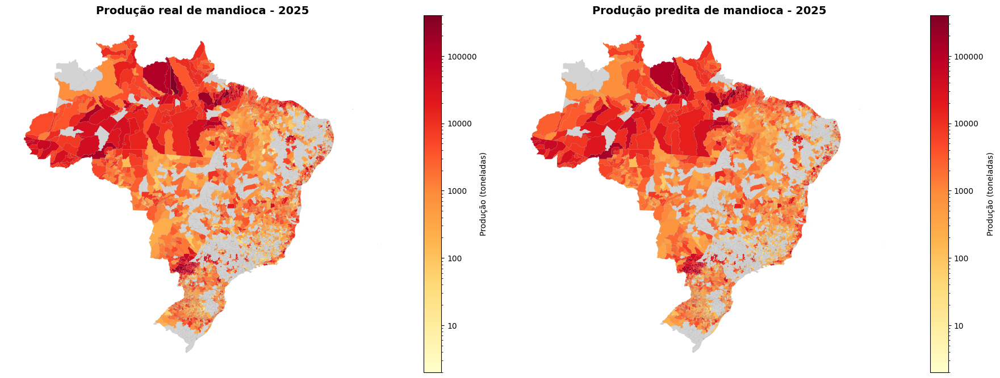

In [153]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Columnas que se van a representar
columnas = [
    'producao_real_2025',
    'producao_predita_2025'
]

titulos = [
    'Produção real de mandioca - 2025',
    'Produção predita de mandioca - 2025'
]

# Obtener escala común para ambos mapas
valores = gdf_2025[columnas].values.flatten()
valores = valores[np.isfinite(valores) & (valores > 0)]

vmin = valores.min()
vmax = valores.max()

norm = LogNorm(vmin=vmin, vmax=vmax)

# Crear figura
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

for ax, columna, titulo in zip(axes, columnas, titulos):

    gdf_2025.plot(
        column=columna,
        ax=ax,
        cmap='YlOrRd',
        norm=norm,
        edgecolor='gray',
        linewidth=0.05,
        legend=True,
        legend_kwds={
            'label': 'Produção (toneladas)',
            'shrink': 0.65,
            'format': '%.0f'
        },
        missing_kwds={
            'color': 'lightgray',
            'label': 'Sem dados'
        }
    )

    ax.set_title(titulo, fontsize=14, fontweight='bold')
    ax.set_axis_off()

plt.tight_layout()
plt.show()

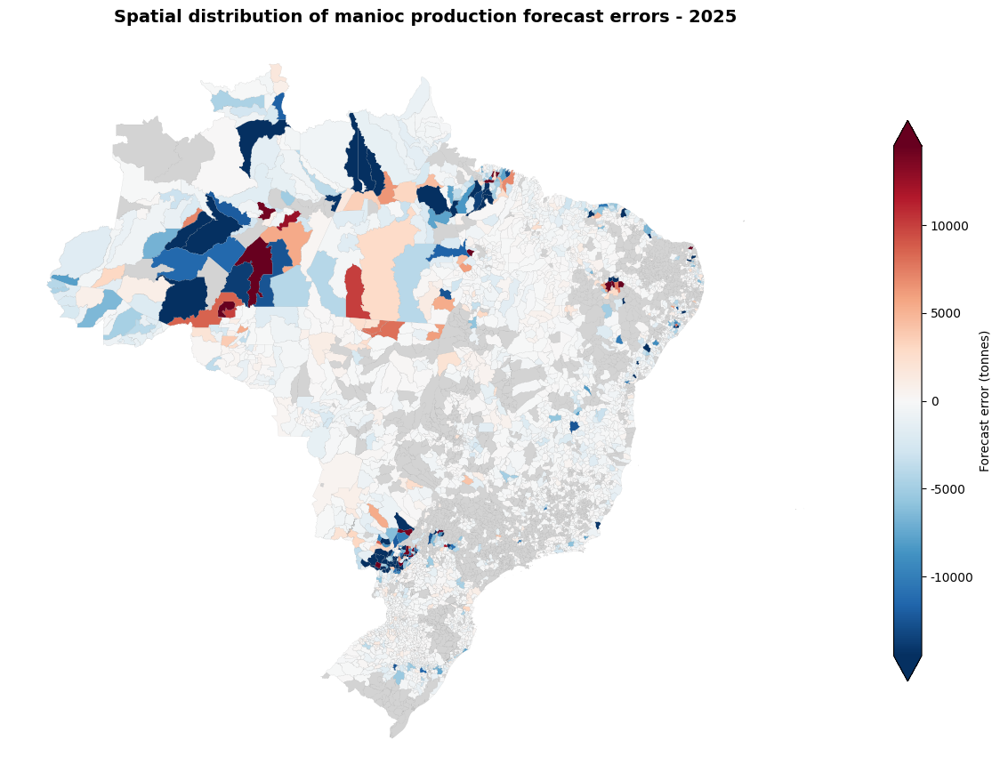

In [154]:
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np

# Calcular error firmado: predicción - valor real
gdf_2025['erro_predicao'] = (
    gdf_2025['producao_predita_2025'] -
    gdf_2025['producao_real_2025']
)

# Escala simétrica alrededor de cero
erros = gdf_2025['erro_predicao'].dropna()

limite = np.nanpercentile(np.abs(erros), 98)

norm = TwoSlopeNorm(
    vmin=-limite,
    vcenter=0,
    vmax=limite
)

# Crear figura
fig, ax = plt.subplots(figsize=(12, 10))

gdf_2025.plot(
    column='erro_predicao',
    ax=ax,
    cmap='RdBu_r',
    norm=norm,
    edgecolor='gray',
    linewidth=0.05,
    legend=True,
    legend_kwds={
        'label': 'Forecast error (tonnes)',
        'shrink': 0.65,
        'format': '%.0f',
        'extend': 'both'
    },
    missing_kwds={
        'color': 'lightgray',
        'label': 'Sem dados'
    }
)

ax.set_title(
    'Spatial distribution of manioc production forecast errors - 2025',
    fontsize=14,
    fontweight='bold'
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [155]:
# Recuperar las etiquetas de cluster correspondientes a 2025
clusters_2025 = (
    predicciones_test.loc[
        predicciones_test['ano'] == 2025,
        ['CD_MUN', 'cluster_climatico']
    ]
    .drop_duplicates(subset='CD_MUN')
)

# Asegurar que los códigos municipales tengan el mismo tipo
gdf_2025['CD_MUN'] = gdf_2025['CD_MUN'].astype(str)
clusters_2025['CD_MUN'] = clusters_2025['CD_MUN'].astype(str)

# Eliminar una columna anterior si existe
if 'cluster_climatico' in gdf_2025.columns:
    gdf_2025 = gdf_2025.drop(columns='cluster_climatico')

# Incorporar los clusters
gdf_2025 = gdf_2025.merge(
    clusters_2025,
    on='CD_MUN',
    how='left'
)

# Verificar
print("Municipios sin cluster:",
      gdf_2025['cluster_climatico'].isna().sum())

print("\nMunicipios por cluster:")
print(gdf_2025['cluster_climatico'].value_counts().sort_index())

Municipios sin cluster: 2026

Municipios por cluster:
cluster_climatico
0.0     459
1.0    1026
2.0    1086
3.0     976
Name: count, dtype: int64


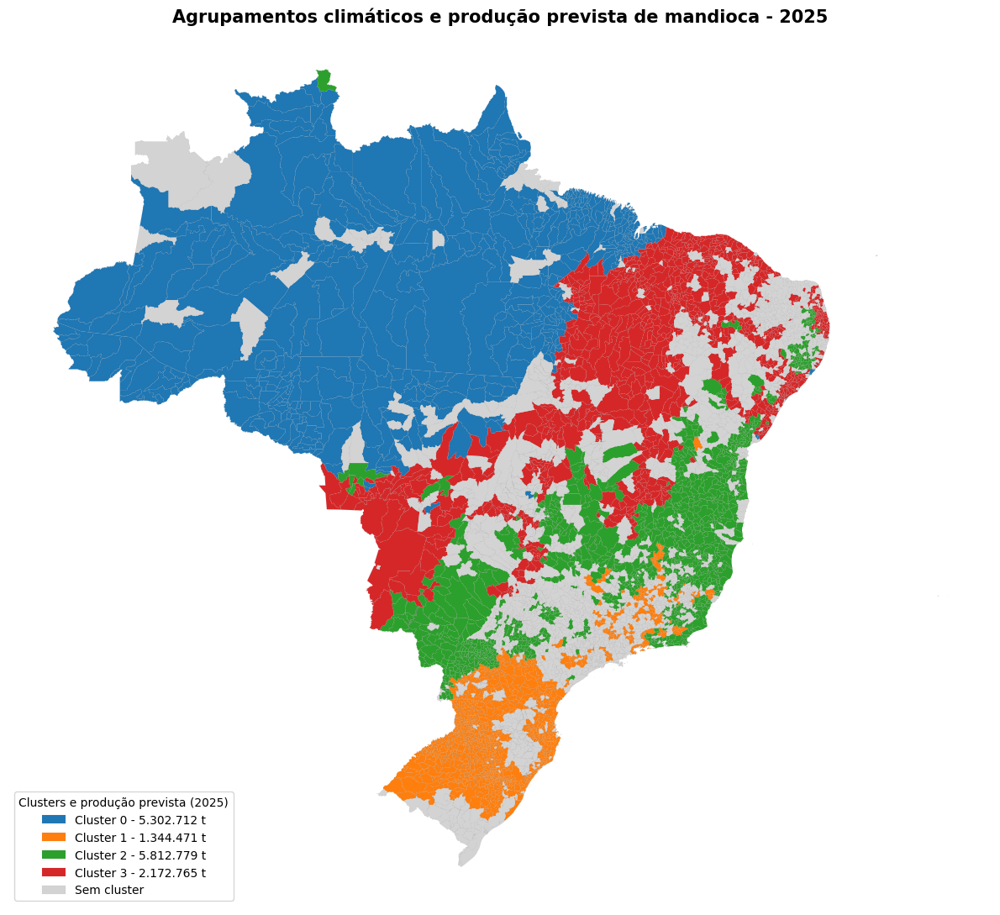

In [156]:
import matplotlib.pyplot as plt

# Calcular producción prevista total por cluster
producao_por_cluster = (
    gdf_2025.groupby('cluster_climatico')['producao_predita_2025']
    .sum()
)

# Crear etiquetas para la leyenda
rotulos = {}

for cluster, total in producao_por_cluster.items():
    rotulos[cluster] = (
        f'Cluster {int(cluster)} - '
        f'{total:,.0f} t'.replace(',', '.')
    )

# Crear columna categórica
gdf_2025['cluster_legenda'] = (
    gdf_2025['cluster_climatico'].map(rotulos)
)

# Crear mapa
fig, ax = plt.subplots(figsize=(13, 11))

gdf_2025.plot(
    column='cluster_legenda',
    ax=ax,
    categorical=True,
    cmap='tab10',
    edgecolor='gray',
    linewidth=0.05,
    legend=True,
    legend_kwds={
        'title': 'Clusters e produção prevista (2025)',
        'loc': 'lower left'
    },
    missing_kwds={
        'color': 'lightgray',
        'label': 'Sem cluster'
    }
)

ax.set_title(
    'Agrupamentos climáticos e produção prevista de mandioca - 2025',
    fontsize=15,
    fontweight='bold'
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

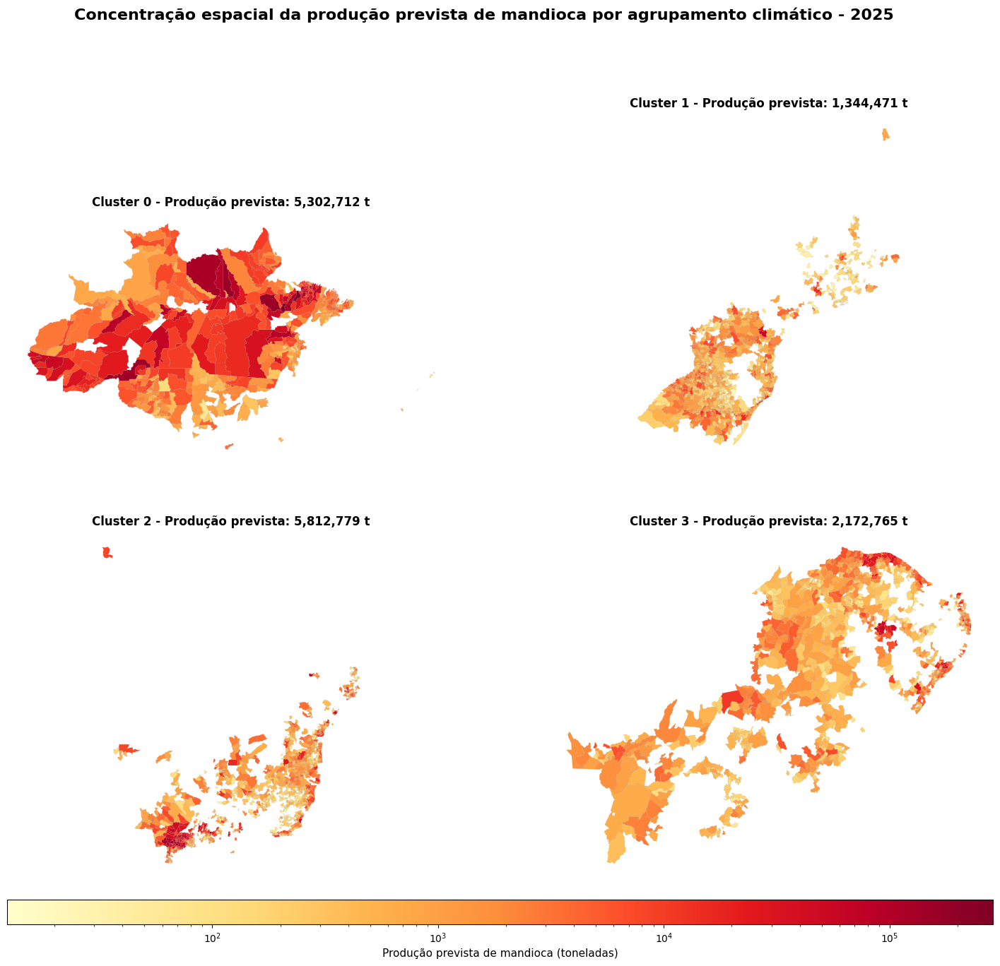

In [157]:

import matplotlib as mpl
from matplotlib.colors import LogNorm


# Obtener valores positivos de producción prevista
valores = gdf_2025['producao_predita_2025'].values

valores_validos = valores[
    np.isfinite(valores) & (valores > 0)
]

# Escala logarítmica
vmin = valores_validos.min()
vmax = valores_validos.max()

norm = LogNorm(vmin=vmin, vmax=vmax)

# Crear figura de cuatro paneles
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 15)
)

axes = axes.flatten()

for cluster, ax in zip(range(4), axes):

    # Seleccionar municipios del cluster
    gdf_cluster = gdf_2025[
        gdf_2025['cluster_climatico'] == cluster
    ]

    # Producción prevista total del cluster
    total = gdf_cluster['producao_predita_2025'].sum()

    # Mostrar municipios del cluster
    gdf_cluster.plot(
        column='producao_predita_2025',
        ax=ax,
        cmap='YlOrRd',
        norm=norm,
        edgecolor='gray',
        linewidth=0.05,
        legend=False,
        missing_kwds={
            'color': 'lightgray'
        }
    )

    ax.set_title(
        f'Cluster {cluster} - Produção prevista: {total:,.0f} t',
        fontsize=12,
        fontweight='bold'
    )

    ax.set_axis_off()

# Crear una única barra de colores compartida
sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap='YlOrRd'
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes.tolist(),
    orientation='horizontal',
    fraction=0.035,
    pad=0.025,
    aspect=40
)

cbar.set_label(
    'Produção prevista de mandioca (toneladas)',
    fontsize=11
)

fig.suptitle(
    'Concentração espacial da produção prevista de mandioca por agrupamento climático - 2025',
    fontsize=16,
    fontweight='bold'
)

plt.show()


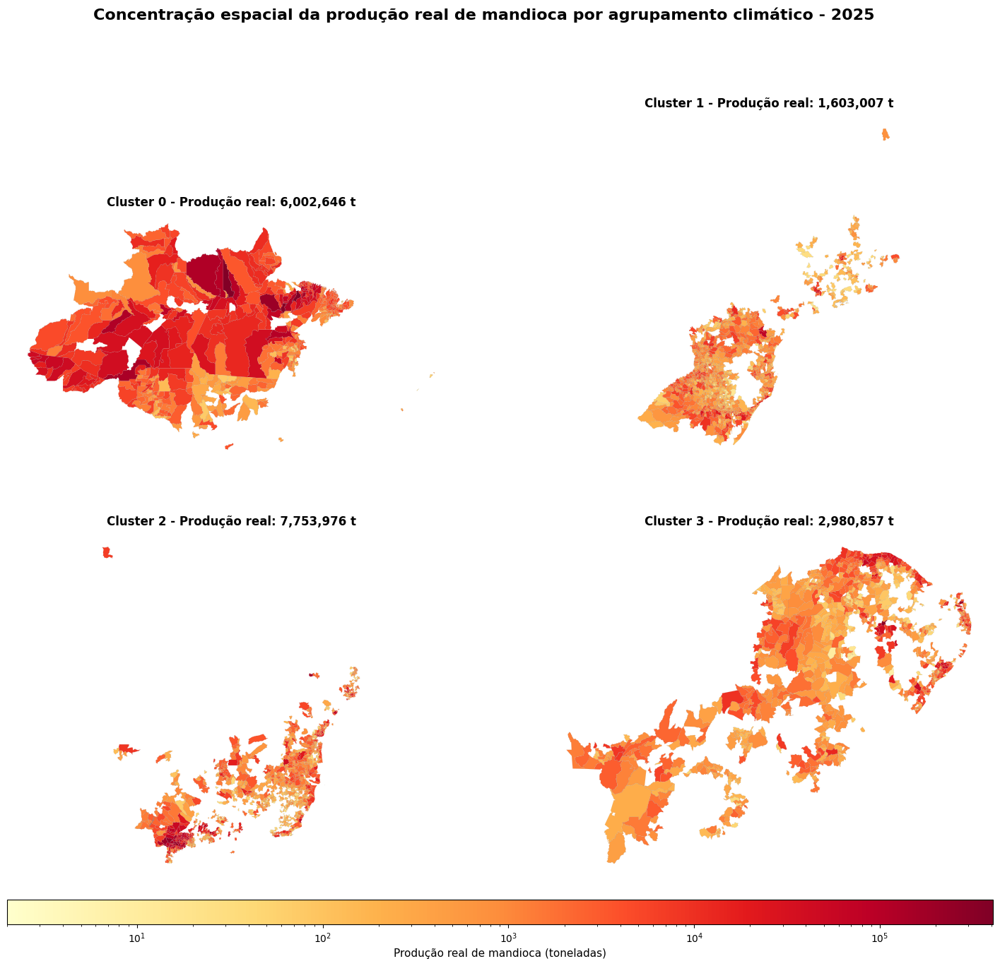

In [158]:
# Obtener valores positivos de producción real
valores = gdf_2025['producao_real_2025'].values

valores_validos = valores[
    np.isfinite(valores) & (valores > 0)
]

# Escala logarítmica común para los cuatro clusters
vmin = valores_validos.min()
vmax = valores_validos.max()

norm = LogNorm(vmin=vmin, vmax=vmax)

# Crear figura de cuatro paneles
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 15)
)

axes = axes.flatten()

for cluster, ax in zip(range(4), axes):

    # Seleccionar municipios del cluster
    gdf_cluster = gdf_2025[
        gdf_2025['cluster_climatico'] == cluster
    ]

    # Producción real total del cluster
    total = gdf_cluster['producao_real_2025'].sum()

    # Mostrar municipios del cluster
    gdf_cluster.plot(
        column='producao_real_2025',
        ax=ax,
        cmap='YlOrRd',
        norm=norm,
        edgecolor='gray',
        linewidth=0.05,
        legend=False,
        missing_kwds={
            'color': 'lightgray'
        }
    )

    ax.set_title(
        f'Cluster {cluster} - Produção real: {total:,.0f} t',
        fontsize=12,
        fontweight='bold'
    )

    ax.set_axis_off()

# Crear una única barra de colores compartida
sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap='YlOrRd'
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes.tolist(),
    orientation='horizontal',
    fraction=0.035,
    pad=0.025,
    aspect=40
)

cbar.set_label(
    'Produção real de mandioca (toneladas)',
    fontsize=11
)

fig.suptitle(
    'Concentração espacial da produção real de mandioca por agrupamento climático - 2025',
    fontsize=16,
    fontweight='bold'
)

plt.show()


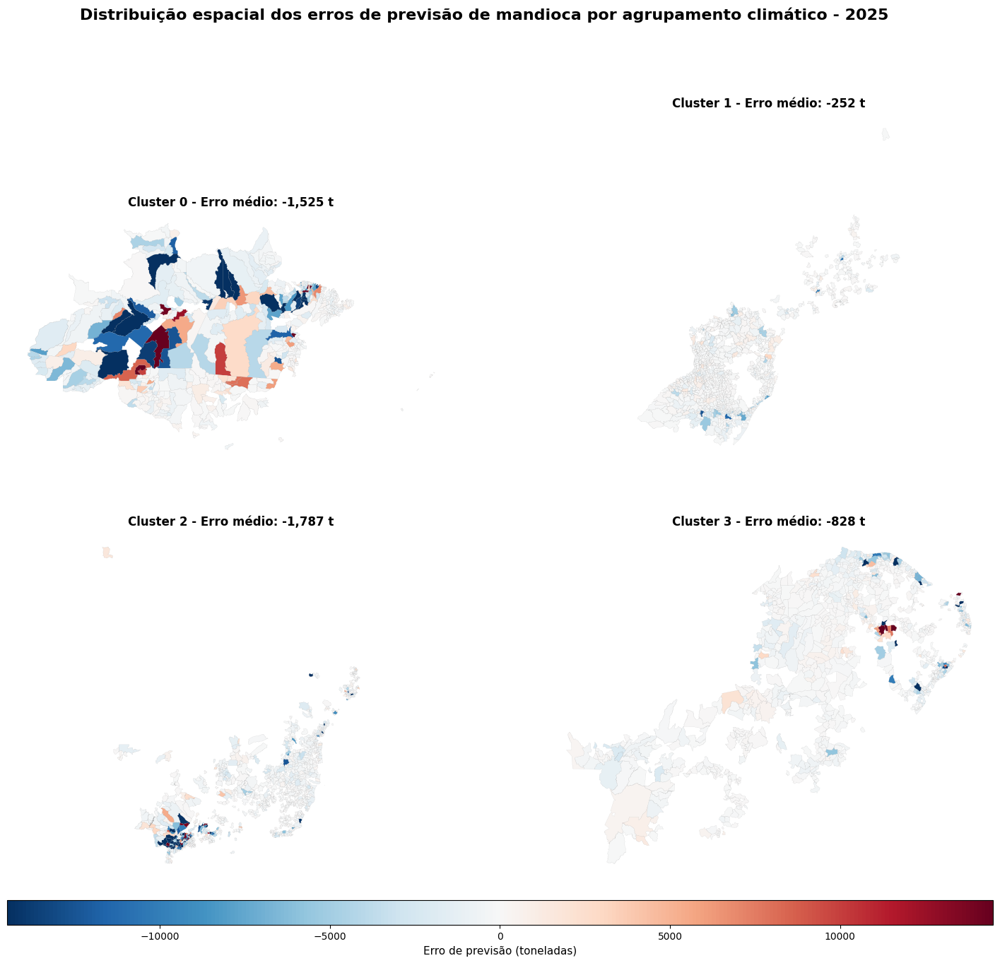

In [159]:
from matplotlib.colors import TwoSlopeNorm
# Calcular error firmado
gdf_2025['erro_predicao'] = (
    gdf_2025['producao_predita_2025'] -
    gdf_2025['producao_real_2025']
)

# Calcular límite simétrico para los cuatro mapas
erros = gdf_2025['erro_predicao'].values

erros_validos = erros[np.isfinite(erros)]

limite = np.nanpercentile(
    np.abs(erros_validos),
    98
)

norm = TwoSlopeNorm(
    vmin=-limite,
    vcenter=0,
    vmax=limite
)

# Crear figura de cuatro paneles
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 15)
)

axes = axes.flatten()

for cluster, ax in zip(range(4), axes):

    # Seleccionar municipios del cluster
    gdf_cluster = gdf_2025[
        gdf_2025['cluster_climatico'] == cluster
    ]

    # Calcular error medio del cluster
    erro_medio = gdf_cluster['erro_predicao'].mean()

    # Calcular error absoluto medio del cluster
    erro_absoluto_medio = gdf_cluster['erro_predicao'].abs().mean()

    # Representar errores municipales
    gdf_cluster.plot(
        column='erro_predicao',
        ax=ax,
        cmap='RdBu_r',
        norm=norm,
        edgecolor='gray',
        linewidth=0.05,
        legend=False,
        missing_kwds={
            'color': 'lightgray'
        }
    )

    ax.set_title(
        f'Cluster {cluster} - '
        f'Erro médio: {erro_medio:,.0f} t',
        fontsize=12,
        fontweight='bold'
    )

    ax.set_axis_off()

# Crear barra de colores compartida
sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap='RdBu_r'
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes.tolist(),
    orientation='horizontal',
    fraction=0.035,
    pad=0.025,
    aspect=40
)

cbar.set_label(
    'Erro de previsão (toneladas)',
    fontsize=11
)

fig.suptitle(
    'Distribuição espacial dos erros de previsão de mandioca por agrupamento climático - 2025',
    fontsize=16,
    fontweight='bold'
)

plt.show()


In [160]:
#Mapas so Clusters

In [161]:
# Obtener un cluster por municipio
df_clusters = (
    df_test_final[['CD_MUN', 'cluster_climatico']]
    .drop_duplicates(subset='CD_MUN')
)

# Homogeneizar códigos municipales
df_clusters['CD_MUN'] = (
    df_clusters['CD_MUN'].astype(str).str.zfill(7)
)

# Unir clusters con la malla municipal
gdf_clusters = malha_mun.merge(
    df_clusters,
    on='CD_MUN',
    how='inner'
)

print("Municipios incluidos:", len(gdf_clusters))
print("Clusters encontrados:")
print(gdf_clusters['cluster_climatico'].value_counts().sort_index())

Municipios incluidos: 3547
Clusters encontrados:
cluster_climatico
0     459
1    1026
2    1086
3     976
Name: count, dtype: int64


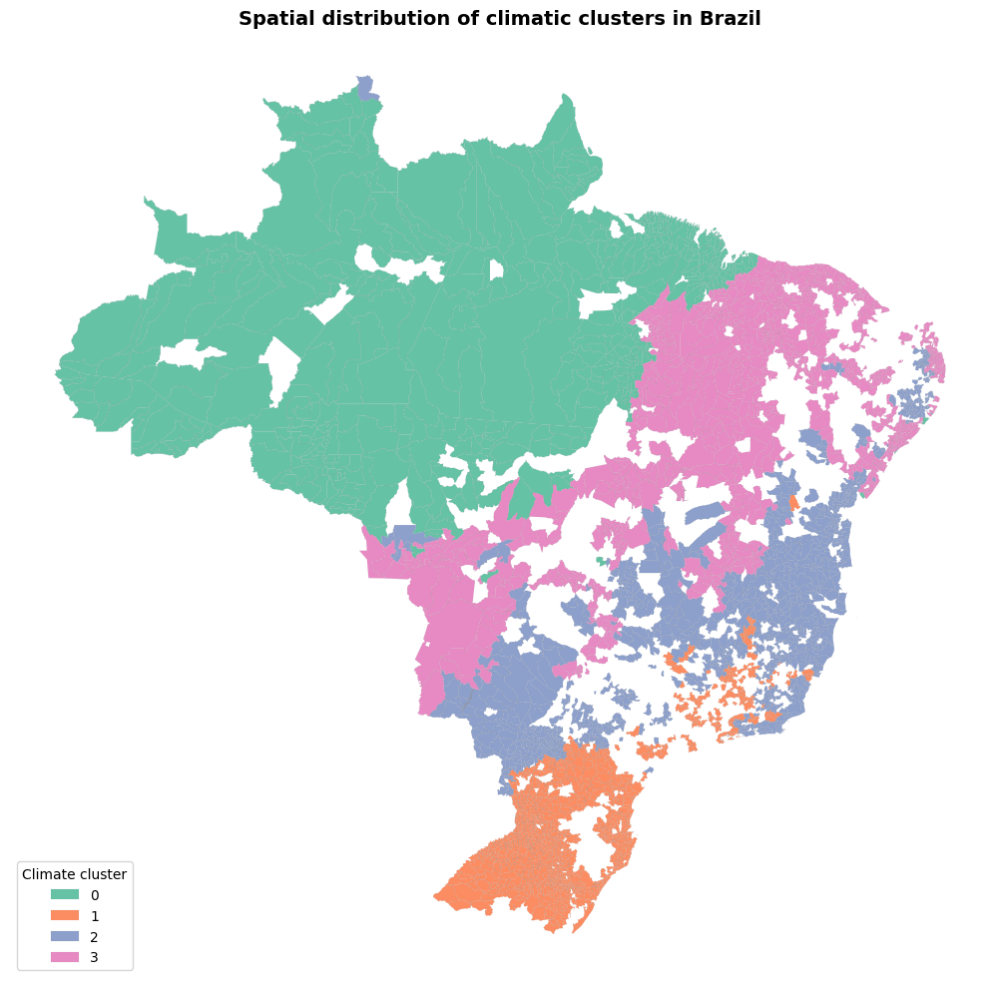

In [162]:
# Mapa da distribuição dos clusters climáticos

fig, ax = plt.subplots(1, 1, figsize=(12, 10))

gdf_clusters.plot(
    column='cluster_climatico',
    ax=ax,
    cmap='Set2',
    categorical=True,
    legend=True,
    edgecolor='gray',
    linewidth=0.05,
    legend_kwds={
        'title': 'Climate cluster',
        'loc': 'lower left'
    }
)

ax.set_title(
    'Spatial distribution of climatic clusters in Brazil',
    fontsize=14,
    fontweight='bold'
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## Modelo Tradicional Arima com pyramid ou pmdarima

---





In [164]:
%pip install pmdarima
try:
    import pmdarima
    print("pmdarima está instalada")
    print("Versión:", pmdarima.__version__)

except ImportError:
    print("pmdarima NO está instalada")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 7.1 MB/s  0:00:00
pmdarima está instalada
Versión: 2.1.1


In [165]:
df_arima = df_acr[
    ['CD_MUN', 'ano', 'mandioca_quantidade_produzida']
].copy()

df_arima['log_producao'] = np.log1p(
    df_arima['mandioca_quantidade_produzida']
)

df_arima = df_arima.sort_values(
    ['CD_MUN', 'ano']
).reset_index(drop=True)

print("Dimensiones:", df_arima.shape)
print("Municipios:", df_arima['CD_MUN'].nunique())
print("Años:", sorted(df_arima['ano'].unique()))
print(df_arima.head())

Dimensiones: (49658, 4)
Municipios: 3547
Años: [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
    CD_MUN   ano  mandioca_quantidade_produzida  log_producao
0  1100015  2012                         8736.0      9.075322
1  1100015  2013                        10920.0      9.298443
2  1100015  2014                        11320.0      9.334415
3  1100015  2015                        11320.0      9.334415
4  1100015  2016                        11320.0      9.334415


In [166]:
from pmdarima import auto_arima
resultados_auto_arima = []
errores_auto_arima = []
ordenes_auto_arima = []
tiempos_auto_arima = []


# Medir el tiempo total de ejecución
inicio_total = time.perf_counter()
municipios = df_arima['CD_MUN'].unique()

for i, (municipio, grupo) in enumerate(
    df_arima.groupby('CD_MUN'), start=1
):

    grupo = grupo.sort_values('ano')

    train = grupo[grupo['ano'] <= 2022]
    test = grupo[grupo['ano'] >= 2023]

    y_train = train['log_producao'].to_numpy()
    y_test = test['log_producao'].to_numpy()

    tiempo_entrenamiento = 0.0
    tiempo_prediccion = 0.0

    try:
        # Series constantes: pronóstico ingenuo
        if np.allclose(y_train, y_train[0]):

            metodo = 'Naive_constante'
            orden = None

            inicio = time.perf_counter()

            predicciones = np.repeat(
                y_train[-1], len(y_test)
            )

            tiempo_prediccion = (
                time.perf_counter() - inicio
            )

        else:
            # Selección automática y ajuste del ARIMA
            inicio = time.perf_counter()

            modelo = auto_arima(
                y_train,
                seasonal=False,
                stepwise=True,
                suppress_warnings=True,
                error_action='ignore',
                max_p=3,
                max_q=3,
                max_d=2,
                information_criterion='aic'
            )

            tiempo_entrenamiento = (
                time.perf_counter() - inicio
            )

            orden = modelo.order

            ordenes_auto_arima.append({
                'CD_MUN': municipio,
                'p': orden[0],
                'd': orden[1],
                'q': orden[2]
            })

            # Predicción secuencial:
            # predecir un año y actualizar con el valor real
            predicciones = []

            inicio = time.perf_counter()

            for valor_real in y_test:

                pred = modelo.predict(n_periods=1)[0]
                predicciones.append(float(pred))

                modelo.update(y=[float(valor_real)])

            tiempo_prediccion = (
                time.perf_counter() - inicio
            )

            metodo = 'Auto_ARIMA'

        # Guardar predicciones
        for j, (_, fila) in enumerate(test.iterrows()):

            resultados_auto_arima.append({
                'CD_MUN': municipio,
                'ano': int(fila['ano']),
                'real_log': y_test[j],
                'pred_log': predicciones[j],
                'real': fila['mandioca_quantidade_produzida'],
                'pred': np.expm1(predicciones[j]),
                'metodo': metodo,
                'orden': str(orden) if orden else 'Naive_constante'
            })

        # Guardar tiempos por municipio
        tiempos_auto_arima.append({
            'CD_MUN': municipio,
            'metodo': metodo,
            'n_registros_teste': len(y_test),
            'tempo_treinamento_s': tiempo_entrenamiento,
            'tempo_predicao_s': tiempo_prediccion
        })

    except Exception as e:

        errores_auto_arima.append({
            'CD_MUN': municipio,
            'error': str(e)
        })

    if i % 250 == 0:
        print(f"Municipios procesados: {i}/{len(municipios)}")

# Tiempo total de procesamiento
tempo_execucao_total = time.perf_counter() - inicio_total
# Crear DataFrames
df_resultados_auto_arima = pd.DataFrame(
    resultados_auto_arima
)

df_ordenes_auto_arima = pd.DataFrame(
    ordenes_auto_arima
)

df_tiempos_auto_arima = pd.DataFrame(
    tiempos_auto_arima
)

print("\nPROCESAMIENTO FINALIZADO")

print("Municipios procesados:",
      df_resultados_auto_arima['CD_MUN'].nunique())

print("Predicciones generadas:",
      len(df_resultados_auto_arima))

print("Municipios con errores:",
      len(errores_auto_arima))

print("\nMétodos utilizados:")
print(df_resultados_auto_arima['metodo'].value_counts())

print("\nÓrdenes ARIMA más frecuentes:")
print(
    df_ordenes_auto_arima[['p', 'd', 'q']]
    .value_counts()
    .head(15)
)


Municipios procesados: 250/3547
Municipios procesados: 500/3547
Municipios procesados: 750/3547
Municipios procesados: 1000/3547
Municipios procesados: 1250/3547
Municipios procesados: 1500/3547
Municipios procesados: 1750/3547
Municipios procesados: 2000/3547
Municipios procesados: 2250/3547
Municipios procesados: 2500/3547
Municipios procesados: 2750/3547
Municipios procesados: 3000/3547
Municipios procesados: 3250/3547
Municipios procesados: 3500/3547

PROCESAMIENTO FINALIZADO
Municipios procesados: 3547
Predicciones generadas: 10641
Municipios con errores: 0

Métodos utilizados:
metodo
Auto_ARIMA         10512
Naive_constante      129
Name: count, dtype: int64

Órdenes ARIMA más frecuentes:
p  d  q
1  0  0    1306
0  0  0    1009
1  0  1     371
0  0  1     260
2  0  0     135
0  1  0      93
1  0  2      72
0  0  2      62
2  0  1      61
      2      24
3  0  0      21
1  1  0      20
3  0  1      19
0  1  1      11
2  1  2       8
Name: count, dtype: int64


In [167]:
# Resumen de tiempos de Auto-ARIMA
tempo_treinamento_total = (
    df_tiempos_auto_arima['tempo_treinamento_s'].sum()
)

tempo_predicao_total = (
    df_tiempos_auto_arima['tempo_predicao_s'].sum()
)

municipios_processados = (
    df_tiempos_auto_arima['CD_MUN'].nunique()
)

tabela_tempo_auto_arima = pd.DataFrame({
    'Modelo': ['Auto-ARIMA'],
    'Municipios processados': [municipios_processados],
    'Treinamento (s)': [tempo_treinamento_total],
    'Previssão (s)': [tempo_predicao_total],
    'Tempo total de execução (s)': [tempo_execucao_total],
    'Tempo médio por município (s)': [
        tempo_execucao_total / municipios_processados
    ]
})

display(tabela_tempo_auto_arima.round(2))


,Modelo,Municipios processados,Treinamento (s),Previssão (s),Tempo total de execução (s),Tempo médio por município (s)
0,Auto-ARIMA,3547,4626.95,274.51,4910.25,1.38


In [168]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
# Evaluación general 2023-2025
y_real = df_resultados_auto_arima['real']
y_pred = df_resultados_auto_arima['pred']

metricas_auto_general = {
    'Modelo': 'Auto ARIMA',
    'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
    'MAE': mean_absolute_error(y_real, y_pred),
    'R2': r2_score(y_real, y_pred)
}

print("RESULTADOS GENERALES 2023-2025")
print(pd.DataFrame([metricas_auto_general]).round(4))

# Evaluación por año
resultados_anuales = []

for ano, grupo in df_resultados_auto_arima.groupby('ano'):

    y_real = grupo['real']
    y_pred = grupo['pred']

    resultados_anuales.append({
        'Ano': ano,
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'MAE': mean_absolute_error(y_real, y_pred),
        'R2': r2_score(y_real, y_pred)
    })

df_metricas_auto_anual = pd.DataFrame(resultados_anuales)

print("\nRESULTADOS POR AÑO")
print(df_metricas_auto_anual.round(4).to_string(index=False))

# Verificar municipios por método
print("\nMUNICIPIOS POR MÉTODO")
print(
    df_resultados_auto_arima
    .groupby('CD_MUN')['metodo']
    .first()
    .value_counts()
)


RESULTADOS GENERALES 2023-2025
       Modelo       RMSE        MAE      R2
0  Auto ARIMA  8029.2243  1623.4778  0.7952

RESULTADOS POR AÑO
 Ano      RMSE       MAE     R2
2023 6656.5405 1439.4476 0.8172
2024 7650.1913 1569.1146 0.8175
2025 9516.8467 1861.8712 0.7624

MUNICIPIOS POR MÉTODO
metodo
Auto_ARIMA         3504
Naive_constante      43
Name: count, dtype: int64
